<a href="https://colab.research.google.com/github/contactvarun2002/Port-work/blob/main/Port_Work.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# ============================================================
# ANOMALY DATASET PREPROCESSING — COMPLETE COLAB CODE
#
# Input:
# /content/drive/MyDrive/Port Work/Synthetic_Anomaly_Dataset
#
# Expected package structure:
#   anomaly/
#       train_labels.csv
#       validation_labels.csv
#       test_labels.csv
#   sequences/
#       train_sequences.npz
#       validation_sequences.npz
#       test_sequences.npz
#
# Output:
# /content/drive/MyDrive/Port Work/Anomaly_Preprocessed
#
# Data is SYNTHETIC. Counts refer to 100-step sensor windows.
# ============================================================

from pathlib import Path
from itertools import combinations
import hashlib
import json

import numpy as np
import pandas as pd

from google.colab import drive


# ============================================================
# 1. CONFIGURATION
# ============================================================

INPUT_ROOT = Path(
    "/content/drive/MyDrive/Port Work/Synthetic_Anomaly_Dataset"
)

OUTPUT_ROOT = Path(
    "/content/drive/MyDrive/Port Work/Anomaly_Preprocessed"
)

EXPECTED_COUNTS = {
    "train":      {0: 13000, 1: 1000},
    "validation": {0: 2785,  1: 215},
    "test":       {0: 2785,  1: 215},
}

FEATURES = [
    "pressure_bar",
    "temperature_c",
    "vibration_mm_s",
    "speed_kmh",
    "torque_nm",
    "inclination_deg",
    "acceleration_m_s2",
    "ambient_temperature_c",
]

TIME_STEPS = 100
SAMPLING_INTERVAL_SECONDS = 0.1

# No smoothing or clipping: preserve potential anomaly spikes.


# ============================================================
# 2. CONNECT GOOGLE DRIVE
# ============================================================

if not Path("/content/drive/MyDrive").is_dir():
    drive.mount("/content/drive", force_remount=False)

if not INPUT_ROOT.is_dir():
    raise FileNotFoundError(
        f"Input folder does not exist:\n{INPUT_ROOT}\n"
        "Extract Synthetic_Anomaly_Dataset.zip into this folder."
    )


# ============================================================
# 3. LOCATE THE EXTRACTED DATASET
# Handles one or more extra nesting folders.
# ============================================================

def is_dataset_folder(folder):
    return all(
        (folder / "anomaly" / f"{split}_labels.csv").is_file()
        and
        (folder / "sequences" / f"{split}_sequences.npz").is_file()
        for split in EXPECTED_COUNTS
    )


if is_dataset_folder(INPUT_ROOT):
    DATA_ROOT = INPUT_ROOT
else:
    candidates = []

    for label_file in INPUT_ROOT.rglob("train_labels.csv"):
        if label_file.parent.name == "anomaly":
            candidate = label_file.parent.parent

            if is_dataset_folder(candidate):
                candidates.append(candidate)

    candidates = list(dict.fromkeys(candidates))

    if len(candidates) != 1:
        raise FileNotFoundError(
            "Could not identify exactly one complete anomaly dataset.\n"
            "The folder must contain anomaly/*.csv and sequences/*.npz.\n"
            f"Complete datasets found: {len(candidates)}"
        )

    DATA_ROOT = candidates[0]

print("Dataset folder:", DATA_ROOT)


# ============================================================
# 4. LOAD AND VALIDATE LABELS AND SENSOR SEQUENCES
# ============================================================

datasets = {}
equipment_sets = {}
window_sets = {}
sequence_hash_sets = {}

report = {
    "data_origin": "synthetic demonstration",
    "input_folder": str(DATA_ROOT),
    "feature_names": FEATURES,
    "window_length": TIME_STEPS,
    "sampling_interval_seconds": SAMPLING_INTERVAL_SECONDS,
    "preprocessing_fit_subset": "normal training windows only",
    "smoothing": "disabled",
    "splits": {},
}

for split, expected in EXPECTED_COUNTS.items():

    labels_path = DATA_ROOT / "anomaly" / f"{split}_labels.csv"
    sequences_path = DATA_ROOT / "sequences" / f"{split}_sequences.npz"

    labels = pd.read_csv(
        labels_path,
        dtype={
            "window_id": str,
            "equipment_id": str,
        },
    )

    required_columns = [
        "window_id",
        "equipment_id",
        "window_start",
        "window_end",
        "split",
        "is_synthetic",
        "label",
        "class_name",
    ]

    missing_columns = [
        column
        for column in required_columns
        if column not in labels.columns
    ]

    if missing_columns:
        raise ValueError(
            f"{split}: missing columns: {missing_columns}"
        )

    if labels[required_columns].isna().any().any():
        raise ValueError(
            f"{split}: missing identifiers, timestamps, or labels."
        )

    if labels["window_id"].duplicated().any():
        raise ValueError(
            f"{split}: duplicate window IDs detected."
        )

    if not labels["split"].eq(split).all():
        raise ValueError(
            f"{split}: incorrect split values in label CSV."
        )

    synthetic_flags = (
        labels["is_synthetic"]
        .astype(str)
        .str.strip()
        .str.lower()
    )

    if not synthetic_flags.eq("true").all():
        raise ValueError(
            f"{split}: expected synthetic dataset provenance."
        )

    numeric_labels = pd.to_numeric(
        labels["label"],
        errors="raise",
    )

    if not numeric_labels.isin([0, 1]).all():
        raise ValueError(
            f"{split}: labels must be 0=Normal or 1=Anomalous."
        )

    labels["label"] = numeric_labels.astype(np.int64)

    with np.load(
        sequences_path,
        allow_pickle=False,
    ) as stored:

        required_arrays = {
            "X",
            "window_id",
            "equipment_id",
            "feature_names",
        }

        if not required_arrays.issubset(stored.files):
            raise ValueError(
                f"{split}: NPZ is missing required arrays."
            )

        X = stored["X"].astype(np.float32)
        sequence_ids = stored["window_id"].astype(str)
        sequence_equipment = stored["equipment_id"].astype(str)
        feature_names = stored["feature_names"].astype(str).tolist()

    expected_rows = sum(expected.values())

    if X.shape != (expected_rows, TIME_STEPS, len(FEATURES)):
        raise ValueError(
            f"{split}: unexpected X shape {X.shape}.\n"
            f"Expected {(expected_rows, TIME_STEPS, len(FEATURES))}"
        )

    if feature_names != FEATURES:
        raise ValueError(
            f"{split}: sensor names or ordering differ.\n"
            f"Found: {feature_names}"
        )

    if (
        len(sequence_ids) != len(X)
        or len(sequence_equipment) != len(X)
    ):
        raise ValueError(
            f"{split}: sequence identifiers have incorrect lengths."
        )

    if len(set(sequence_ids)) != len(sequence_ids):
        raise ValueError(
            f"{split}: duplicate IDs in sequence arrays."
        )

    if set(sequence_ids) != set(labels["window_id"]):
        raise ValueError(
            f"{split}: sequence IDs do not match label IDs."
        )

    # Align CSV rows to NPZ sequence ordering using identifiers.
    labels = (
        labels
        .set_index("window_id")
        .loc[sequence_ids]
        .reset_index()
    )

    if not np.array_equal(
        sequence_equipment,
        labels["equipment_id"].to_numpy(),
    ):
        raise ValueError(
            f"{split}: equipment IDs disagree between CSV and NPZ."
        )

    y = labels["label"].to_numpy(dtype=np.int64)

    actual_counts = {
        0: int(np.sum(y == 0)),
        1: int(np.sum(y == 1)),
    }

    if actual_counts != expected:
        raise ValueError(
            f"{split}: class counts differ.\n"
            f"Expected: {expected}\n"
            f"Found: {actual_counts}"
        )

    expected_names = np.where(
        y == 0,
        "Normal",
        "Anomalous",
    )

    if not np.array_equal(
        labels["class_name"].to_numpy(),
        expected_names,
    ):
        raise ValueError(
            f"{split}: class names disagree with numeric labels."
        )

    starts = pd.to_datetime(
        labels["window_start"],
        utc=True,
        errors="raise",
    )

    ends = pd.to_datetime(
        labels["window_end"],
        utc=True,
        errors="raise",
    )

    expected_duration = (
        TIME_STEPS - 1
    ) * SAMPLING_INTERVAL_SECONDS

    durations = (ends - starts).dt.total_seconds()

    if not np.allclose(durations, expected_duration):
        raise ValueError(
            f"{split}: unexpected window timestamp duration."
        )

    # Verify non-overlapping windows within each machine.
    time_table = pd.DataFrame({
        "equipment_id": sequence_equipment,
        "start": starts,
        "end": ends,
    })

    for equipment_id, group in time_table.groupby("equipment_id"):

        group = group.sort_values("start")

        later_starts = group["start"].iloc[1:].to_numpy()
        earlier_ends = group["end"].iloc[:-1].to_numpy()

        if np.any(later_starts <= earlier_ends):
            raise ValueError(
                f"{split}: overlapping windows for {equipment_id}."
            )

    # Detect exact repeated complete windows.
    # Repeated scalar sensor values are allowed.
    hashes = [
        hashlib.sha256(
            np.ascontiguousarray(window).tobytes()
        ).hexdigest()
        for window in X
    ]

    if len(set(hashes)) != len(hashes):
        raise ValueError(
            f"{split}: duplicate complete sensor windows found. "
            "Investigate them before changing dataset counts."
        )

    invalid_mask = ~np.isfinite(X)
    invalid_count = int(invalid_mask.sum())

    # Convert NaN and infinity to one missing-value representation.
    X[invalid_mask] = np.nan

    datasets[split] = {
        "X": X,
        "y": y,
        "manifest": labels,
    }

    equipment_sets[split] = set(sequence_equipment)
    window_sets[split] = set(sequence_ids)
    sequence_hash_sets[split] = set(hashes)

    report["splits"][split] = {
        "input_shape": list(X.shape),
        "normal": actual_counts[0],
        "anomalous": actual_counts[1],
        "equipment_count": len(equipment_sets[split]),
        "missing_or_infinite_values": invalid_count,
    }

    print(
        f"{split}: {X.shape} | "
        f"Normal={actual_counts[0]} | "
        f"Anomalous={actual_counts[1]}"
    )


# ============================================================
# 5. CHECK FOR LEAKAGE BETWEEN SPLITS
# ============================================================

for first, second in combinations(EXPECTED_COUNTS, 2):

    if equipment_sets[first] & equipment_sets[second]:
        raise ValueError(
            f"Equipment overlap between {first} and {second}."
        )

    if window_sets[first] & window_sets[second]:
        raise ValueError(
            f"Window-ID overlap between {first} and {second}."
        )

    if sequence_hash_sets[first] & sequence_hash_sets[second]:
        raise ValueError(
            f"Identical sensor sequences appear in "
            f"{first} and {second}."
        )

print("Passed equipment, window, and duplicate leakage checks.")


# ============================================================
# 6. FIT IMPUTATION ON NORMAL TRAINING DATA ONLY
# ============================================================

train_X = datasets["train"]["X"]
train_y = datasets["train"]["y"]

normal_training = train_X[train_y == 0].reshape(
    -1,
    len(FEATURES),
)

valid_per_feature = np.sum(
    np.isfinite(normal_training),
    axis=0,
)

if np.any(valid_per_feature == 0):

    unavailable = [
        FEATURES[index]
        for index in np.flatnonzero(valid_per_feature == 0)
    ]

    raise ValueError(
        "No valid normal-training measurements for: "
        f"{unavailable}"
    )

imputation_mean = np.nanmean(
    normal_training,
    axis=0,
    dtype=np.float64,
)

normal_training_imputed = np.where(
    np.isnan(normal_training),
    imputation_mean,
    normal_training,
)


# ============================================================
# 7. FIT STANDARDIZATION ON NORMAL TRAINING DATA ONLY
# ============================================================

scaler_mean = normal_training_imputed.mean(
    axis=0,
    dtype=np.float64,
)

scaler_std = normal_training_imputed.std(
    axis=0,
    dtype=np.float64,
)

constant_features = scaler_std < 1e-12

# Avoid division by zero for constant channels.
scaler_std[constant_features] = 1.0

OUTPUT_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)

np.savez(
    OUTPUT_ROOT / "preprocessing_parameters.npz",
    imputation_mean=imputation_mean,
    scaler_mean=scaler_mean,
    scaler_std=scaler_std,
    feature_names=np.asarray(FEATURES),
)

report["constant_features"] = [
    FEATURES[index]
    for index in np.flatnonzero(constant_features)
]


# ============================================================
# 8. TRANSFORM AND SAVE ALL SPLITS
# ============================================================

for split, data in datasets.items():

    X = data["X"]
    y = data["y"]
    manifest = data["manifest"]

    X_imputed = np.where(
        np.isnan(X),
        imputation_mean,
        X,
    )

    X_scaled = (
        (X_imputed - scaler_mean) / scaler_std
    ).astype(np.float32)

    if not np.isfinite(X_scaled).all():
        raise ValueError(
            f"{split}: non-finite values remain after preprocessing."
        )

    window_ids = manifest["window_id"].to_numpy(dtype=str)
    equipment_ids = manifest["equipment_id"].to_numpy(dtype=str)

    np.savez_compressed(
        OUTPUT_ROOT / f"{split}_mamba.npz",
        X=X_scaled,
        y=y,
        window_id=window_ids,
        equipment_id=equipment_ids,
        feature_names=np.asarray(FEATURES),
    )

    manifest.to_csv(
        OUTPUT_ROOT / f"{split}_manifest.csv",
        index=False,
    )

    if split == "train":

        normal_mask = y == 0

        np.savez_compressed(
            OUTPUT_ROOT / "train_normal_autoencoder.npz",
            X=X_scaled[normal_mask],
            window_id=window_ids[normal_mask],
            equipment_id=equipment_ids[normal_mask],
            feature_names=np.asarray(FEATURES),
        )

    report["splits"][split]["output_shape"] = list(
        X_scaled.shape
    )

    print(f"Saved {split}_mamba.npz: {X_scaled.shape}")


# ============================================================
# 9. SAVE REPORT AND FEATURE STATISTICS
# ============================================================

statistics = pd.DataFrame({
    "feature": FEATURES,
    "imputation_mean": imputation_mean,
    "scaler_mean": scaler_mean,
    "scaler_std": scaler_std,
    "constant_in_normal_training": constant_features,
})

statistics.to_csv(
    OUTPUT_ROOT / "training_preprocessing_statistics.csv",
    index=False,
)

with open(
    OUTPUT_ROOT / "preprocessing_report.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        report,
        file,
        indent=2,
    )

print("\nPREPROCESSING COMPLETED")
print("Output folder:", OUTPUT_ROOT)
print("Labels: 0 = Normal, 1 = Anomalous")
print("Mamba input layout: batch, time steps, sensor features")
print("Data origin: SYNTHETIC")
print("Next stage: Mamba temporal representation learning.")

Dataset folder: /content/drive/MyDrive/Port Work/Synthetic_Anomaly_Dataset
train: (14000, 100, 8) | Normal=13000 | Anomalous=1000
validation: (3000, 100, 8) | Normal=2785 | Anomalous=215
test: (3000, 100, 8) | Normal=2785 | Anomalous=215
Passed equipment, window, and duplicate leakage checks.
Saved train_mamba.npz: (14000, 100, 8)
Saved validation_mamba.npz: (3000, 100, 8)
Saved test_mamba.npz: (3000, 100, 8)

PREPROCESSING COMPLETED
Output folder: /content/drive/MyDrive/Port Work/Anomaly_Preprocessed
Labels: 0 = Normal, 1 = Anomalous
Mamba input layout: batch, time steps, sensor features
Data origin: SYNTHETIC
Next stage: Mamba temporal representation learning.


Inspecting: train
Inspecting: validation
Inspecting: test

VERIFIED DATASET SUMMARY
     split  windows  normal  anomalous  time_steps  channels  sensor_readings  equipment  missing_values  infinite_values
     train    14000   13000       1000         100         8          1400000         20               0                0
validation     3000    2785        215         100         8           300000         20               0                0
      test     3000    2785        215         100         8           300000         20               0                0

Total windows: 20000


,split,windows,normal,anomalous,time_steps,channels,sensor_readings,equipment,missing_values,infinite_values
0,train,14000,13000,1000,100,8,1400000,20,0,0
1,validation,3000,2785,215,100,8,300000,20,0,0
2,test,3000,2785,215,100,8,300000,20,0,0


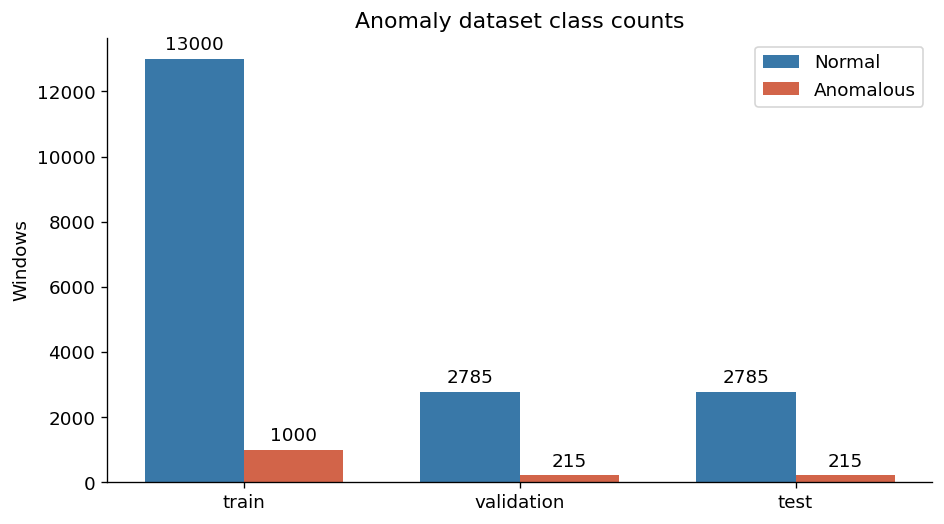

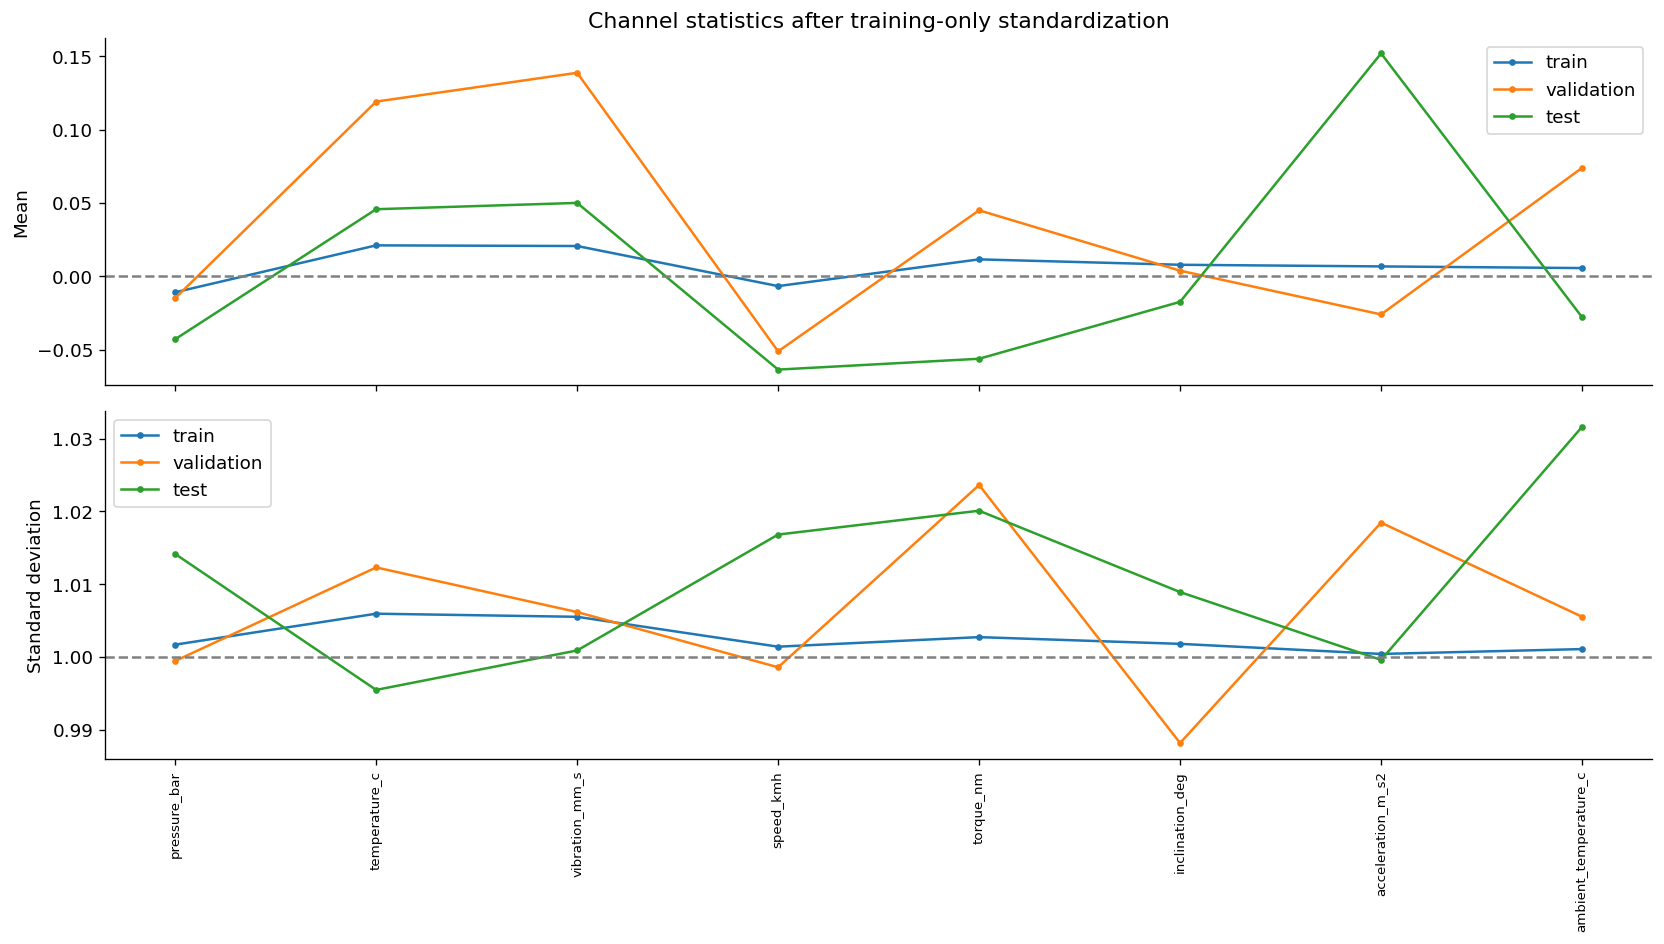

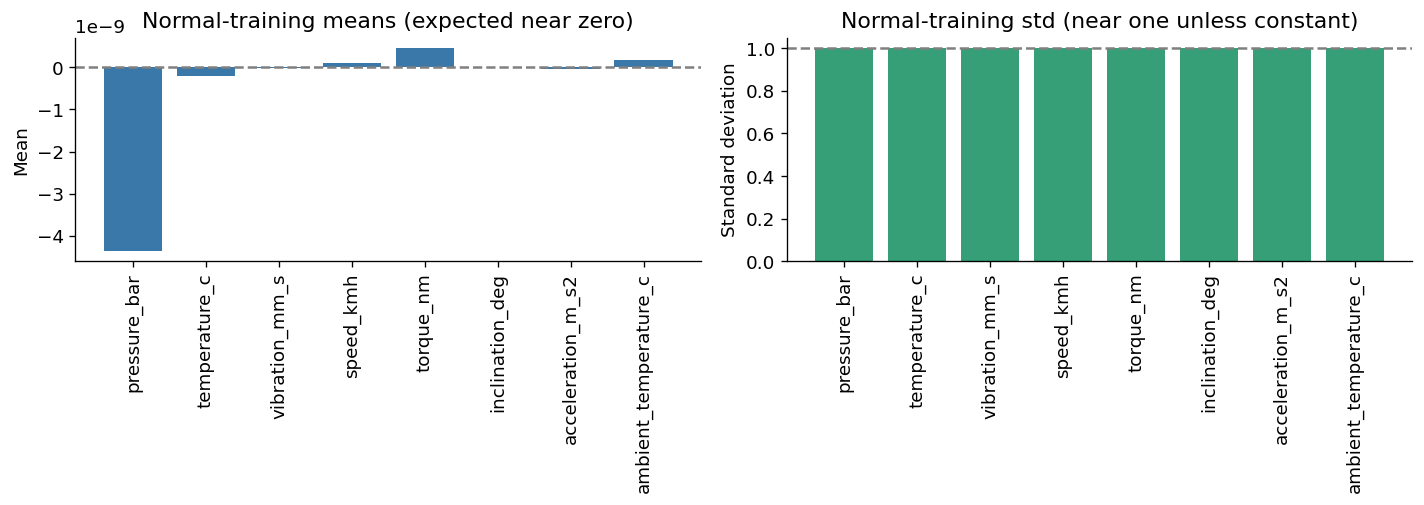

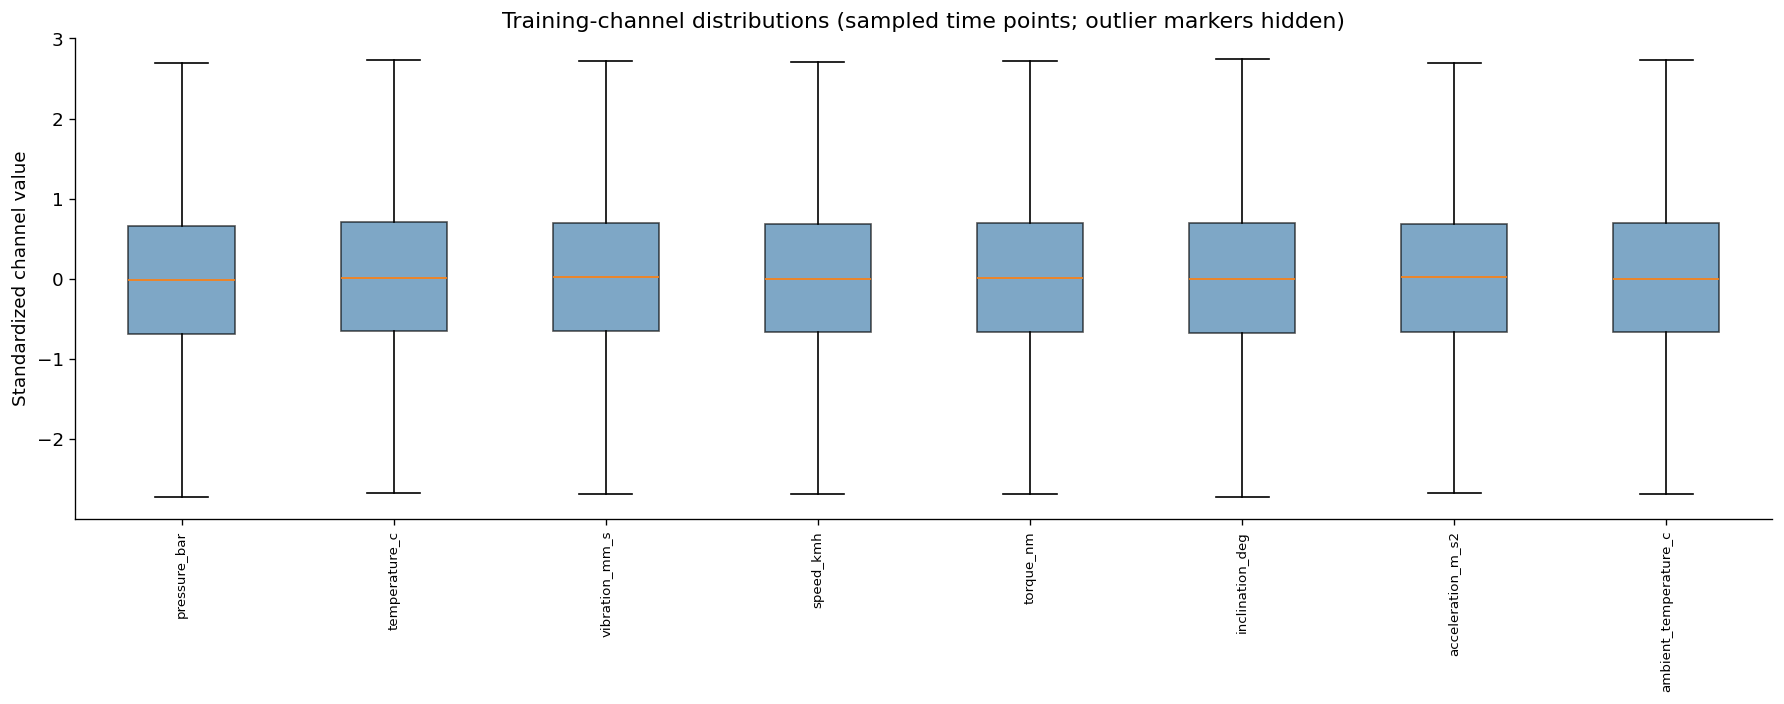

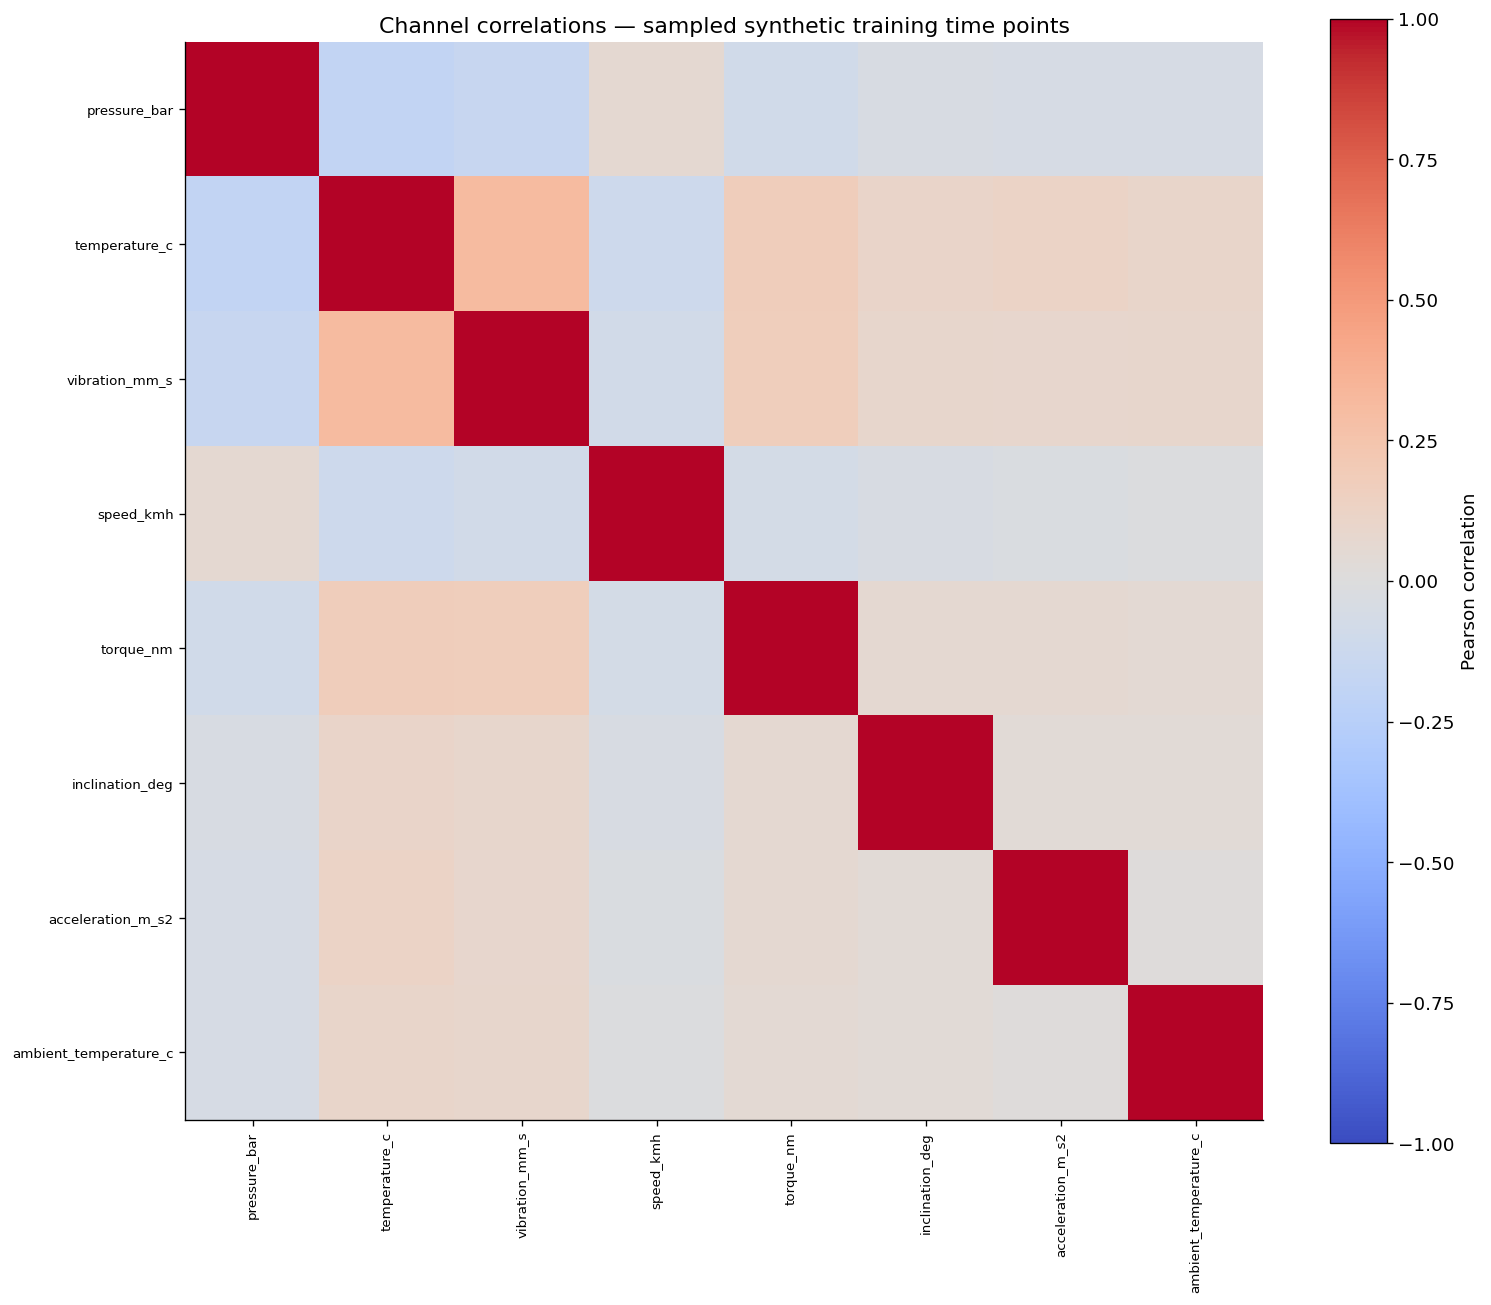

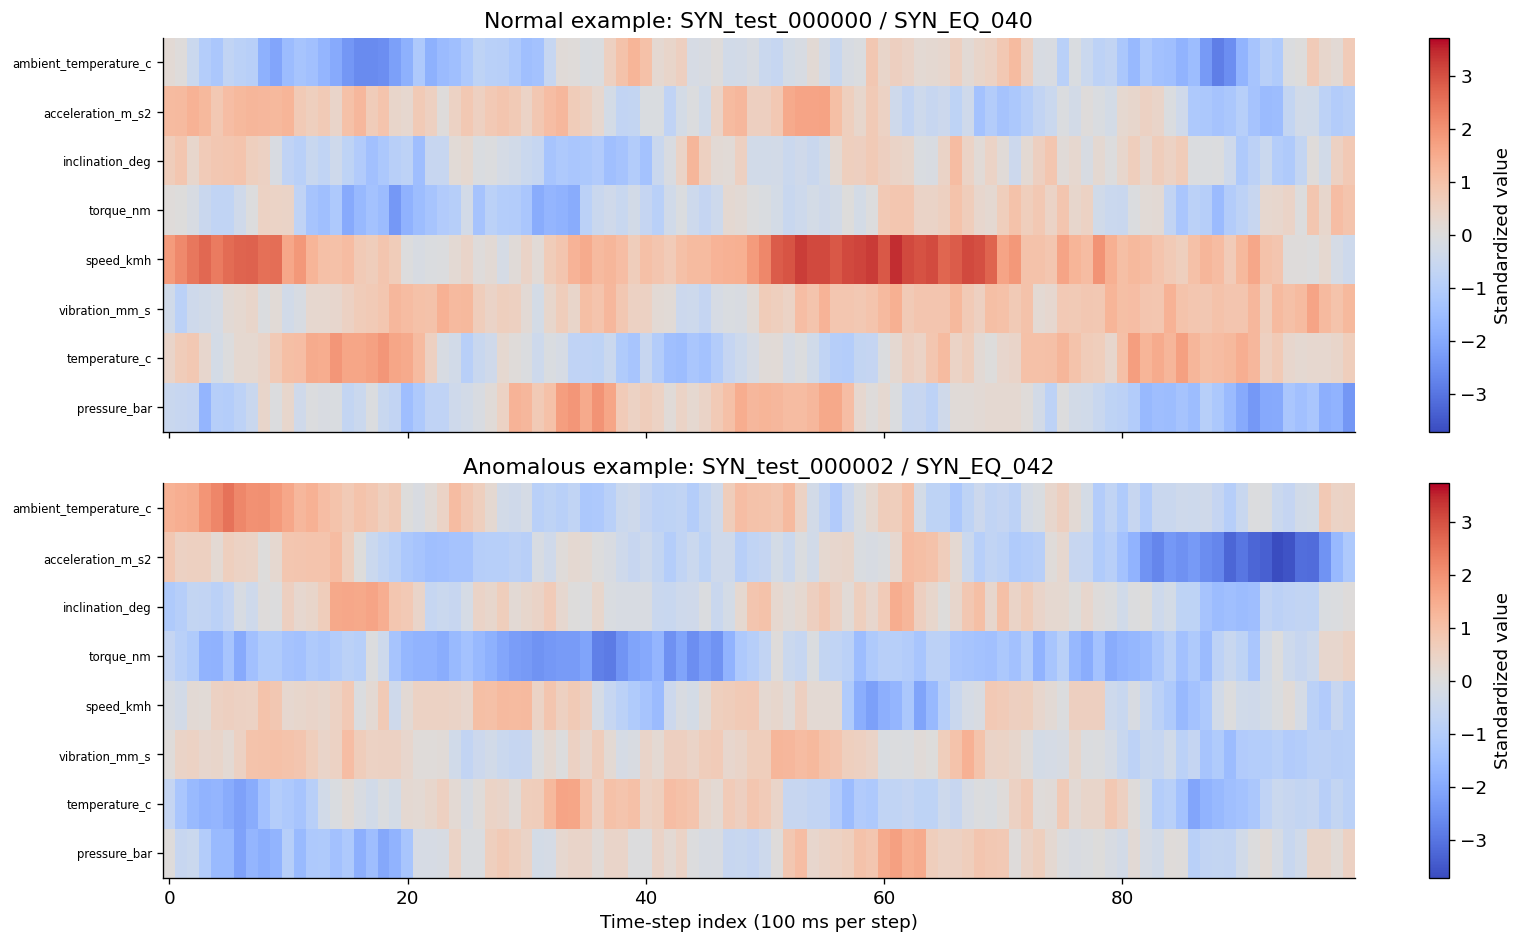

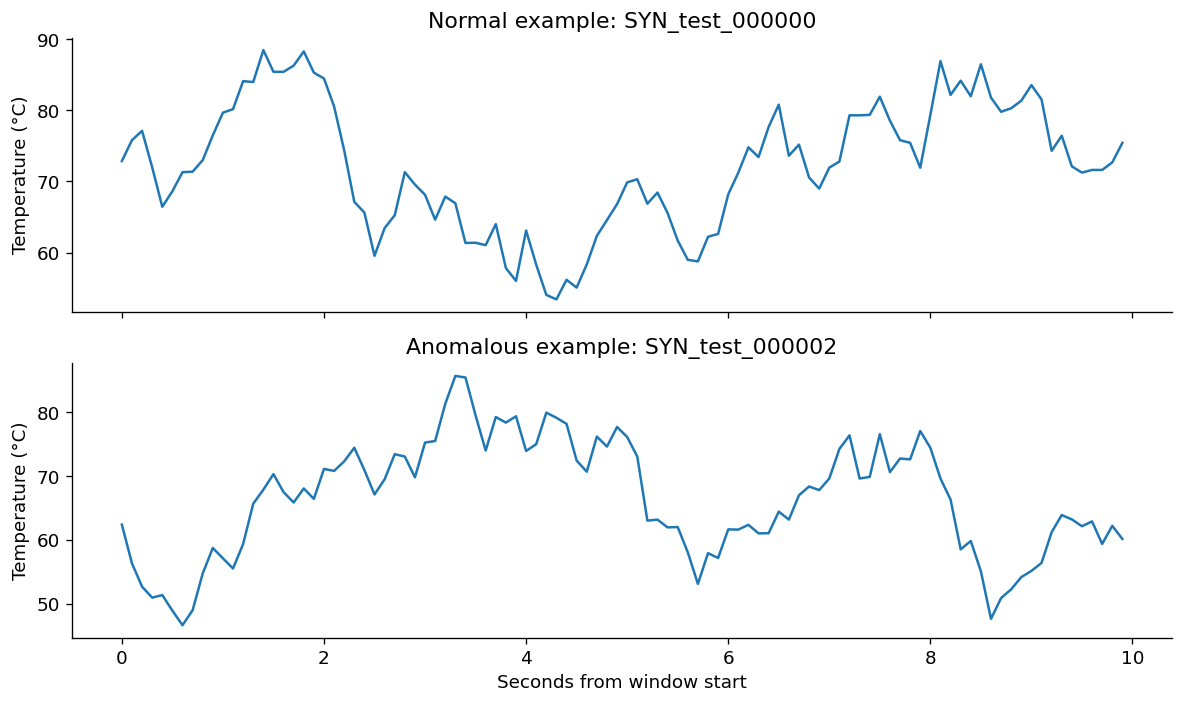


RECORDED PREPROCESSING REPORT:
{
  "data_origin": "synthetic demonstration",
  "input_folder": "/content/drive/MyDrive/Port Work/Synthetic_Anomaly_Dataset",
  "feature_names": [
    "pressure_bar",
    "temperature_c",
    "vibration_mm_s",
    "speed_kmh",
    "torque_nm",
    "inclination_deg",
    "acceleration_m_s2",
    "ambient_temperature_c"
  ],
  "window_length": 100,
  "sampling_interval_seconds": 0.1,
  "preprocessing_fit_subset": "normal training windows only",
  "smoothing": "disabled",
  "splits": {
    "train": {
      "input_shape": [
        14000,
        100,
        8
      ],
      "normal": 13000,
      "anomalous": 1000,
      "equipment_count": 20,
      "missing_or_infinite_values": 0,
      "output_shape": [
        14000,
        100,
        8
      ]
    },
    "validation": {
      "input_shape": [
        3000,
        100,
        8
      ],
      "normal": 2785,
      "anomalous": 215,
      "equipment_count": 20,
      "missing_or_infinite_values": 0,

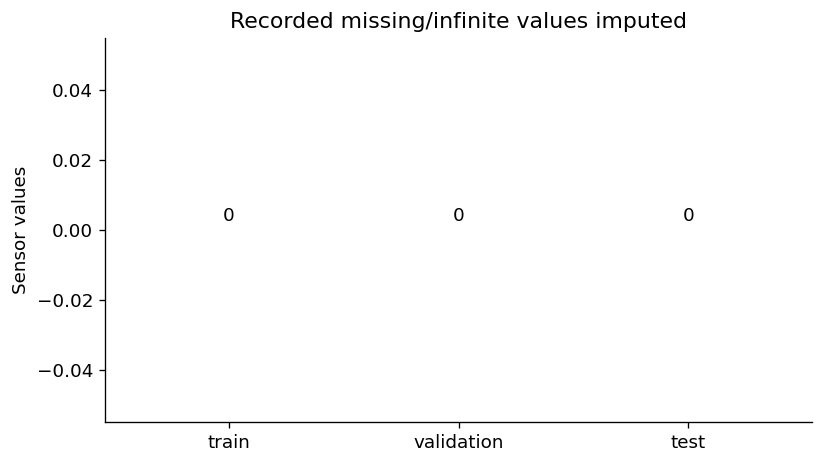


Completed. Results and figures saved to: /content/drive/MyDrive/Port Work/Anomaly_Preprocessed/Results_Visualization


In [ ]:
# Colab: inspect and visualize completed eight-channel anomaly preprocessing.
# No training or alteration of sensor data. Figures describe synthetic engineered data.
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from google.colab import drive

ROOT=Path('/content/drive/MyDrive/Port Work/Anomaly_Preprocessed')
OUT=ROOT/'Results_Visualization'
EXPECTED={'train':[13000,1000],'validation':[2785,215],'test':[2785,215]}
BASE_NAMES=['pressure_bar','temperature_c','vibration_mm_s','speed_kmh','torque_nm','inclination_deg','acceleration_m_s2','ambient_temperature_c']
NAMES=BASE_NAMES.copy()
COLORS=['#3978a8']*8
if not Path('/content/drive/MyDrive').is_dir(): drive.mount('/content/drive',force_remount=False)
if not ROOT.is_dir(): raise FileNotFoundError('Run anomaly preprocessing first: '+str(ROOT))
OUT.mkdir(parents=True,exist_ok=True)
rows=[];stats=[];samples={};seen_ids=set();seen_eq=set();rng=np.random.default_rng(42)
for split,counts in EXPECTED.items():
    print('Inspecting:',split,flush=True)
    with np.load(ROOT/f'{split}_mamba.npz',allow_pickle=False) as a:
        x=a['X'].astype(np.float32);y=a['y'];names=a['feature_names'].astype(str).tolist()
        ids=a['window_id'].astype(str);eq=a['equipment_id'].astype(str)
    if names!=NAMES or x.shape!=(sum(counts),100,8): raise ValueError('Unexpected feature names or shape')
    if not np.isfinite(x).all() or not np.isin(y,[0,1]).all(): raise ValueError('Invalid values or labels')
    if np.bincount(y.astype(int),minlength=2).tolist()!=counts: raise ValueError('Unexpected class counts')
    if len(ids)!=len(y) or len(eq)!=len(y) or len(set(ids))!=len(ids): raise ValueError('Invalid identifiers')
    if seen_ids&set(ids) or seen_eq&set(eq): raise ValueError('Cross-split overlap')
    seen_ids.update(ids);seen_eq.update(eq)
    rows.append({'split':split,'windows':len(y),'normal':counts[0],'anomalous':counts[1],
        'time_steps':100,'channels':8,'sensor_readings':len(y)*100,'equipment':len(set(eq)),
        'missing_values':int(np.isnan(x).sum()),'infinite_values':int(np.isinf(x).sum())})
    flat=x.reshape(-1,8)
    means=flat.mean(0,dtype=np.float64);std=flat.std(0,dtype=np.float64)
    for j,name in enumerate(names):
        stats.append({'split':split,'feature':name,'mean':means[j],'std':std[j],
            'minimum':float(flat[:,j].min()),'maximum':float(flat[:,j].max())})
    if split=='train':
        normal_flat=x[y==0].reshape(-1,8)
        reference_stats=pd.DataFrame({'feature':NAMES,
            'normal_training_mean':normal_flat.mean(0,dtype=np.float64),
            'normal_training_std':normal_flat.std(0,dtype=np.float64)})
        reference_stats.to_csv(OUT/'normal_training_scaling_check.csv',index=False)
        del normal_flat
        # Bounded sample of time points for descriptive plots, not model selection.
        idx=rng.choice(len(flat),min(20000,len(flat)),replace=False)
        sampled=flat[idx].copy()
    if split=='test':
        for label in [0,1]:
            i=int(np.flatnonzero(y==label)[0]);samples[label]=(x[i].copy(),str(ids[i]),str(eq[i]))
    del x,flat
summary=pd.DataFrame(rows);statistics=pd.DataFrame(stats)
summary.to_csv(OUT/'dataset_summary.csv',index=False)
statistics.to_csv(OUT/'feature_statistics.csv',index=False)
print('\nVERIFIED DATASET SUMMARY')
print(summary.to_string(index=False))
print('\nTotal windows:',summary.windows.sum())
try:
    from IPython.display import display
    display(summary)
except ImportError: pass

def save(fig,name):
    fig.tight_layout();fig.savefig(OUT/name,dpi=200,bbox_inches='tight');plt.show();plt.close(fig)

# 1. Class balance by split.
fig,ax=plt.subplots(figsize=(8,4.5));positions=np.arange(len(summary));width=.36
b1=ax.bar(positions-width/2,summary.normal,width,label='Normal',color='#3978a8')
b2=ax.bar(positions+width/2,summary.anomalous,width,label='Anomalous',color='#d26449')
ax.bar_label(b1,padding=3);ax.bar_label(b2,padding=3)
ax.set_xticks(positions,summary.split);ax.set(ylabel='Windows',title='Anomaly dataset class counts');ax.legend()
save(fig,'class_distribution.png')

# 3. Mean/std across splits for a scaling diagnostic. Not feature importance.
fig,axes=plt.subplots(2,1,figsize=(14,8),sharex=True)
for split in EXPECTED:
    table=statistics.loc[statistics.split.eq(split)].set_index('feature').loc[NAMES]
    axes[0].plot(np.arange(8),table['mean'],marker='o',ms=3,label=split)
    axes[1].plot(np.arange(8),table['std'],marker='o',ms=3,label=split)
axes[0].axhline(0,color='gray',ls='--');axes[1].axhline(1,color='gray',ls='--')
axes[0].set(ylabel='Mean',title='Channel statistics after training-only standardization')
axes[1].set(ylabel='Standard deviation');axes[0].legend();axes[1].legend()
axes[1].set_xticks(np.arange(8),NAMES,rotation=90,fontsize=8)
save(fig,'standardization_diagnostics.png')

# Scaling is fitted to NORMAL training windows, not the entire mixed training split.
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
axes[0].bar(NAMES,reference_stats.normal_training_mean,color='#3978a8')
axes[0].axhline(0,color='gray',ls='--');axes[0].set(ylabel='Mean',title='Normal-training means (expected near zero)')
axes[1].bar(NAMES,reference_stats.normal_training_std,color='#369f77')
axes[1].axhline(1,color='gray',ls='--');axes[1].set(ylabel='Standard deviation',title='Normal-training std (near one unless constant)')
for ax in axes: ax.tick_params(axis='x',rotation=90)
save(fig,'normal_training_scaling_check.png')

# 4. Sampled training feature distributions.
fig,ax=plt.subplots(figsize=(15,6))
bp=ax.boxplot([sampled[:,j] for j in range(8)],showfliers=False,patch_artist=True)
for box,color in zip(bp['boxes'],COLORS): box.set_facecolor(color);box.set_alpha(.65)
ax.set_xticks(np.arange(1,9),NAMES,rotation=90,fontsize=8)
ax.set(ylabel='Standardized channel value',title='Training-channel distributions (sampled time points; outlier markers hidden)')
save(fig,'training_feature_distributions.png')

# 5. Correlation matrix on sampled training time points.
corr=pd.DataFrame(sampled,columns=NAMES).corr()
corr.to_csv(OUT/'sampled_training_correlations.csv')
fig,ax=plt.subplots(figsize=(13,11));im=ax.imshow(corr.to_numpy(),vmin=-1,vmax=1,cmap='coolwarm')
ax.set_xticks(np.arange(8),NAMES,rotation=90,fontsize=8)
ax.set_yticks(np.arange(8),NAMES,fontsize=8)
ax.set_title('Channel correlations — sampled synthetic training time points')
fig.colorbar(im,ax=ax,label='Pearson correlation');save(fig,'training_correlation_heatmap.png')

# 6. Example normal/anomalous window heatmaps. These are examples, not model detections.
fig,axes=plt.subplots(2,1,figsize=(14,8),sharex=True)
limit=max(float(np.max(np.abs(v[0]))) for v in samples.values())
for label,ax in enumerate(axes):
    values,window,equipment=samples[label]
    im=ax.imshow(values.T,aspect='auto',origin='lower',cmap='coolwarm',vmin=-limit,vmax=limit)
    ax.set_yticks(np.arange(8),NAMES,fontsize=7)
    ax.set_title(f"{'Normal' if label==0 else 'Anomalous'} example: {window} / {equipment}")
    fig.colorbar(im,ax=ax,label='Standardized value')
axes[-1].set_xlabel('Time-step index (100 ms per step)')
save(fig,'example_window_heatmaps.png')

# 7. Example temperature curves in original units, recovered using saved scaler.
with np.load(ROOT/'preprocessing_parameters.npz',allow_pickle=False) as a:
    means=a['scaler_mean'] if 'scaler_mean' in a.files else a['mean']
    scales=a['scaler_std'] if 'scaler_std' in a.files else a['scale']
    if a['feature_names'].astype(str).tolist()!=NAMES: raise ValueError('Scaler channel order mismatch')
fig,axes=plt.subplots(2,1,figsize=(10,6),sharex=True)
for label,ax in enumerate(axes):
    values,window,equipment=samples[label]
    temperature=values[:,1]*scales[1]+means[1]
    ax.plot(np.arange(100)*.1,temperature)
    ax.set(ylabel='Temperature (°C)',title=f"{'Normal' if label==0 else 'Anomalous'} example: {window}")
axes[-1].set_xlabel('Seconds from window start')
save(fig,'example_temperature_original_units.png')
# Display the recorded preprocessing report, without inventing cleaning statistics.
report_path=ROOT/'preprocessing_report.json'
if report_path.is_file():
    report=json.loads(report_path.read_text())
    print('\nRECORDED PREPROCESSING REPORT:')
    print(json.dumps(report,indent=2))
    (OUT/'source_preprocessing_report.json').write_text(json.dumps(report,indent=2))
    records=[]
    for split,entry in report.get('splits',{}).items():
        records.append({'split':split,'nonfinite_values_imputed':entry.get('missing_or_infinite_values',entry.get('nonfinite_values_imputed',None))})
    table=pd.DataFrame(records)
    table.to_csv(OUT/'recorded_imputation_counts.csv',index=False)
    if not table.empty and table.nonfinite_values_imputed.notna().all():
        fig,ax=plt.subplots(figsize=(7,4));bars=ax.bar(table.split,table.nonfinite_values_imputed,color='#3978a8')
        ax.bar_label(bars,padding=3);ax.set(ylabel='Sensor values',title='Recorded missing/infinite values imputed')
        save(fig,'recorded_imputation_counts.png')
(OUT/'visualization_notes.json').write_text(json.dumps({'data_origin':'synthetic','stage':'anomaly preprocessing only',
    'channels':NAMES,'preprocessing_fit':'normal training windows only',
    'sampled_training_time_points':min(20000,14000*100),'seed':42,
    'distribution_units':'standardized except explicitly recovered temperature',
    'interpretation':'no classifier training, prediction accuracy, feature importance or ROC claimed',
    'cleaning_statistics':'taken only from existing preprocessing report',
    'temporal_dependence':'correlations are descriptive; sampled time points are not independent evidence'},indent=2))
print('\nCompleted. Results and figures saved to:',OUT,flush=True)


In [ ]:
# Progress-enabled Colab script. No argument parsing. All data remain synthetic.
import time, threading, atexit, traceback
import subprocess, queue
_STATUS={'stage':'Starting','start':time.monotonic(),'phase_start':time.monotonic()}
_STOP=threading.Event()
def log(*items):
    elapsed=time.monotonic()-_STATUS['start']
    print(f'[{elapsed:8.1f}s]',*items,flush=True)
def stage(name):
    _STATUS['stage']=name;_STATUS['phase_start']=time.monotonic();log(name)
def heartbeat():
    while not _STOP.wait(20):
        log('Waiting/running:',_STATUS['stage'],f"| stage elapsed {time.monotonic()-_STATUS['phase_start']:.0f}s")
def run_pipeline():
    # Complete Colab script: explicitly synthetic 21-channel replacement + Mamba learning.
    # Paste into one cell, or upload this file and run with %run.
    from pathlib import Path
    import os, sys, subprocess, json, random, copy
    stage('Importing NumPy and Pandas')
    import numpy as np
    import pandas as pd
    stage('Importing PyTorch')
    import torch
    from torch import nn
    from torch.utils.data import DataLoader, TensorDataset
    from google.colab import drive

    BASE=Path('/content/drive/MyDrive/Port Work')
    SOURCE=BASE/'Synthetic_Anomaly_Dataset'
    OUT=BASE/'Anomaly_21Features_Mamba_PyTorch_SYNTHETIC'
    # This explicitly generates NEW simulated channels. It does NOT recover missing measurements.
    GENERATE_SYNTHETIC_21=True
    EPOCHS=20
    BATCH_SIZE=16
    D_MODEL=128
    D_STATE=16
    N_BLOCKS=4
    SEED=42
    FEATURES=['H1InverterTemperature','D1MotorTemperature','D2InverterTemperature','H2InverterTemperature','D3InverterTemperature','H1MotorTemperature','Hoist2TorqueReference','AmbientTemperature','D1InverterTemperature','Hoist1TorqueReference','EngineErrorSlot3','D4InverterTemperature','Hoist2SpeedReference','Hoist1SpeedReference','D3MotorTemperature','H2MotorTemperature','D2MotorTemperature','EngineErrorSlot1','EngineErrorSlot5','EngineTemperature','D4MotorTemperature']
    REFERENCE_IMPORTANCE=[.612,.468,.448,.341,.229,.203,.200,.198,.195,.194,.193,.184,.179,.179,.179,.176,.158,.158,.154,.144,.136]
    COUNTS={'train':[13000,1000],'validation':[2785,215],'test':[2785,215]}
    random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED)
    stage('Connecting Google Drive')
    if not Path('/content/drive/MyDrive').is_dir(): drive.mount('/content/drive',force_remount=False)
    if not torch.cuda.is_available(): raise RuntimeError('Select Runtime > Change runtime type > T4 GPU, then rerun.')
    log('Python:',sys.version.split()[0], '| PyTorch:',torch.__version__, '| CUDA:',torch.version.cuda, '| GPU:',torch.cuda.get_device_name(0))
    stage('Using pure PyTorch Mamba-1-style reference recurrence; no extension installation')
    import math
    import torch.nn.functional as F
    class ReferenceMamba(nn.Module):
        """Real-valued Mamba-1-style selective SSM, sequential PyTorch scan.
        Implements input-dependent dt/B/C, negative diagonal A, D skip and SiLU gate.
        Independent implementation; not the optimized mamba_ssm package.
        """
        def __init__(self,d_model,d_state=16,d_conv=4,expand=2):
            super().__init__()
            self.inner=int(expand*d_model);self.state_size=d_state
            self.rank=math.ceil(d_model/16)
            self.in_proj=nn.Linear(d_model,2*self.inner,bias=False)
            self.conv=nn.Conv1d(self.inner,self.inner,d_conv,padding=d_conv-1,groups=self.inner,bias=True)
            self.x_proj=nn.Linear(self.inner,self.rank+2*d_state,bias=False)
            self.dt_proj=nn.Linear(self.rank,self.inner,bias=True)
            nn.init.uniform_(self.dt_proj.weight,-self.rank**-.5,self.rank**-.5)
            initial_dt=torch.exp(torch.empty(self.inner).uniform_(math.log(.001),math.log(.1)))
            with torch.no_grad(): self.dt_proj.bias.copy_(initial_dt+torch.log(-torch.expm1(-initial_dt)))
            self.A_log=nn.Parameter(torch.arange(1,d_state+1,dtype=torch.float32).log().repeat(self.inner,1))
            self.D=nn.Parameter(torch.ones(self.inner))
            self.out_proj=nn.Linear(self.inner,d_model,bias=False)
        def forward(self,inputs):
            batch,length,_=inputs.shape
            u,gate=self.in_proj(inputs).chunk(2,dim=-1)
            u=F.silu(self.conv(u.transpose(1,2))[:,:,:length].transpose(1,2))
            dt,B,C=torch.split(self.x_proj(u),[self.rank,self.state_size,self.state_size],dim=-1)
            dt=F.softplus(self.dt_proj(dt))
            A=-torch.exp(self.A_log.float())
            state=u.new_zeros(batch,self.inner,self.state_size)
            outputs=[]
            for t in range(length):
                delta=dt[:,t,:]
                transition=torch.exp(delta.unsqueeze(-1)*A.unsqueeze(0))
                drive=delta.unsqueeze(-1)*B[:,t,:].unsqueeze(1)*u[:,t,:].unsqueeze(-1)
                state=transition*state+drive
                value=(state*C[:,t,:].unsqueeze(1)).sum(-1)+self.D*u[:,t,:]
                outputs.append(value)
            y=torch.stack(outputs,dim=1)*F.silu(gate)
            return self.out_proj(y)
    log('Backend: independent PyTorch reference scan, not CUDA-fused mamba_ssm.')

    stage('Finding anomaly source labels')
    if not (SOURCE/'anomaly'/'train_labels.csv').is_file():
        found=[p.parent.parent for p in SOURCE.rglob('train_labels.csv') if p.parent.name=='anomaly']
        if len(found)!=1: raise FileNotFoundError('Cannot locate anomaly label CSVs in '+str(SOURCE))
        SOURCE=found[0]
    OUT.mkdir(parents=True,exist_ok=True)
    (OUT/'Data').mkdir(exist_ok=True);(OUT/'Features').mkdir(exist_ok=True)
    log('SYNTHETIC demonstration: NEW 21-channel sequences; source measurements are NOT reconstructed.')
    previous=BASE/'Anomaly_21Features_Mamba_SYNTHETIC'/'Data'
    if all((previous/f'{sp}_raw21.npz').is_file() for sp in COUNTS) and not any((OUT/'Data'/f'{sp}_raw21.npz').exists() for sp in COUNTS):
        import shutil
        stage('Copying existing synthetic raw 21-channel arrays; no regeneration')
        for sp in COUNTS: shutil.copy2(previous/f'{sp}_raw21.npz',OUT/'Data'/f'{sp}_raw21.npz')
    # Reuse only a complete existing 21-channel set. Never partially reuse RNG-dependent generation.
    if GENERATE_SYNTHETIC_21 and all((OUT/'Data'/f'{sp}_raw21.npz').is_file() for sp in COUNTS):
        GENERATE_SYNTHETIC_21=False
        log('Reusing existing raw 21-channel sequences after validation.')
    rng=np.random.default_rng(SEED);data={};equipment_seen=set();ids_seen=set()
    for split,counts in COUNTS.items():
        stage(f'Loading {split} labels and preparing 21-channel inputs')
        m=pd.read_csv(SOURCE/'anomaly'/f'{split}_labels.csv',dtype={'window_id':str,'equipment_id':str})
        y=pd.to_numeric(m.label,errors='raise').to_numpy()
        if not np.isin(y,[0,1]).all(): raise ValueError('Invalid anomaly labels')
        y=y.astype(np.int64)
        if np.bincount(y,minlength=2).tolist()!=counts: raise ValueError('Class counts differ')
        if m.window_id.isna().any() or m.window_id.duplicated().any(): raise ValueError('Invalid IDs')
        eq=set(m.equipment_id);ids=set(m.window_id)
        if eq&equipment_seen or ids&ids_seen: raise ValueError('Split leakage')
        equipment_seen.update(eq);ids_seen.update(ids)
        if GENERATE_SYNTHETIC_21:
            n=len(m);x=np.zeros((n,100,21),np.float32)
            # Simulated correlated channels, independent of the paper importance numbers.
            severity=np.clip(rng.normal(.2+.45*y,.3,n),0,1.5)
            unique=sorted(eq);offsets={e:rng.normal(0,1,21) for e in unique}
            machine=np.stack([offsets[e] for e in m.equipment_id])
            state=rng.normal(size=(n,21));load=rng.normal(size=n)
            for t in range(100):
                if t%25==0: log(f'{split}: generating step {t+1}/100')
                state=.94*state+np.sqrt(1-.94**2)*rng.normal(size=(n,21))
                load=.95*load+np.sqrt(1-.95**2)*rng.normal(size=n)
                onset=np.maximum(0,t/99-.3)
                for j,name in enumerate(FEATURES):
                    if 'ErrorSlot' in name:
                        # Binary simulated status, not an input copy of anomaly labels.
                        value=(rng.random(n)<np.clip(.01+.08*severity+.01*load,0,.4)).astype(float)
                    elif name=='AmbientTemperature':
                        value=27+machine[:,j]+2*state[:,j]
                    elif 'Torque' in name:
                        value=420+15*machine[:,j]+55*state[:,j]+40*load+30*severity*onset
                    elif 'Speed' in name:
                        value=12+.5*machine[:,j]+2*state[:,j]+load-1.5*severity*onset
                    else:
                        value=60+2*machine[:,j]+6*state[:,j]+4*load+25*severity*onset
                    x[:,t,j]=value if 'ErrorSlot' in name else np.maximum(value,0)
            # Save NEW raw channels with matching IDs. Old eight-channel arrays are not renamed.
            stage(f'Saving {split} raw 21-channel sequences to Drive')
            np.savez_compressed(OUT/'Data'/f'{split}_raw21.npz',X=x.astype(np.float16),y=y,window_id=m.window_id.to_numpy(dtype=str),equipment_id=m.equipment_id.to_numpy(dtype=str),feature_names=np.array(FEATURES))
        else:
            stage(f'Reading existing {split} raw sequences from Drive')
            with np.load(OUT/'Data'/f'{split}_raw21.npz',allow_pickle=False) as a:
                if a['feature_names'].tolist()!=FEATURES: raise ValueError('Expected exact 21 feature names/order')
                if not np.array_equal(a['window_id'],m.window_id.to_numpy()): raise ValueError('Window order mismatch')
                if not np.array_equal(a['equipment_id'],m.equipment_id.to_numpy()): raise ValueError('Equipment mismatch')
                if not np.array_equal(a['y'],y): raise ValueError('Label mismatch')
                x=a['X'].astype(np.float32)
        if x.shape!=(len(y),100,21) or not np.isfinite(x).all(): raise ValueError('Invalid sensor tensor')
        m['is_synthetic']=True;m.to_csv(OUT/'Data'/f'{split}_manifest.csv',index=False)
        data[split]=(x,y,m)

    stage('Fitting 21-channel scaling on normal training windows only')
    # Fit on normal training data only. New 21-channel data MUST be reprocessed.
    normal=data['train'][0][data['train'][1]==0].reshape(-1,21)
    mean=normal.mean(0,dtype=np.float64);std=normal.std(0,dtype=np.float64);std[std<1e-8]=1
    np.savez(OUT/'Data'/'scaler21.npz',mean=mean,scale=std,feature_names=np.array(FEATURES))
    for split,(x,y,m) in list(data.items()):
        stage(f'Scaling and saving {split} Mamba input')
        x=((x-mean)/std).astype(np.float32);data[split]=(x,y,m)
        np.savez_compressed(OUT/'Data'/f'{split}_mamba21.npz',X=x,y=y,window_id=m.window_id.to_numpy(dtype=str),equipment_id=m.equipment_id.to_numpy(dtype=str),feature_names=np.array(FEATURES))

    class Block(nn.Module):
        def __init__(self):
            super().__init__()
            self.norm1=nn.LayerNorm(D_MODEL)
            self.ssm=ReferenceMamba(d_model=D_MODEL,d_state=D_STATE,d_conv=4,expand=2)
            self.norm2=nn.LayerNorm(D_MODEL)
            self.ff=nn.Sequential(nn.Linear(D_MODEL,2*D_MODEL),nn.GELU(),nn.Dropout(.1),nn.Linear(2*D_MODEL,D_MODEL))
        def forward(self,x):
            x=x+self.ssm(self.norm1(x))
            return x+self.ff(self.norm2(x))

    class RepresentationLearner(nn.Module):
        def __init__(self):
            super().__init__()
            self.projection=nn.Linear(21,D_MODEL)
            self.blocks=nn.Sequential(*[Block() for _ in range(N_BLOCKS)])
            self.norm=nn.LayerNorm(D_MODEL)
            self.head=nn.Sequential(nn.Linear(D_MODEL,128),nn.ReLU())
            # Training-only reconstruction head ensures the pooled features are learned.
            self.decoder=nn.Sequential(nn.Linear(128,256),nn.GELU(),nn.Linear(256,100*21))
        def encode(self,x):
            h=self.norm(self.blocks(self.projection(x)))
            return self.head(h.mean(dim=1))
        def forward(self,x):
            return self.decoder(self.encode(x)).reshape(-1,100,21)

    stage('Creating reference Mamba model and testing forward/backward')
    model=RepresentationLearner().cuda()
    try:
        probe=model(torch.zeros(2,100,21,device='cuda'))
        probe.square().mean().backward()
        torch.cuda.synchronize();model.zero_grad(set_to_none=True)
        log('Reference Mamba forward/backward smoke check passed; training can start.')
    except Exception as exc:
        raise RuntimeError('PyTorch reference selective SSM forward/backward failed; inspect the original exception above.') from exc

    def loader(split,normal_only=False,shuffle=False):
        x,y,_=data[split]
        if normal_only: x=x[y==0]
        return DataLoader(TensorDataset(torch.from_numpy(x)),batch_size=BATCH_SIZE,shuffle=shuffle,num_workers=0)

    train_loader=loader('train',True,True);valid_loader=loader('validation',True)
    optimizer=torch.optim.AdamW(model.parameters(),lr=1e-3,weight_decay=1e-4)
    criterion=nn.MSELoss();best=float('inf');patience=0;history=[]
    training_started=time.monotonic()
    for epoch in range(EPOCHS):
        epoch_started=time.monotonic()
        stage(f'Epoch {epoch+1}/{EPOCHS}')
        values=[]
        for training,batches in [(True,train_loader),(False,valid_loader)]:
            model.train(training);total=0.;number=0
            for batch_index,(batch,) in enumerate(batches,1):
                batch=batch.cuda()
                with torch.set_grad_enabled(training):
                    loss=criterion(model(batch),batch)
                    if not torch.isfinite(loss): raise RuntimeError('Nonfinite training loss')
                    if training:
                        optimizer.zero_grad(set_to_none=True);loss.backward()
                        nn.utils.clip_grad_norm_(model.parameters(),1.0);optimizer.step()
                total+=loss.item()*len(batch);number+=len(batch)
                if batch_index==1 or batch_index%50==0 or batch_index==len(batches):
                    mode='train' if training else 'validation'
                    stage(f'Epoch {epoch+1}/{EPOCHS} {mode} batch {batch_index}/{len(batches)}')
                    log(f'{mode}: batch {batch_index}/{len(batches)}, running MSE={total/number:.6f}')
            values.append(total/number)
        torch.cuda.synchronize()
        epoch_seconds=time.monotonic()-epoch_started
        log(f'Epoch duration: {epoch_seconds:.1f}s; estimated remaining at full epoch budget: {epoch_seconds*(EPOCHS-epoch-1)/60:.1f} min (early stopping may shorten this).')
        stage('Saving training history and best checkpoint')
        history.append({'epoch_seconds':epoch_seconds,'epoch':epoch+1,'train_normal_mse':values[0],'validation_normal_mse':values[1]})
        pd.DataFrame(history).to_csv(OUT/'training_history.csv',index=False)
        log(f'Epoch {epoch+1}: train MSE={values[0]:.6f}, validation MSE={values[1]:.6f}')
        if values[1]<best:
            best=values[1];patience=0
            torch.save(model.state_dict(),OUT/'best_mamba_representation.pt')
        else:
            patience+=1
            if patience>=5: break
    model.load_state_dict(torch.load(OUT/'best_mamba_representation.pt',map_location='cuda',weights_only=True));model.eval()
    for split,(x,y,m) in data.items():
        stage(f'Extracting {split} learned features')
        embeddings=[]
        with torch.no_grad():
            batches=loader(split)
            for i,(batch,) in enumerate(batches,1):
                embeddings.append(model.encode(batch.cuda()).cpu().numpy())
                if i==1 or i%20==0 or i==len(batches):
                    stage(f'Extracting {split}: batch {i}/{len(batches)}')
                    log(_STATUS['stage'])
        h=np.concatenate(embeddings)
        assert h.shape==(len(y),128) and np.isfinite(h).all()
        table=pd.DataFrame(h,columns=[f'Mamba_Feature_{i+1:03d}' for i in range(128)])
        for col in ['window_id','equipment_id','window_start','window_end']: table[col]=m[col].to_numpy()
        table['label']=y;table['is_synthetic']=True
        stage(f'Saving {split} feature CSV and NPZ')
        table.to_csv(OUT/'Features'/f'{split}_mamba_features.csv',index=False)
        np.savez_compressed(OUT/'Features'/f'{split}_mamba_features.npz',H=h,y=y,window_id=m.window_id.to_numpy(dtype=str),equipment_id=m.equipment_id.to_numpy(dtype=str))
        log(split,'input',x.shape,'extracted',h.shape)
    pd.DataFrame({'input_feature':FEATURES,'paper_reported_reference_importance':REFERENCE_IMPORTANCE}).to_csv(OUT/'paper_importance_REFERENCE_ONLY.csv',index=False)
    (OUT/'configuration.json').write_text(json.dumps({'synthetic':True,'features':FEATURES,'seed':SEED,'d_model':D_MODEL,'d_state':D_STATE,'backend':'independent PyTorch Mamba-1-style reference scan','batch_size':BATCH_SIZE,'blocks':N_BLOCKS,'output_dimension':128,'training_objective':'normal-window reconstruction through pooled representation','scope':'Mamba representation learning; downstream latent Autoencoder/anomaly threshold not fitted','fusion_note':'new synthetic channels share source anomaly IDs, but do not match the independently generated fault cohort'},indent=2))
    stage('Completed')
    log('Completed. Outputs:',OUT)
    log('Synthetic demonstration only. Paper importance values were preserved as references, not used to generate or weight features.')

if __name__=='__main__':
    worker=threading.Thread(target=heartbeat,daemon=True)
    worker.start()
    try:
        run_pipeline()
    except KeyboardInterrupt:
        log('Interrupted by user at stage:',_STATUS['stage'])
        raise
    except Exception:
        log('FAILED at stage:',_STATUS['stage'])
        traceback.print_exc()
        raise
    finally:
        _STOP.set()
        worker.join(timeout=1)


[     0.1s] Importing NumPy and Pandas
[     0.1s] Importing PyTorch
[     0.1s] Connecting Google Drive
[     0.1s] Python: 3.13.15 | PyTorch: 2.11.0+cu130 | CUDA: 13.0 | GPU: Tesla T4
[     0.1s] Using pure PyTorch Mamba-1-style reference recurrence; no extension installation
[     0.1s] Backend: independent PyTorch reference scan, not CUDA-fused mamba_ssm.
[     0.1s] Finding anomaly source labels
[     1.7s] SYNTHETIC demonstration: NEW 21-channel sequences; source measurements are NOT reconstructed.
[     1.7s] Loading train labels and preparing 21-channel inputs
[     3.2s] train: generating step 1/100
[     8.1s] train: generating step 26/100
[    12.9s] train: generating step 51/100
[    17.7s] train: generating step 76/100
[    20.1s] Waiting/running: Loading train labels and preparing 21-channel inputs | stage elapsed 18s
[    21.6s] Saving train raw 21-channel sequences to Drive
[    40.1s] Waiting/running: Saving train raw 21-channel sequences to Drive | stage elapsed 19s
[

SYNTHETIC DATA — MAMBA REPRESENTATION RESULTS


,Split,Windows,Normal,Anomaly,Anomaly_Percent,Feature_Dimension,Equipment_Count,Synthetic
0,train,14000,13000,1000,7.143,128,20,True
1,validation,3000,2785,215,7.167,128,20,True
2,test,3000,2785,215,7.167,128,20,True


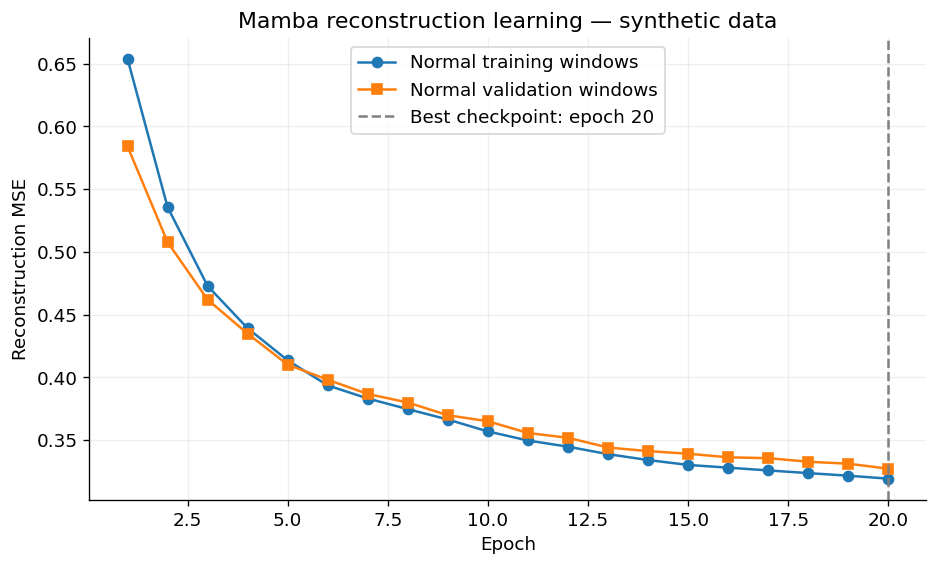

,synthetic,epochs_completed,best_epoch,best_validation_normal_mse,train_normal_mse_at_best_epoch,total_epoch_time_minutes
0,True,20,20,0.327139,0.319232,102.254168


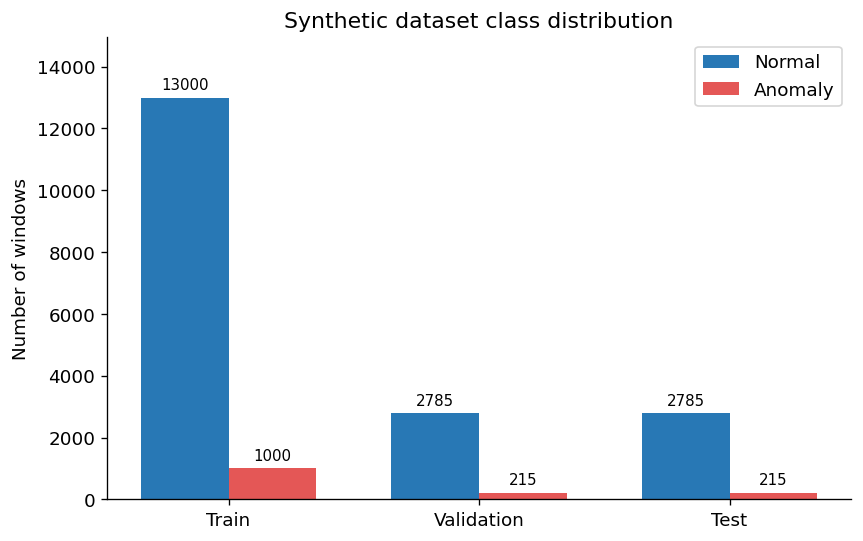

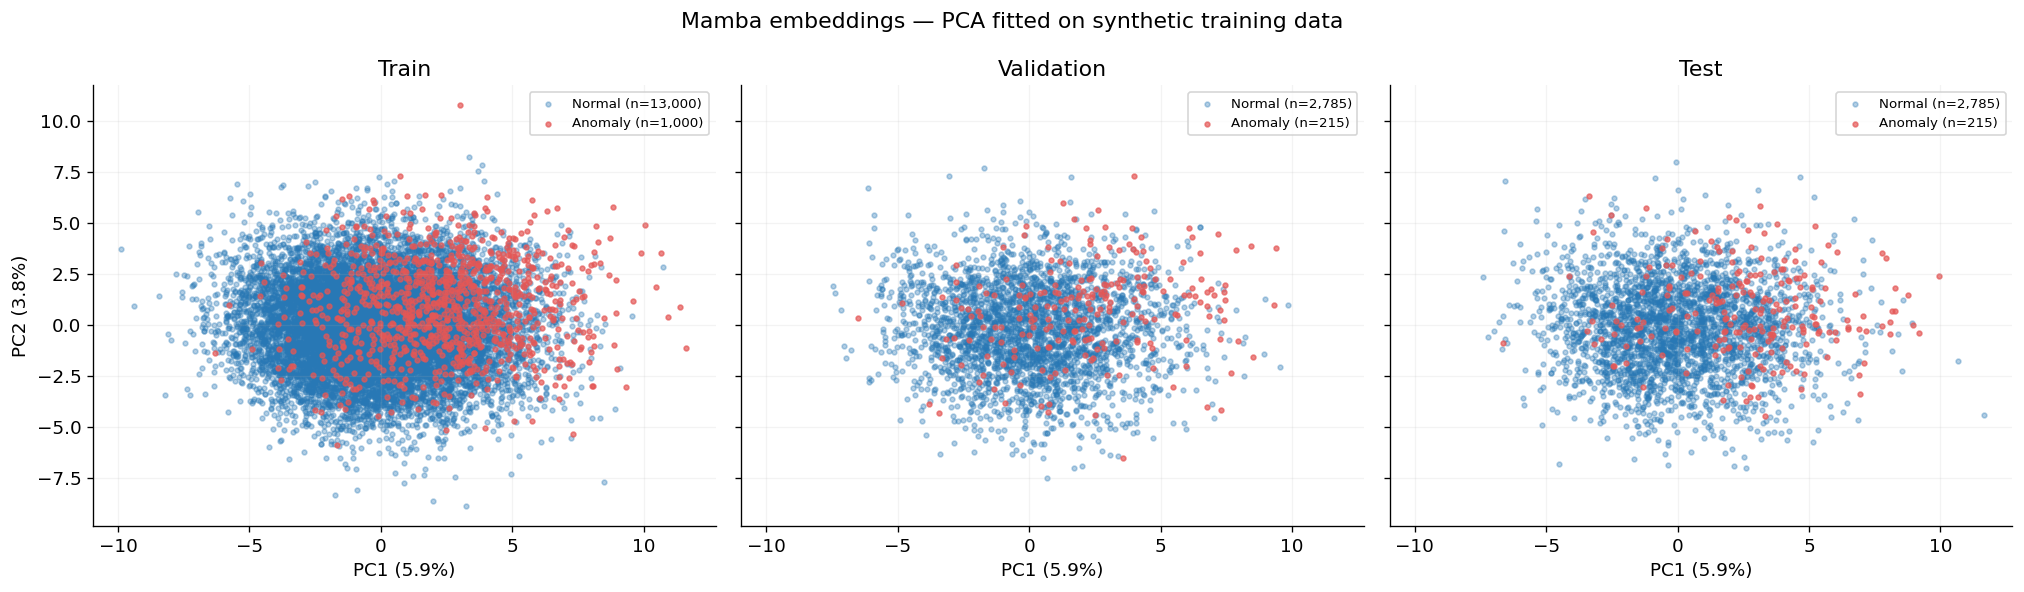

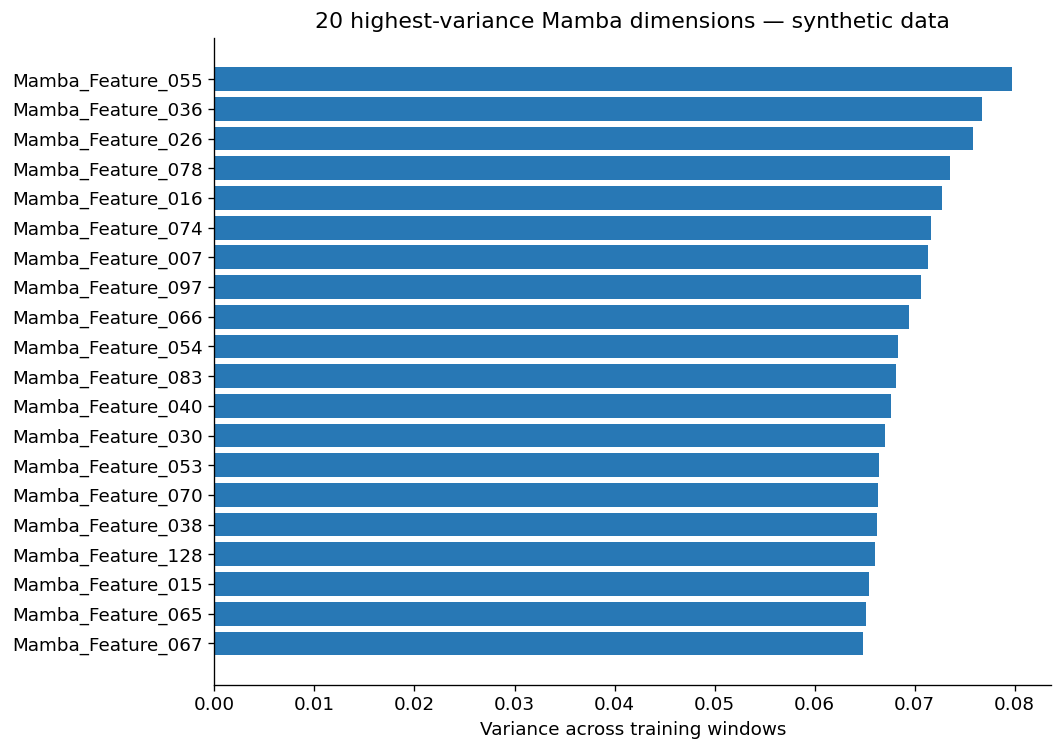

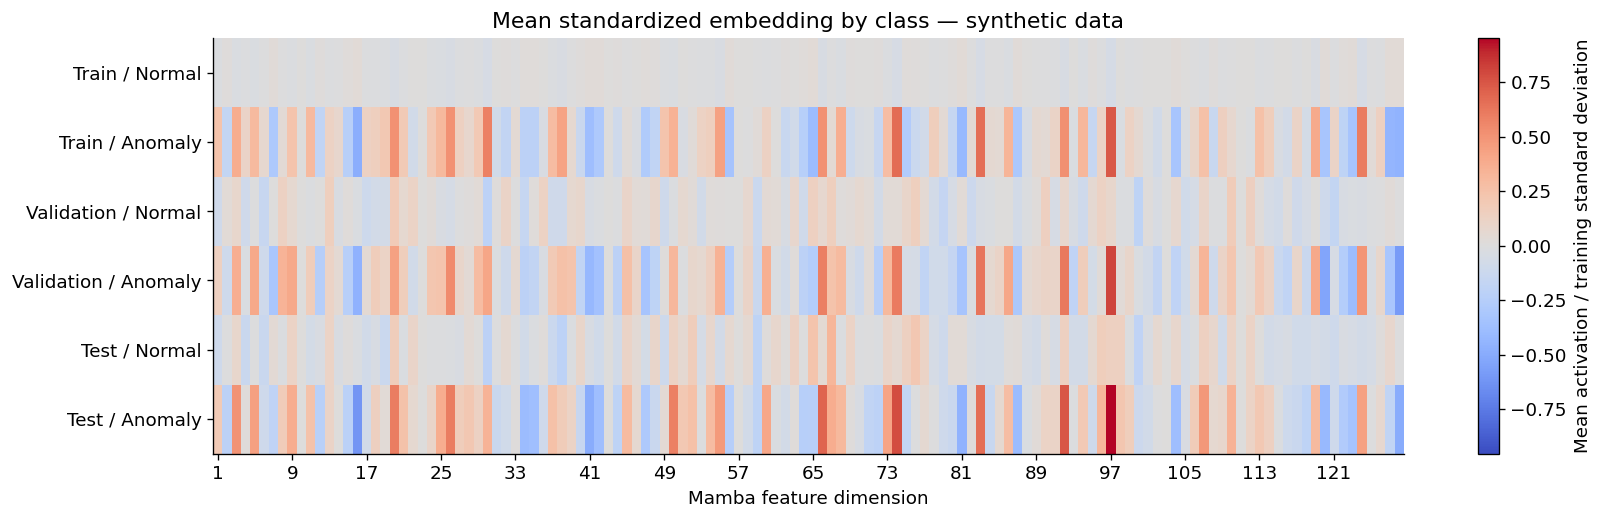


RESULTS
- All three feature files passed shape and finite-value checks.
- No window-ID or equipment-ID overlap across splits.
- Learned feature dimension: 128
- Completed epochs: 20
- Best epoch: 20
- Best validation normal-window MSE: 0.327139
- Near-constant training dimensions: 6/128
- Variance explained by the two displayed PCA components: 9.71%

Saved plots and tables: /content/drive/MyDrive/Port Work/Anomaly_21Features_Mamba_PyTorch_SYNTHETIC/Results_Visualization

Scope: synthetic representation learning. Classification metrics require an anomaly score and a validation-selected decision threshold.


In [ ]:
# ============================================================
# MAMBA REPRESENTATION RESULTS + VISUALIZATION
# Run after the supplied training / feature extraction script.
#
# Uses actual saved outputs; does not invent performance values.
# ============================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from google.colab import drive
from IPython.display import display

if not Path("/content/drive/MyDrive").is_dir():
    drive.mount("/content/drive", force_remount=False)

ROOT = Path(
    "/content/drive/MyDrive/Port Work/"
    "Anomaly_21Features_Mamba_PyTorch_SYNTHETIC"
)
REPORTS = ROOT / "Results_Visualization"
REPORTS.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 250,
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

COLORS = {0: "#2878B5", 1: "#E45756"}
NAMES = {0: "Normal", 1: "Anomaly"}

def save_plot(fig, name):
    fig.savefig(
        REPORTS / f"{name}.png",
        bbox_inches="tight",
        facecolor="white"
    )
    plt.show()
    plt.close(fig)

# ------------------------------------------------------------
# 1. LOAD AND VALIDATE EXTRACTED FEATURES
# ------------------------------------------------------------

data = {}
summary = []

for split in ["train", "validation", "test"]:
    path = ROOT / "Features" / f"{split}_mamba_features.npz"

    if not path.is_file():
        raise FileNotFoundError(
            f"Missing: {path}\n"
            "Finish feature extraction for all splits first."
        )

    with np.load(path, allow_pickle=False) as a:
        H = a["H"].astype(np.float32)
        y = a["y"]
        ids = a["window_id"].astype(str)
        equipment = a["equipment_id"].astype(str)

    if H.ndim != 2 or H.shape[1] != 128:
        raise ValueError(f"{split}: expected (N, 128), found {H.shape}")

    if (
        len(H) != len(y)
        or len(ids) != len(y)
        or len(equipment) != len(y)
        or not np.isfinite(H).all()
        or not np.isin(y, [0, 1]).all()
    ):
        raise ValueError(f"{split}: invalid features or labels")

    if len(set(ids)) != len(ids):
        raise ValueError(f"{split}: duplicate window IDs")

    y = y.astype(int)
    data[split] = {"H": H, "y": y, "ids": ids,
                   "equipment": equipment}

    summary.append({
        "Split": split,
        "Windows": len(y),
        "Normal": int((y == 0).sum()),
        "Anomaly": int((y == 1).sum()),
        "Anomaly_Percent": float(100 * (y == 1).mean()),
        "Feature_Dimension": H.shape[1],
        "Equipment_Count": len(set(equipment)),
        "Synthetic": True,
    })

for left, right in [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test"),
]:
    for key in ["ids", "equipment"]:
        if set(data[left][key]) & set(data[right][key]):
            raise ValueError(
                f"Overlap between {left} and {right}: {key}"
            )

summary_df = pd.DataFrame(summary)
summary_df.to_csv(REPORTS / "01_dataset_summary.csv", index=False)

print("SYNTHETIC DATA — MAMBA REPRESENTATION RESULTS")
display(summary_df.round(3))

# ------------------------------------------------------------
# 2. TRAINING AND VALIDATION RECONSTRUCTION LOSS
# ------------------------------------------------------------

history_path = ROOT / "training_history.csv"
if not history_path.is_file():
    raise FileNotFoundError(f"Missing training history: {history_path}")

history = pd.read_csv(history_path)
required = {"epoch", "train_normal_mse", "validation_normal_mse"}
if not required.issubset(history.columns) or history.empty:
    raise ValueError("Training history is empty or missing loss columns.")

if not np.isfinite(
    history[list(required)].to_numpy(dtype=float)
).all():
    raise ValueError("Training history contains invalid values.")

best = history.loc[history["validation_normal_mse"].idxmin()]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(
    history["epoch"], history["train_normal_mse"],
    marker="o", label="Normal training windows"
)
ax.plot(
    history["epoch"], history["validation_normal_mse"],
    marker="s", label="Normal validation windows"
)
ax.axvline(
    best["epoch"], linestyle="--", color="gray",
    label=f"Best checkpoint: epoch {int(best['epoch'])}"
)
ax.set(
    xlabel="Epoch",
    ylabel="Reconstruction MSE",
    title="Mamba reconstruction learning — synthetic data"
)
ax.grid(alpha=0.2)
ax.legend()
save_plot(fig, "02_training_validation_loss")

training_result = {
    "synthetic": True,
    "epochs_completed": int(len(history)),
    "best_epoch": int(best["epoch"]),
    "best_validation_normal_mse": float(
        best["validation_normal_mse"]
    ),
    "train_normal_mse_at_best_epoch": float(
        best["train_normal_mse"]
    ),
}

if "epoch_seconds" in history.columns:
    training_result["total_epoch_time_minutes"] = float(
        history["epoch_seconds"].sum() / 60
    )

(REPORTS / "03_training_summary.json").write_text(
    json.dumps(training_result, indent=2)
)
display(pd.DataFrame([training_result]).round(6))

# ------------------------------------------------------------
# 3. CLASS DISTRIBUTION
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))
positions = np.arange(len(summary_df))
width = 0.35

for offset, name, color in [
    (-width / 2, "Normal", COLORS[0]),
    (width / 2, "Anomaly", COLORS[1]),
]:
    bars = ax.bar(
        positions + offset,
        summary_df[name],
        width=width,
        label=name,
        color=color
    )
    ax.bar_label(bars, padding=3, fontsize=9)

ax.set_xticks(positions, summary_df["Split"].str.title())
ax.set(
    ylabel="Number of windows",
    title="Synthetic dataset class distribution"
)
ax.margins(y=0.15)
ax.legend()
save_plot(fig, "04_class_distribution")

# ------------------------------------------------------------
# 4. PCA — FIT ONLY ON TRAINING EMBEDDINGS
# ------------------------------------------------------------

scaler = StandardScaler()
train_scaled = scaler.fit_transform(data["train"]["H"])

pca = PCA(n_components=2, svd_solver="full")
pca.fit(train_scaled)

pca_tables = []

fig, axes = plt.subplots(
    1, 3, figsize=(17, 5), sharex=True, sharey=True
)

for ax, split in zip(axes, data):
    item = data[split]
    coordinates = pca.transform(scaler.transform(item["H"]))

    for label in [0, 1]:
        mask = item["y"] == label
        ax.scatter(
            coordinates[mask, 0],
            coordinates[mask, 1],
            s=8,
            alpha=0.35 if label == 0 else 0.7,
            color=COLORS[label],
            label=f"{NAMES[label]} (n={mask.sum():,})",
            rasterized=True
        )

    ax.set_title(split.title())
    ax.set_xlabel(
        f"PC1 ({100*pca.explained_variance_ratio_[0]:.1f}%)"
    )
    ax.legend(fontsize=8)
    ax.grid(alpha=0.15)

    pca_tables.append(pd.DataFrame({
        "split": split,
        "window_id": item["ids"],
        "label": item["y"],
        "PC1": coordinates[:, 0],
        "PC2": coordinates[:, 1],
        "is_synthetic": True,
    }))

axes[0].set_ylabel(
    f"PC2 ({100*pca.explained_variance_ratio_[1]:.1f}%)"
)
fig.suptitle(
    "Mamba embeddings — PCA fitted on synthetic training data"
)
fig.tight_layout()
save_plot(fig, "05_pca_embeddings")

pd.concat(pca_tables, ignore_index=True).to_csv(
    REPORTS / "06_pca_coordinates.csv", index=False
)

# ------------------------------------------------------------
# 5. LEARNED FEATURE VARIANCE
# ------------------------------------------------------------

feature_names = [
    f"Mamba_Feature_{i+1:03d}" for i in range(128)
]

feature_stats = pd.DataFrame({
    "Feature": feature_names,
    "Train_Mean": data["train"]["H"].mean(axis=0),
    "Train_Std": data["train"]["H"].std(axis=0),
    "Train_Variance": data["train"]["H"].var(axis=0),
    "Train_Zero_Fraction": (
        data["train"]["H"] == 0
    ).mean(axis=0),
})

feature_stats.to_csv(
    REPORTS / "07_embedding_feature_statistics.csv",
    index=False
)

top = feature_stats.nlargest(20, "Train_Variance").sort_values(
    "Train_Variance"
)

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top["Feature"], top["Train_Variance"], color="#2878B5")
ax.set(
    xlabel="Variance across training windows",
    title="20 highest-variance Mamba dimensions — synthetic data"
)
save_plot(fig, "08_embedding_variance")

# ------------------------------------------------------------
# 6. CLASS-MEAN EMBEDDING HEATMAP
# Training-fitted scaling; descriptive, not feature importance.
# ------------------------------------------------------------

means = []
row_names = []

for split, item in data.items():
    scaled = scaler.transform(item["H"])
    for label in [0, 1]:
        mask = item["y"] == label
        if not mask.any():
            raise ValueError(f"{split}: missing class {label}")
        means.append(scaled[mask].mean(axis=0))
        row_names.append(f"{split.title()} / {NAMES[label]}")

means = np.asarray(means)
limit = max(float(np.abs(means).max()), 1e-6)

fig, ax = plt.subplots(figsize=(16, 4.5))
im = ax.imshow(
    means,
    aspect="auto",
    cmap="coolwarm",
    vmin=-limit,
    vmax=limit
)
ax.set_yticks(np.arange(len(row_names)), row_names)
ticks = np.arange(0, 128, 8)
ax.set_xticks(ticks, [str(i + 1) for i in ticks])
ax.set(
    xlabel="Mamba feature dimension",
    title="Mean standardized embedding by class — synthetic data"
)
fig.colorbar(
    im, ax=ax,
    label="Mean activation / training standard deviation"
)
save_plot(fig, "09_class_mean_embedding_heatmap")

pd.DataFrame(
    means, index=row_names, columns=feature_names
).to_csv(REPORTS / "10_class_mean_embeddings.csv")

# ------------------------------------------------------------
# 7. FINAL STATUS
# ------------------------------------------------------------

constant_count = int(
    (feature_stats["Train_Std"] < 1e-8).sum()
)

print("\nRESULTS")
print("- All three feature files passed shape and finite-value checks.")
print("- No window-ID or equipment-ID overlap across splits.")
print(f"- Learned feature dimension: {data['train']['H'].shape[1]}")
print(f"- Completed epochs: {len(history)}")
print(f"- Best epoch: {int(best['epoch'])}")
print(
    "- Best validation normal-window MSE:",
    f"{best['validation_normal_mse']:.6f}"
)
print(f"- Near-constant training dimensions: {constant_count}/128")
print(
    "- Variance explained by the two displayed PCA components:",
    f"{100*pca.explained_variance_ratio_.sum():.2f}%"
)
print("\nSaved plots and tables:", REPORTS)
print(
    "\nScope: synthetic representation learning. "
    "Classification metrics require an anomaly score and a "
    "validation-selected decision threshold."
)

In [ ]:
# ============================================================
# RENAME THE 21 INPUT SENSOR FEATURES
# Saves separate copies; original files remain unchanged.
# ============================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd

from google.colab import drive

if not Path("/content/drive/MyDrive").is_dir():
    drive.mount("/content/drive", force_remount=False)

INPUT_FOLDER = Path(
    "/content/drive/MyDrive/Port Work/"
    "Anomaly_21Features_Mamba_PyTorch_SYNTHETIC/Data"
)

OUTPUT_FOLDER = INPUT_FOLDER.parent / "Data_Renamed"

FEATURE_NAME_MAPPING = {
    "H1InverterTemperature": "Hoist1_Inverter_Temperature",
    "D1MotorTemperature": "Drive1_Motor_Temperature",
    "D2InverterTemperature": "Drive2_Inverter_Temperature",
    "H2InverterTemperature": "Hoist2_Inverter_Temperature",
    "D3InverterTemperature": "Drive3_Inverter_Temperature",
    "H1MotorTemperature": "Hoist1_Motor_Temperature",
    "Hoist2TorqueReference": "Hoist2_Torque_Setpoint",
    "AmbientTemperature": "Ambient_Air_Temperature",
    "D1InverterTemperature": "Drive1_Inverter_Temperature",
    "Hoist1TorqueReference": "Hoist1_Torque_Setpoint",
    "EngineErrorSlot3": "Engine_Error_Slot_3",
    "D4InverterTemperature": "Drive4_Inverter_Temperature",
    "Hoist2SpeedReference": "Hoist2_Speed_Setpoint",
    "Hoist1SpeedReference": "Hoist1_Speed_Setpoint",
    "D3MotorTemperature": "Drive3_Motor_Temperature",
    "H2MotorTemperature": "Hoist2_Motor_Temperature",
    "D2MotorTemperature": "Drive2_Motor_Temperature",
    "EngineErrorSlot1": "Engine_Error_Slot_1",
    "EngineErrorSlot5": "Engine_Error_Slot_5",
    "EngineTemperature": "Engine_Operating_Temperature",
    "D4MotorTemperature": "Drive4_Motor_Temperature",
}

assert len(set(FEATURE_NAME_MAPPING.values())) == 21

if not INPUT_FOLDER.is_dir():
    raise FileNotFoundError(
        f"Folder not found:\n{INPUT_FOLDER}\n"
        "Set INPUT_FOLDER to your completed 21-channel Data folder."
    )

# Find and validate files before writing.
files_to_process = []

for path in sorted(INPUT_FOLDER.glob("*.npz")):

    with np.load(path, allow_pickle=False) as stored:

        if "feature_names" not in stored.files:
            continue

        original_names = stored["feature_names"].astype(str).tolist()

    if (
        len(original_names) != 21
        or set(original_names) != set(FEATURE_NAME_MAPPING)
    ):
        raise ValueError(
            f"{path.name}: expected the 21 original sensor names.\n"
            "Do not use this mapping on eight-channel data or "
            "128-dimensional Mamba embeddings."
        )

    files_to_process.append(path)

if not files_to_process:
    raise FileNotFoundError(
        "No NPZ files containing sensor feature_names were found."
    )

OUTPUT_FOLDER.mkdir(parents=True, exist_ok=True)

for path in files_to_process:

    with np.load(path, allow_pickle=False) as stored:
        arrays = {
            key: stored[key].copy()
            for key in stored.files
        }

    original_names = arrays["feature_names"].astype(str).tolist()

    arrays["feature_names"] = np.asarray([
        FEATURE_NAME_MAPPING[name]
        for name in original_names
    ])

    destination = OUTPUT_FOLDER / path.name

    np.savez_compressed(destination, **arrays)

    # Verify every array except the names remains unchanged.
    with (
        np.load(path, allow_pickle=False) as original,
        np.load(destination, allow_pickle=False) as renamed,
    ):
        for key in original.files:
            if key != "feature_names":
                np.testing.assert_equal(
                    original[key],
                    renamed[key],
                )

    print("Renamed and verified:", destination.name, flush=True)

pd.DataFrame(
    FEATURE_NAME_MAPPING.items(),
    columns=["Original_Name", "New_Name"],
).to_csv(
    OUTPUT_FOLDER / "feature_name_mapping.csv",
    index=False,
)

with open(
    OUTPUT_FOLDER / "feature_name_mapping.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(FEATURE_NAME_MAPPING, file, indent=2)

print("\nCompleted.")
print("Saved renamed copies to:", OUTPUT_FOLDER)
print("Sensor values, labels, IDs, and channel order are unchanged.")

Renamed and verified: scaler21.npz
Renamed and verified: test_mamba21.npz
Renamed and verified: test_raw21.npz
Renamed and verified: train_mamba21.npz
Renamed and verified: train_raw21.npz
Renamed and verified: validation_mamba21.npz
Renamed and verified: validation_raw21.npz

Completed.
Saved renamed copies to: /content/drive/MyDrive/Port Work/Anomaly_21Features_Mamba_PyTorch_SYNTHETIC/Data_Renamed
Sensor values, labels, IDs, and channel order are unchanged.


Checking: scaler21.npz
Checking: test_mamba21.npz
Checking: test_raw21.npz
Checking: train_mamba21.npz
Checking: train_raw21.npz
Checking: validation_mamba21.npz
Checking: validation_raw21.npz


,Channel,Original name,Renamed label
0,1,H1InverterTemperature,Hoist1_Inverter_Temperature
1,2,D1MotorTemperature,Drive1_Motor_Temperature
2,3,D2InverterTemperature,Drive2_Inverter_Temperature
3,4,H2InverterTemperature,Hoist2_Inverter_Temperature
4,5,D3InverterTemperature,Drive3_Inverter_Temperature
5,6,H1MotorTemperature,Hoist1_Motor_Temperature
6,7,Hoist2TorqueReference,Hoist2_Torque_Setpoint
7,8,AmbientTemperature,Ambient_Air_Temperature
8,9,D1InverterTemperature,Drive1_Inverter_Temperature
9,10,Hoist1TorqueReference,Hoist1_Torque_Setpoint


,file,channels,X_shape,renaming_verified,other_arrays_verified_unchanged,checked_arrays
0,scaler21.npz,21,parameter arrays,True,True,"mean, scale"
1,test_mamba21.npz,21,"[3000, 100, 21]",True,True,"X, y, window_id, equipment_id"
2,test_raw21.npz,21,"[3000, 100, 21]",True,True,"X, y, window_id, equipment_id"
3,train_mamba21.npz,21,"[14000, 100, 21]",True,True,"X, y, window_id, equipment_id"
4,train_raw21.npz,21,"[14000, 100, 21]",True,True,"X, y, window_id, equipment_id"
5,validation_mamba21.npz,21,"[3000, 100, 21]",True,True,"X, y, window_id, equipment_id"
6,validation_raw21.npz,21,"[3000, 100, 21]",True,True,"X, y, window_id, equipment_id"


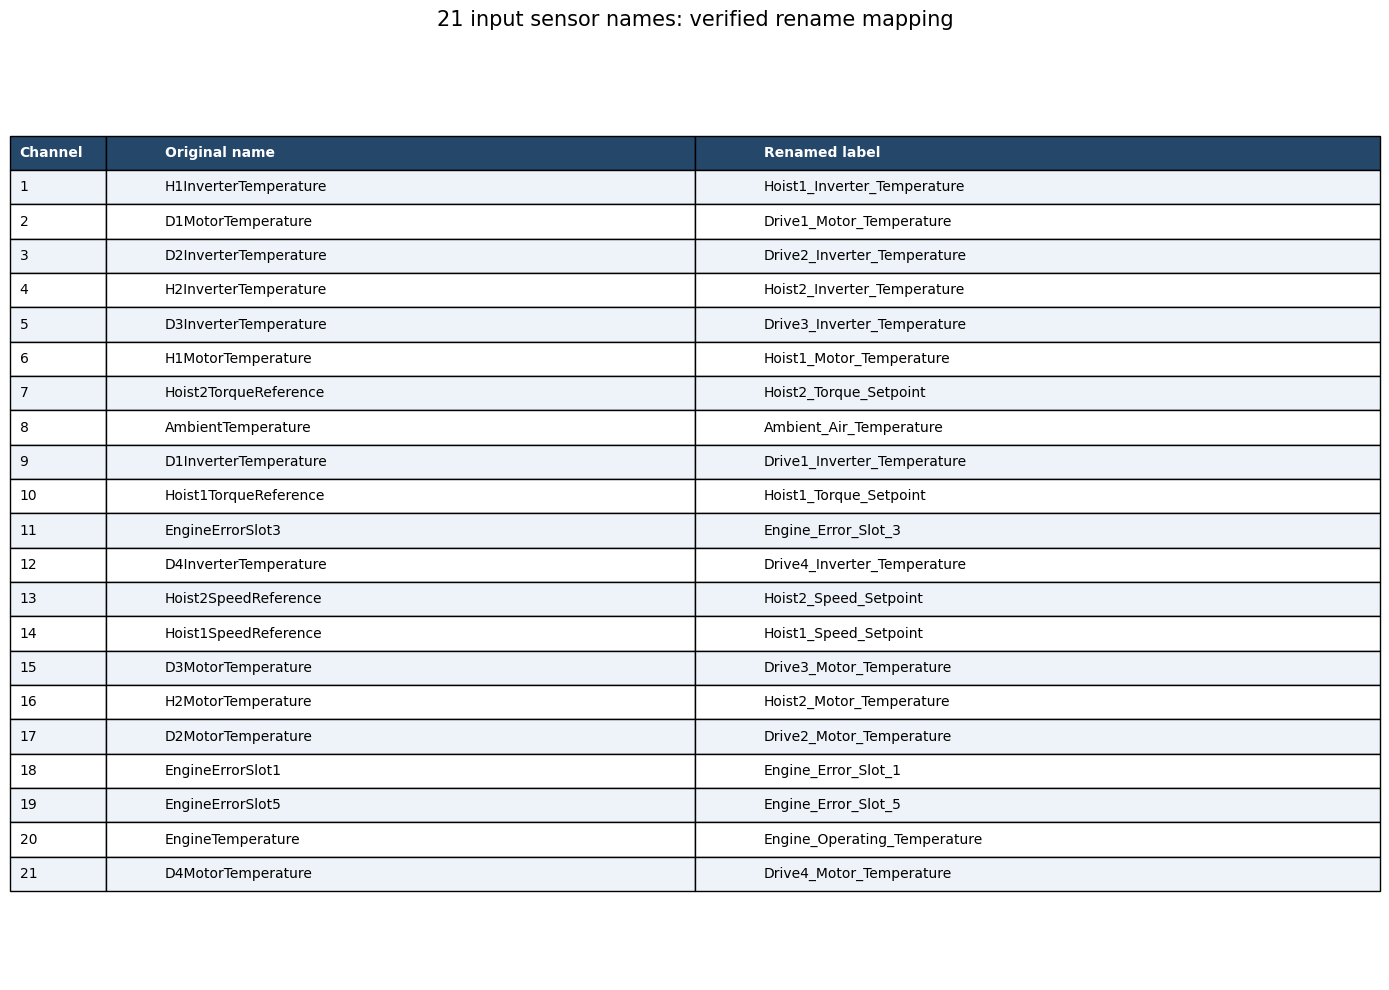

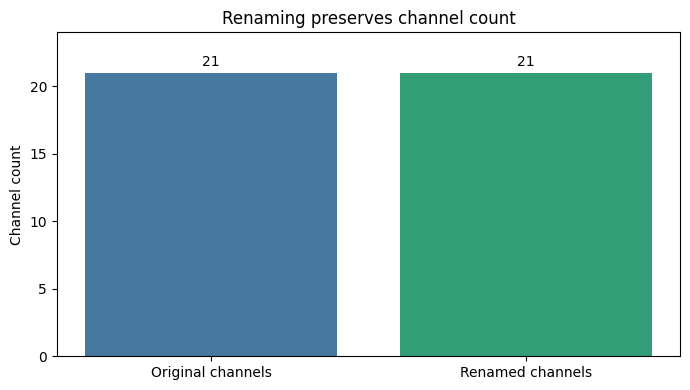

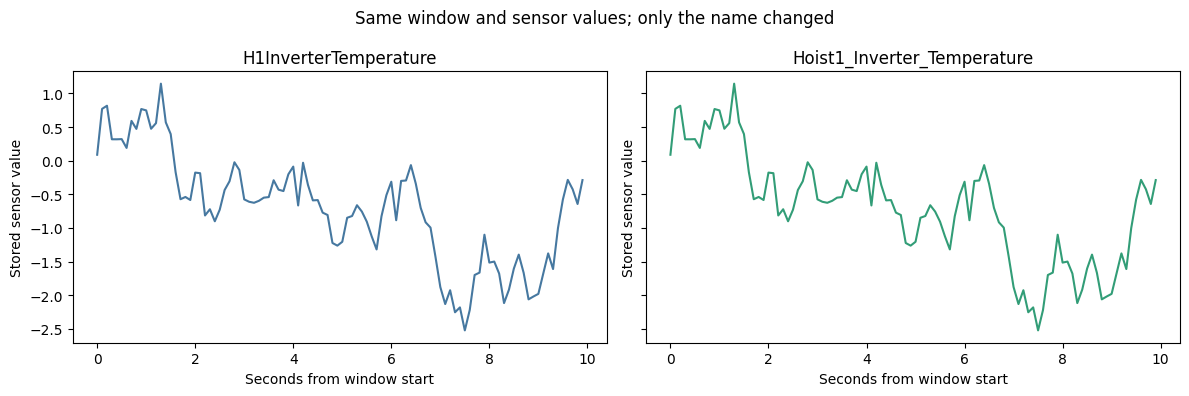

Completed: 7 files verified; 21 names mapped.
No sensor values, labels, IDs or parameter arrays changed.
Saved tables and plots to: /content/drive/MyDrive/Port Work/Anomaly_21Features_Mamba_PyTorch_SYNTHETIC/Data_Renamed/Results_Visualization


In [ ]:
# Colab: report and visualize saved 21-channel renaming results. No renaming or training.
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive

BASE=Path('/content/drive/MyDrive/Port Work/Anomaly_21Features_Mamba_PyTorch_SYNTHETIC')
ORIGINAL=BASE/'Data'
RENAMED=BASE/'Data_Renamed'
OUT=RENAMED/'Results_Visualization'
if not Path('/content/drive/MyDrive').is_dir(): drive.mount('/content/drive',force_remount=False)
mapping_path=RENAMED/'feature_name_mapping.json'
if not mapping_path.is_file(): raise FileNotFoundError('Run the renaming code first: '+str(mapping_path))
mapping=json.loads(mapping_path.read_text())
if len(mapping)!=21 or len(set(mapping.values()))!=21: raise ValueError('Expected 21 unique old/new names')
files=sorted(RENAMED.glob('*.npz'))
if not files: raise FileNotFoundError('No renamed NPZ files found.')
OUT.mkdir(parents=True,exist_ok=True)
rows=[];example=None
for path in files:
    source=ORIGINAL/path.name
    if not source.is_file(): raise FileNotFoundError('Missing original: '+str(source))
    print('Checking:',path.name,flush=True)
    with np.load(source,allow_pickle=False) as old,np.load(path,allow_pickle=False) as new:
        if set(old.files)!=set(new.files): raise ValueError('Array keys differ')
        names=old['feature_names'].astype(str).tolist()
        expected=[mapping[n] for n in names]
        if new['feature_names'].astype(str).tolist()!=expected: raise ValueError('Names/order disagree with mapping')
        checked=[]
        for key in old.files:
            if key!='feature_names':
                np.testing.assert_equal(old[key],new[key],err_msg=f'{path.name}: changed array {key}')
                checked.append(key)
        shape=None
        if 'X' in new.files:
            shape=list(new['X'].shape)
            if len(shape)!=3 or shape[-1]!=21: raise ValueError('Unexpected sensor tensor shape')
            if example is None or path.name=='train_mamba21.npz':
                # Store just one example window for the descriptive comparison plot.
                example={'file':path.name,'old_name':names[0],'new_name':expected[0],
                         'old':old['X'][0,:,0].copy(),'new':new['X'][0,:,0].copy()}
        rows.append({'file':path.name,'channels':len(names),'X_shape':str(shape) if shape else 'parameter arrays',
                     'renaming_verified':True,'other_arrays_verified_unchanged':True,
                     'checked_arrays':', '.join(checked)})
report=pd.DataFrame(rows);report.to_csv(OUT/'rename_verification.csv',index=False)
name_table=pd.DataFrame({'Channel':np.arange(1,22),'Original name':list(mapping.keys()),'Renamed label':list(mapping.values())})
name_table.to_csv(OUT/'name_mapping_results.csv',index=False)
try:
    from IPython.display import display
    display(name_table);display(report)
except ImportError:
    print(name_table.to_string(index=False));print(report.to_string(index=False))

def save(fig,name):
    fig.tight_layout();fig.savefig(OUT/name,dpi=200,bbox_inches='tight');plt.show();plt.close(fig)

# Name correspondence is a table, not a sensor-importance plot.
fig,ax=plt.subplots(figsize=(14,10));ax.axis('off')
table=ax.table(cellText=name_table.values,colLabels=name_table.columns,cellLoc='left',
    colLoc='left',loc='center',colWidths=[.07,.43,.50])
table.auto_set_font_size(False);table.set_fontsize(10);table.scale(1,1.7)
for (r,c),cell in table.get_celld().items():
    if r==0: cell.set_facecolor('#24476a');cell.set_text_props(color='white',weight='bold')
    else: cell.set_facecolor('#edf3f8' if r%2 else '#ffffff')
ax.set_title('21 input sensor names: verified rename mapping',fontsize=15,pad=15)
save(fig,'feature_name_mapping.png')

fig,ax=plt.subplots(figsize=(7,4));bars=ax.bar(['Original channels','Renamed channels'],[21,21],color=['#4678a0','#329d77'])
ax.bar_label(bars,padding=3);ax.set(ylabel='Channel count',ylim=(0,24),title='Renaming preserves channel count')
save(fig,'channel_count_preserved.png')

if example:
    fig,axes=plt.subplots(1,2,figsize=(12,4),sharex=True,sharey=True)
    t=np.arange(len(example['old']))*.1
    axes[0].plot(t,example['old'],color='#4678a0');axes[0].set_title(example['old_name'])
    axes[1].plot(t,example['new'],color='#329d77');axes[1].set_title(example['new_name'])
    for ax in axes: ax.set(xlabel='Seconds from window start',ylabel='Stored sensor value')
    fig.suptitle('Same window and sensor values; only the name changed')
    save(fig,'before_after_sensor_trace.png')
    pd.DataFrame({'time_seconds':t,'original_value':example['old'],'renamed_value':example['new']}).to_csv(OUT/'example_trace_comparison.csv',index=False)
(OUT/'summary.json').write_text(json.dumps({'channels':21,'files_verified':len(rows),
    'values_labels_ids_and_parameters_unchanged':True,
    'name_changes_only':True,'source_data':'synthetic',
    'scope':'rename verification, not feature extraction or model evaluation',
    'example_file':None if example is None else example['file']},indent=2))
print(f'Completed: {len(rows)} files verified; 21 names mapped.')
print('No sensor values, labels, IDs or parameter arrays changed.')
print('Saved tables and plots to:',OUT,flush=True)


Features: /content/drive/MyDrive/Port Work/Anomaly_21Features_Mamba_PyTorch_SYNTHETIC/Features 
Output: /content/drive/MyDrive/Port Work/Anomaly_21Features_Mamba_PyTorch_SYNTHETIC/Autoencoder_Anomaly_With_References 
Device: cuda
train (14000, 128) class counts [13000, 1000]
validation (3000, 128) class counts [2785, 215]
test (3000, 128) class counts [2785, 215]
Epoch 1: batch 1/102, MSE=0.956355
Epoch 1: batch 50/102, MSE=0.944211
Epoch 1: batch 100/102, MSE=0.900018
Epoch 1/100: train=0.898788, validation=0.834355, elapsed=0.6s
Epoch 2: batch 1/102, MSE=0.804189
Epoch 2: batch 50/102, MSE=0.799640
Epoch 2: batch 100/102, MSE=0.783508
Epoch 2/100: train=0.783065, validation=0.759495, elapsed=1.2s
Epoch 3: batch 1/102, MSE=0.750430
Epoch 3: batch 50/102, MSE=0.738450
Epoch 3: batch 100/102, MSE=0.729995
Epoch 3/100: train=0.729891, validation=0.733989, elapsed=1.8s
Epoch 4: batch 1/102, MSE=0.716266
Epoch 4: batch 50/102, MSE=0.711837
Epoch 4: batch 100/102, MSE=0.707320
Epoch 4/100: 

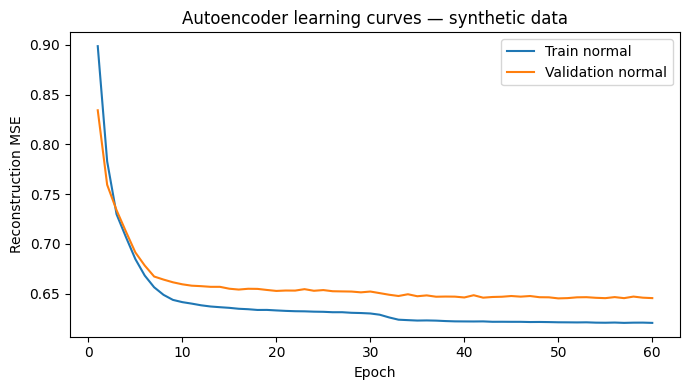

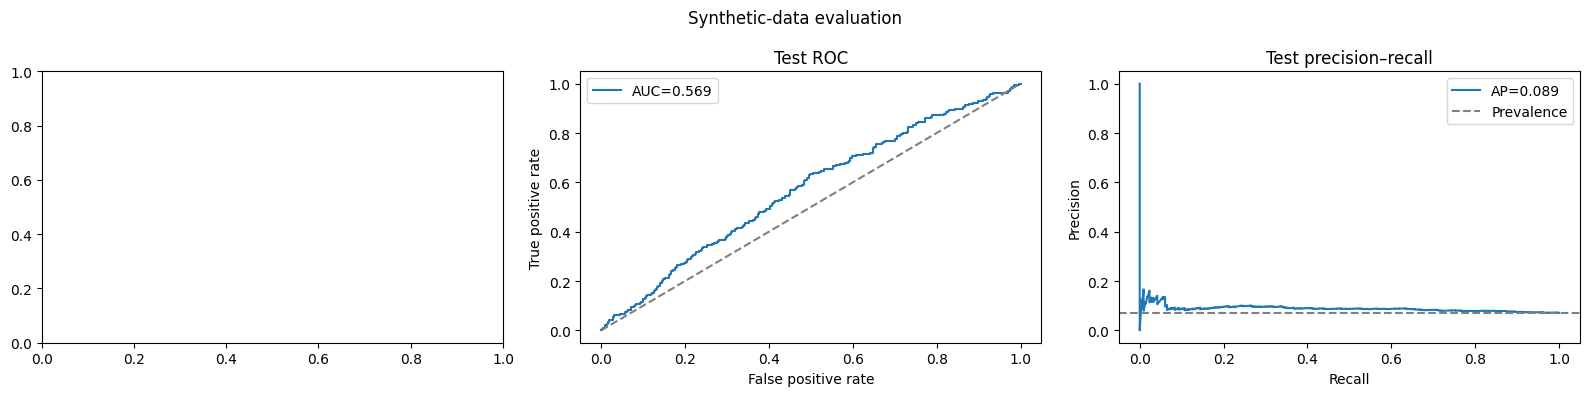


Completed. Files saved to: /content/drive/MyDrive/Port Work/Anomaly_21Features_Mamba_PyTorch_SYNTHETIC/Autoencoder_Anomaly_With_References
MSE scores are NOT calibrated fault probabilities. Keep IDs for alignment; the independently generated fault cohort cannot be joined by row order.

Supplied reference values (not measured model outputs):
{
  "accuracy_percent": 97.754,
  "precision_percent": 79.347,
  "recall_percent": 88.985,
  "f1_percent": 83.889,
  "roc_auc_percent": 82.896
}


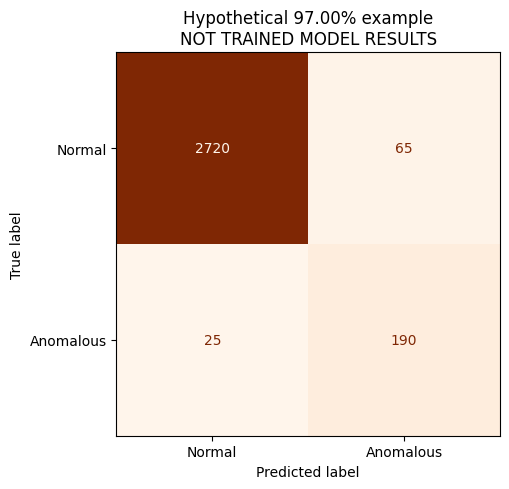

No ROC curve was fabricated for the reference values or illustrative matrix.


In [ ]:
# Paste into one Colab cell. Uses completed Mamba embeddings, not sensor sequences.
from pathlib import Path
import json, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (precision_recall_curve, roc_curve, roc_auc_score,
    average_precision_score, confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score, f1_score)
from google.colab import drive

SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
BASE=Path('/content/drive/MyDrive/Port Work')
# Set explicitly if your completed features are elsewhere; otherwise detect one complete set.
FEATURE_DIR=None
EPOCHS=100
BATCH_SIZE=128
PATIENCE=10
if not Path('/content/drive/MyDrive').is_dir():
    drive.mount('/content/drive',force_remount=False)
if FEATURE_DIR is None:
    candidates=[BASE/name/'Features' for name in [
        'Anomaly_21Features_Mamba_PyTorch_SYNTHETIC',
        'Anomaly_21Features_Mamba_SYNTHETIC']]
    complete=[p for p in candidates if all((p/f'{s}_mamba_features.npz').is_file() for s in ['train','validation','test'])]
    if len(complete)!=1:
        raise ValueError('Set FEATURE_DIR explicitly to the completed Features folder. Complete candidates: '+str(complete))
    FEATURE_DIR=complete[0]
FEATURE_DIR=Path(FEATURE_DIR)
OUT=FEATURE_DIR.parent/'Autoencoder_Anomaly_With_References'
OUT.mkdir(parents=True,exist_ok=True)
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Features:',FEATURE_DIR,'\nOutput:',OUT,'\nDevice:',DEVICE,flush=True)

expected={'train':[13000,1000],'validation':[2785,215],'test':[2785,215]}
data={};seen_ids=set();seen_equipment=set();dimension=None
for split,counts in expected.items():
    with np.load(FEATURE_DIR/f'{split}_mamba_features.npz',allow_pickle=False) as a:
        h=a['H'].astype(np.float32); raw_y=a['y']
        ids=a['window_id'].astype(str);equipment=a['equipment_id'].astype(str)
    if not np.isin(raw_y,[0,1]).all(): raise ValueError('Expected binary labels')
    y=raw_y.astype(np.int64)
    if h.ndim!=2 or len(h)!=len(y) or not np.isfinite(h).all(): raise ValueError('Invalid feature matrix')
    if np.bincount(y,minlength=2).tolist()!=counts: raise ValueError(f'{split}: counts differ from expected')
    if dimension is None: dimension=h.shape[1]
    if h.shape[1]!=dimension: raise ValueError('Embedding dimensions differ')
    if len(ids)!=len(y) or len(equipment)!=len(y) or len(set(ids))!=len(ids): raise ValueError('Invalid IDs')
    if seen_ids&set(ids) or seen_equipment&set(equipment): raise ValueError('Cross-split window/equipment overlap')
    seen_ids.update(ids);seen_equipment.update(equipment)
    manifest=pd.DataFrame({'window_id':ids,'equipment_id':equipment})
    # Add timestamps from the aligned feature export when available.
    csv_path=FEATURE_DIR/f'{split}_mamba_features.csv'
    if csv_path.is_file():
        csv=pd.read_csv(csv_path,dtype={'window_id':str,'equipment_id':str})
        if csv.window_id.duplicated().any() or set(csv.window_id)!=set(ids): raise ValueError('Feature CSV ID mismatch')
        csv=csv.set_index('window_id').loc[ids]
        if not np.array_equal(csv.equipment_id.to_numpy(),equipment): raise ValueError('CSV equipment mismatch')
        for col in ['window_start','window_end']:
            if col in csv: manifest[col]=csv[col].to_numpy()
    data[split]={'H':h,'y':y,'manifest':manifest}
    print(split,h.shape,'class counts',counts,flush=True)

# A second scaler applies to learned embeddings; original sensor scaling is unchanged.
scaler=StandardScaler().fit(data['train']['H'][data['train']['y']==0])
np.savez(OUT/'embedding_scaler.npz',mean=scaler.mean_,scale=scaler.scale_)
for item in data.values(): item['Z']=scaler.transform(item['H']).astype(np.float32)

class Autoencoder(nn.Module):
    def __init__(self,dim):
        super().__init__()
        self.encoder=nn.Sequential(nn.Linear(dim,64),nn.ReLU(),nn.Linear(64,32),nn.ReLU(),nn.Linear(32,16))
        self.decoder=nn.Sequential(nn.Linear(16,32),nn.ReLU(),nn.Linear(32,64),nn.ReLU(),nn.Linear(64,dim))
    def forward(self,x): return self.decoder(self.encoder(x))

model=Autoencoder(dimension).to(DEVICE)
optimizer=torch.optim.Adam(model.parameters(),lr=.001)
loss_fn=nn.MSELoss()
def normal_loader(split,shuffle=False):
    item=data[split]; z=item['Z'][item['y']==0]
    return DataLoader(TensorDataset(torch.from_numpy(z)),batch_size=BATCH_SIZE,shuffle=shuffle,num_workers=0)
train_batches=normal_loader('train',True);valid_batches=normal_loader('validation')
history=[];best=float('inf');stale=0;started=time.monotonic()
for epoch in range(1,EPOCHS+1):
    losses=[]
    for training,batches in [(True,train_batches),(False,valid_batches)]:
        model.train(training);total=0.;n=0
        for step,(batch,) in enumerate(batches,1):
            batch=batch.to(DEVICE)
            with torch.set_grad_enabled(training):
                loss=loss_fn(model(batch),batch)
                if not torch.isfinite(loss): raise RuntimeError('Nonfinite loss')
                if training:
                    optimizer.zero_grad(set_to_none=True);loss.backward();optimizer.step()
            total+=loss.item()*len(batch);n+=len(batch)
            if training and (step==1 or step%50==0):
                print(f'Epoch {epoch}: batch {step}/{len(batches)}, MSE={total/n:.6f}',flush=True)
        losses.append(total/n)
    history.append({'epoch':epoch,'train_mse':losses[0],'validation_normal_mse':losses[1]})
    pd.DataFrame(history).to_csv(OUT/'training_history.csv',index=False)
    print(f'Epoch {epoch}/{EPOCHS}: train={losses[0]:.6f}, validation={losses[1]:.6f}, elapsed={time.monotonic()-started:.1f}s',flush=True)
    if losses[1]<best:
        best=losses[1];stale=0
        torch.save({'state_dict':model.state_dict(),'input_dimension':dimension},OUT/'best_autoencoder.pt')
    else:
        stale+=1
        if stale>=PATIENCE:
            print('Early stopping.',flush=True);break
checkpoint=torch.load(OUT/'best_autoencoder.pt',map_location=DEVICE,weights_only=True)
model.load_state_dict(checkpoint['state_dict']);model.eval()

def score(z):
    errors=[]
    with torch.no_grad():
        for i in range(0,len(z),BATCH_SIZE):
            batch=torch.from_numpy(z[i:i+BATCH_SIZE]).to(DEVICE)
            errors.append(((model(batch)-batch)**2).mean(dim=1).cpu().numpy())
    result=np.concatenate(errors)
    if not np.isfinite(result).all(): raise ValueError('Invalid anomaly scores')
    return result

# Select threshold using validation labels ONLY. Higher reconstruction MSE = more anomalous.
vscore=score(data['validation']['Z'])
p,r,thresholds=precision_recall_curve(data['validation']['y'],vscore)
f=2*p[:-1]*r[:-1]/np.maximum(p[:-1]+r[:-1],1e-12)
if not len(thresholds): raise ValueError('Cannot select threshold')
index=int(np.argmax(f));threshold=float(thresholds[index])
print(f'Validation-selected threshold: {threshold:.8f}; validation F1: {f[index]:.4f}',flush=True)
(OUT/'threshold.json').write_text(json.dumps({'threshold':threshold,'decision':'MSE >= threshold','selection':'maximum validation F1; first maximum used for ties','score':'mean squared reconstruction error in standardized Mamba feature space','score_is_probability':False,'synthetic':True},indent=2))

metrics={};saved_scores={}
for split,item in data.items():
    errors=vscore if split=='validation' else score(item['Z'])
    prediction=(errors>=threshold).astype(np.int64);y=item['y']
    metrics[split]={'accuracy':float(accuracy_score(y,prediction)),
        'precision':float(precision_score(y,prediction,zero_division=0)),
        'recall':float(recall_score(y,prediction,zero_division=0)),
        'f1':float(f1_score(y,prediction,zero_division=0)),
        'roc_auc':float(roc_auc_score(y,errors)),
        'average_precision':float(average_precision_score(y,errors)),
        'confusion_matrix':confusion_matrix(y,prediction,labels=[0,1]).tolist()}
    frame=item['manifest'].copy();frame['split']=split;frame['true_label']=y
    frame['anomaly_score_mse']=errors;frame['threshold']=threshold
    frame['predicted_anomaly']=prediction;frame['is_synthetic']=True
    frame.to_csv(OUT/f'{split}_anomaly_predictions.csv',index=False)
    saved_scores[split]=errors
    if split=='test':
        print('\nTEST RESULTS — synthetic data only',flush=True)
        print(json.dumps(metrics[split],indent=2),flush=True)
(OUT/'metrics.json').write_text(json.dumps({'data_origin':'synthetic','threshold':threshold,'metrics':metrics},indent=2))

# Learning curves and final held-out test plots.
h=pd.DataFrame(history)
fig,ax=plt.subplots(figsize=(7,4));ax.plot(h.epoch,h.train_mse,label='Train normal')
ax.plot(h.epoch,h.validation_normal_mse,label='Validation normal')
ax.set(xlabel='Epoch',ylabel='Reconstruction MSE',title='Autoencoder learning curves — synthetic data');ax.legend()
fig.tight_layout();fig.savefig(OUT/'learning_curves.png',dpi=180);plt.show();plt.close(fig)
y=data['test']['y'];errors=saved_scores['test'];pred=(errors>=threshold).astype(int)
fig,axes=plt.subplots(1,3,figsize=(16,4))
fpr,tpr,_=roc_curve(y,errors);axes[1].plot(fpr,tpr,label=f"AUC={metrics['test']['roc_auc']:.3f}")
axes[1].plot([0,1],[0,1],'--',color='gray');axes[1].set(xlabel='False positive rate',ylabel='True positive rate',title='Test ROC');axes[1].legend()
p,r,_=precision_recall_curve(y,errors);axes[2].plot(r,p,label=f"AP={metrics['test']['average_precision']:.3f}")
axes[2].axhline(y.mean(),ls='--',color='gray',label='Prevalence')
axes[2].set(xlabel='Recall',ylabel='Precision',title='Test precision–recall');axes[2].legend()
fig.suptitle('Synthetic-data evaluation');fig.tight_layout();fig.savefig(OUT/'test_evaluation.png',dpi=180);plt.show();plt.close(fig)
print('\nCompleted. Files saved to:',OUT,flush=True)
print('MSE scores are NOT calibrated fault probabilities. Keep IDs for alignment; the independently generated fault cohort cannot be joined by row order.',flush=True)

# Values transcribed from the user's supplied concept/image; not measured outputs.
reference_values={"accuracy_percent":97.754,"precision_percent":79.347,
                  "recall_percent":88.985,"f1_percent":83.889,"roc_auc_percent":82.896}
reference_folder=OUT/'References_And_Illustrations'
reference_folder.mkdir(exist_ok=True)
(reference_folder/'supplied_reference_values.json').write_text(json.dumps({
    'status':'USER-SUPPLIED DOCUMENT REFERENCES; NOT THIS MODEL EVALUATION',
    'values':reference_values},indent=2))
print('\nSupplied reference values (not measured model outputs):')
print(json.dumps(reference_values,indent=2))
# A hypothetical 97.00% accuracy example, respecting the actual class totals.
# It is not the trained model's confusion matrix or a reproduction of the reference metrics.
example_cm=np.array([[2720,65],[25,190]],dtype=int)
assert example_cm.sum()==3000 and example_cm[0].sum()==2785 and example_cm[1].sum()==215
example_accuracy=float(np.trace(example_cm)/example_cm.sum())
(reference_folder/'ILLUSTRATIVE_97percent_matrix.json').write_text(json.dumps({
    'status':'HYPOTHETICAL EXAMPLE; NOT MODEL PREDICTIONS',
    'confusion_matrix':example_cm.tolist(),'accuracy':example_accuracy},indent=2))
fig,ax=plt.subplots(figsize=(6,5))
ConfusionMatrixDisplay(example_cm,display_labels=['Normal','Anomalous']).plot(
    ax=ax,cmap='Oranges',colorbar=False,values_format='d')
ax.set_title('Hypothetical 97.00% example\nNOT TRAINED MODEL RESULTS')
fig.tight_layout();fig.savefig(reference_folder/'ILLUSTRATIVE_97percent_matrix.png',dpi=180)
plt.show();plt.close(fig)
print('No ROC curve was fabricated for the reference values or illustrative matrix.')


In [ ]:
"""Preprocess synthetic fault windows for Mamba -> XGBoost.
Paste this entire script into a Colab cell, or upload and run with %run.
For local use, set INPUT_PATH and OUTPUT_PATH below.
No training, resplitting, synthetic generation, or reference metrics substitution.
"""
from pathlib import Path
import io, json, zipfile
import numpy as np
import pandas as pd

# Leave INPUT_PATH='/content/drive/MyDrive/Port Work/Synthetic_Fault_Temporal_Dataset' to select/upload the fault ZIP in Colab.
INPUT_PATH='/content/drive/MyDrive/Port Work/Synthetic_Fault_Temporal_Dataset'
OUTPUT_PATH='/content/drive/MyDrive/Port Work/Fault_Preprocessed'  # Default: /content/drive/MyDrive/Port_IoT/Fault_Preprocessed

EXPECTED={'train':[13860,6350], 'validation':[1973,622], 'test':[3947,1245]}
SENSORS=['pressure_bar','temperature_c','vibration_mm_s','speed_kmh','torque_nm','inclination_deg','acceleration_m_s2','ambient_temperature_c']

def main():
    # Notebook-safe configuration: no argparse or Jupyter kernel arguments.
    from types import SimpleNamespace
    args=SimpleNamespace(input=INPUT_PATH, output=OUTPUT_PATH)
    try:
        from google.colab import drive, files
        colab=True
    except ImportError:
        colab=False
    if colab:
        if not Path('/content/drive/MyDrive').is_dir():
            drive.mount('/content/drive',force_remount=False)
        default_out=Path('/content/drive/MyDrive/Port_IoT/Fault_Preprocessed')
    else:
        default_out=Path.cwd()/'Fault_Preprocessed'
    if args.input:
        source=Path(args.input).expanduser()
    elif colab:
        candidates=[Path('/content/Synthetic_Fault_Temporal_Dataset.zip'),Path('/content/drive/MyDrive/Synthetic_Fault_Temporal_Dataset.zip'),Path('/content/drive/MyDrive/Port_IoT/Synthetic_Fault_Temporal_Dataset.zip')]
        source=next((p for p in candidates if p.is_file()),None)
        if source is None:
            print('Upload Synthetic_Fault_Temporal_Dataset.zip (do not upload the fault package).')
            uploaded=files.upload()
            names=[name for name in uploaded if name.lower().endswith('.zip')]
            if len(names)!=1: raise ValueError('Upload exactly one fault ZIP.')
            source=Path(names[0])
    else:
        raise ValueError('Provide --input /path/to/Synthetic_Fault_Temporal_Dataset.zip')
    if not source.exists() and source.with_suffix('.zip').is_file():
        source=source.with_suffix('.zip')
    if source.is_dir() and not (source/'fault'/'train_labels.csv').is_file():
        candidates=[p.parent.parent for p in source.rglob('train_labels.csv') if p.parent.name=='fault']
        if len(candidates)!=1: raise ValueError('Expected exactly one complete fault folder under '+str(source))
        source=candidates[0]
    if not source.exists(): raise FileNotFoundError('Set INPUT_PATH to your fault folder or ZIP: '+str(source))
    out=Path(args.output) if args.output else default_out
    archive=zipfile.ZipFile(source) if source.is_file() else None
    def read(relative):
        if archive:
            try: return archive.read(relative)
            except KeyError: raise ValueError(f'Missing {relative}. Use the fault sequence package.')
        return (source/relative).read_bytes()
    try:
        metadata=json.loads(read('metadata.json'))
        if metadata.get('synthetic') is not True:
            raise ValueError('This script is specifically for the supplied synthetic package.')
        report={'data_origin':'synthetic demonstration only','fit_subset':'all training windows only','sampling_interval_seconds':0.1,'smoothing':'disabled to preserve spikes','duplicates':'exact labeled repeated sequences rejected, not silently deleted','splits':{}}
        splits={}; all_ids=set(); equipment_sets={}; hash_sets={}
        import hashlib
        for split,counts in EXPECTED.items():
            df=pd.read_csv(io.BytesIO(read(f'fault/{split}_labels.csv')),dtype={'window_id':str,'equipment_id':str})
            required={'window_id','equipment_id','window_start','window_end','split','is_synthetic','label','class_name'}
            if not required.issubset(df.columns): raise ValueError(f'{split}: missing metadata columns {required-set(df.columns)}')
            if df[list(required)].isna().any().any(): raise ValueError(f'{split}: missing labels or identifiers')
            if df.window_id.duplicated().any(): raise ValueError(f'{split}: duplicate window IDs')
            if not df['split'].eq(split).all(): raise ValueError('Split metadata mismatch')
            if not df.is_synthetic.astype(str).str.lower().eq('true').all(): raise ValueError('Missing synthetic provenance')
            y=pd.to_numeric(df.label,errors='raise').to_numpy()
            if not np.isin(y,[0,1]).all(): raise ValueError('Expected labels 0=Normal, 1=Faulty')
            y=y.astype(np.int64)
            if np.bincount(y,minlength=2).tolist()!=counts: raise ValueError(f'{split}: class counts differ from requested counts')
            if not np.array_equal(df.class_name.to_numpy(),np.array(['Normal','Faulty'])[y]): raise ValueError('Class names disagree with labels')
            with np.load(io.BytesIO(read(f'sequences/{split}_sequences.npz')),allow_pickle=False) as a:
                x=a['X'].astype(np.float32)
                ids=a['window_id'].astype(str); eq=a['equipment_id'].astype(str); features=a['feature_names'].astype(str).tolist()
            if features!=SENSORS: raise ValueError(f'Unexpected feature order: {features}')
            if x.shape!=(sum(counts),100,8): raise ValueError(f'{split}: unexpected sequence shape {x.shape}')
            if len(ids)!=len(x) or len(eq)!=len(x) or len(set(ids))!=len(ids): raise ValueError('Invalid sequence identifiers')
            if set(ids)!=set(df.window_id): raise ValueError('Sequence/label ID mismatch')
            df=df.set_index('window_id').loc[ids].reset_index()
            y=df.label.to_numpy(dtype=np.int64)
            if not np.array_equal(eq,df.equipment_id.to_numpy()): raise ValueError('Equipment ID mismatch')
            if all_ids.intersection(ids): raise ValueError('Window leakage across splits')
            all_ids.update(ids)
            equipment_sets[split]=set(eq)
            for old in splits:
                if equipment_sets[old]&equipment_sets[split]: raise ValueError('Equipment leakage across splits')
            starts=pd.to_datetime(df.window_start,utc=True,errors='raise');ends=pd.to_datetime(df.window_end,utc=True,errors='raise')
            if not np.allclose((ends-starts).dt.total_seconds(),9.9): raise ValueError('Expected 100 readings at 100 ms per window')
            for equipment,group in df.assign(_start=starts,_end=ends).groupby('equipment_id'):
                group=group.sort_values('_start')
                if (group._start.iloc[1:].to_numpy()<=group._end.iloc[:-1].to_numpy()).any(): raise ValueError('Overlapping equipment windows')
            # Duplicate values across separate sensors/times are legitimate; only full repeated windows are checked.
            hashes=[hashlib.sha256(row.tobytes()).hexdigest() for row in x]
            if len(set(hashes))!=len(hashes): raise ValueError(f'{split}: duplicate complete sensor sequences; investigate instead of forcing counts')
            for old in hash_sets:
                if set(hashes)&hash_sets[old]: raise ValueError('Repeated sequences across splits')
            hash_sets[split]=set(hashes)
            bad=~np.isfinite(x)
            report['splits'][split]={'shape':list(x.shape),'normal':int((y==0).sum()),'faulty':int((y==1).sum()),'equipment_count':len(set(eq)),'nonfinite_values_imputed':int(bad.sum())}
            x[bad]=np.nan
            splits[split]=(x,y,df)
        # Training normal data only: no validation/test statistics enter preprocessing.
        normal=splits['train'][0].reshape(-1,len(SENSORS))
        with np.errstate(invalid='ignore'):
            means=np.nanmean(normal,axis=0,dtype=np.float64)
        if not np.isfinite(means).all(): raise ValueError('A sensor has no valid training measurements')
        normal=np.where(np.isnan(normal),means,normal)
        center=normal.mean(axis=0,dtype=np.float64)
        scale=normal.std(axis=0,dtype=np.float64)
        constant=scale<1e-12; scale[constant]=1.0
        out.mkdir(parents=True,exist_ok=True)
        np.savez(out/'preprocessing_parameters.npz',imputation_mean=means,mean=center,scale=scale,feature_names=np.array(SENSORS))
        for split,(x,y,df) in splits.items():
            x=np.where(np.isnan(x),means,x)
            x=((x-center)/scale).astype(np.float32)
            if not np.isfinite(x).all(): raise ValueError('Nonfinite standardized output')
            np.savez_compressed(out/f'{split}_mamba.npz',X=x,y=y,window_id=df.window_id.to_numpy(dtype=str),equipment_id=df.equipment_id.to_numpy(dtype=str),feature_names=np.array(SENSORS))
            df.to_csv(out/f'{split}_manifest.csv',index=False)
            print(f'{split}: X={x.shape}, labels={np.bincount(y,minlength=2).tolist()}')
        report['feature_names']=SENSORS;report['constant_training_features']=[SENSORS[i] for i in np.flatnonzero(constant)]
        (out/'preprocessing_report.json').write_text(json.dumps(report,indent=2))
        (out/'README.txt').write_text('SYNTHETIC fault data. X layout: windows,time,features. Standardization and mean imputation use ALL training windows only. No smoothing, clipping, resplitting, or augmentation. Preserve manifests for prediction alignment. The supplied dataset has 8 sensor channels, not the 21 paper variables. Counts refer to windows; reference-paper counts refer to records. Validation counts follow the concept and are not verified source data. Labels describe simulated current fault conditions, not a defined future horizon. This cohort cannot be joined by row order to the independently generated anomaly dataset. Next: Mamba temporal learning, then XGBoost fault classification and probability calibration.\n')
        print('Saved preprocessing outputs to:',out)
        print('Synthetic demonstration only. No model training performed. Next: Mamba features then XGBoost.')
    finally:
        if archive: archive.close()

if __name__=='__main__': main()


train: X=(20210, 100, 8), labels=[13860, 6350]
validation: X=(2595, 100, 8), labels=[1973, 622]
test: X=(5192, 100, 8), labels=[3947, 1245]
Saved preprocessing outputs to: /content/drive/MyDrive/Port Work/Fault_Preprocessed
Synthetic demonstration only. No model training performed. Next: Mamba features then XGBoost.


Inspecting: train
Inspecting: validation
Inspecting: test

VERIFIED DATASET SUMMARY
     split  windows  normal  faulty  time_steps  channels  sensor_readings  equipment  missing_values  infinite_values
     train    20210   13860    6350         100         8          2021000         20               0                0
validation     2595    1973     622         100         8           259500         20               0                0
      test     5192    3947    1245         100         8           519200         20               0                0

Total windows: 27997


,split,windows,normal,faulty,time_steps,channels,sensor_readings,equipment,missing_values,infinite_values
0,train,20210,13860,6350,100,8,2021000,20,0,0
1,validation,2595,1973,622,100,8,259500,20,0,0
2,test,5192,3947,1245,100,8,519200,20,0,0


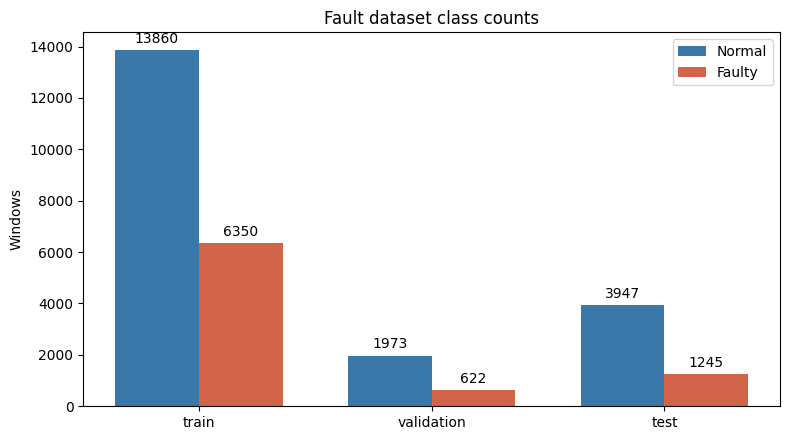

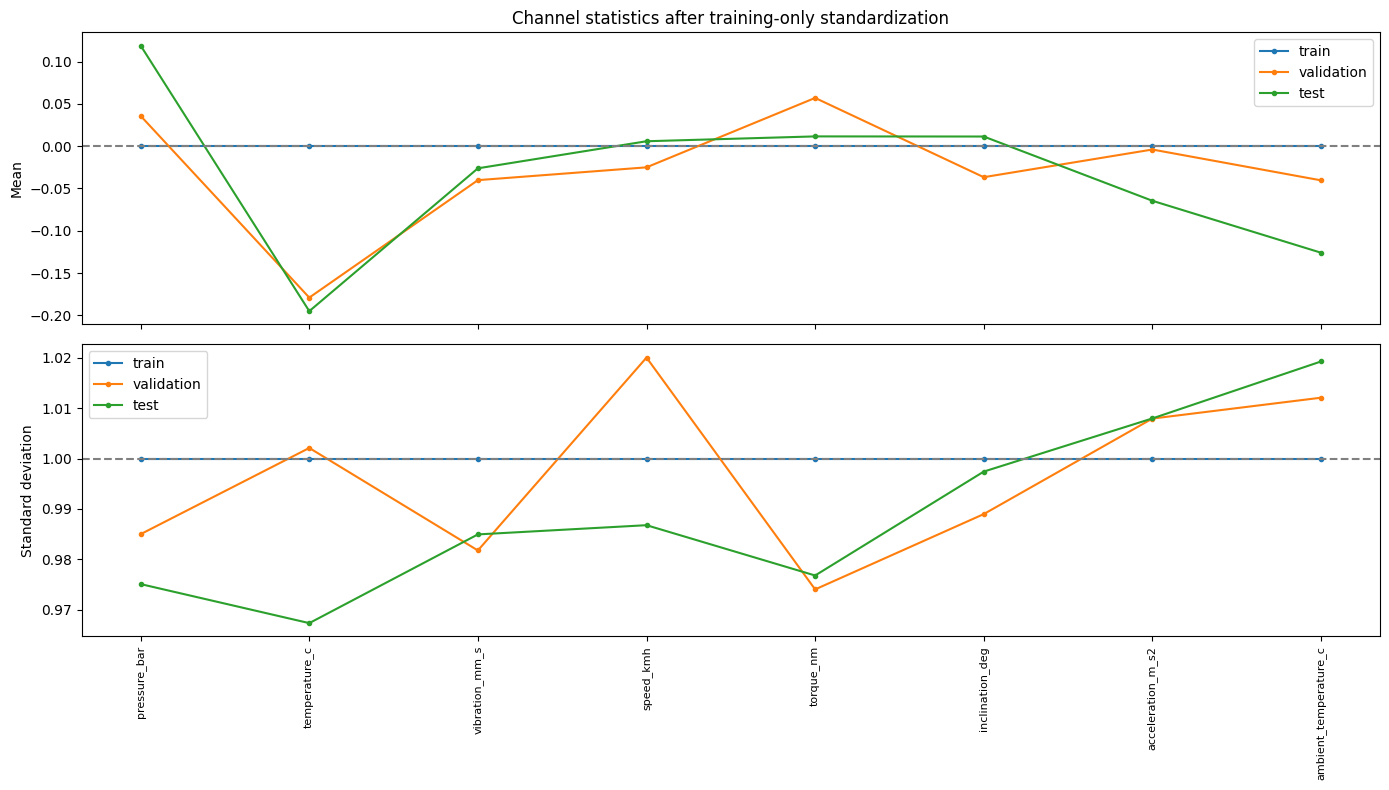

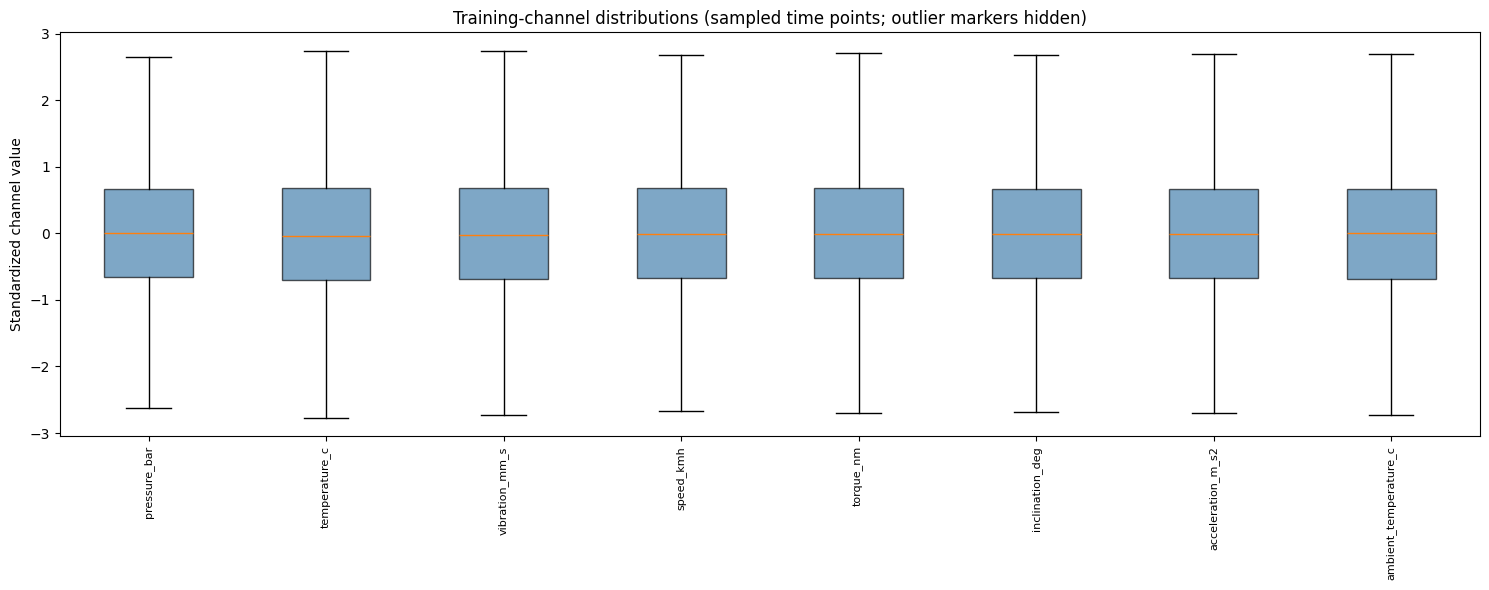

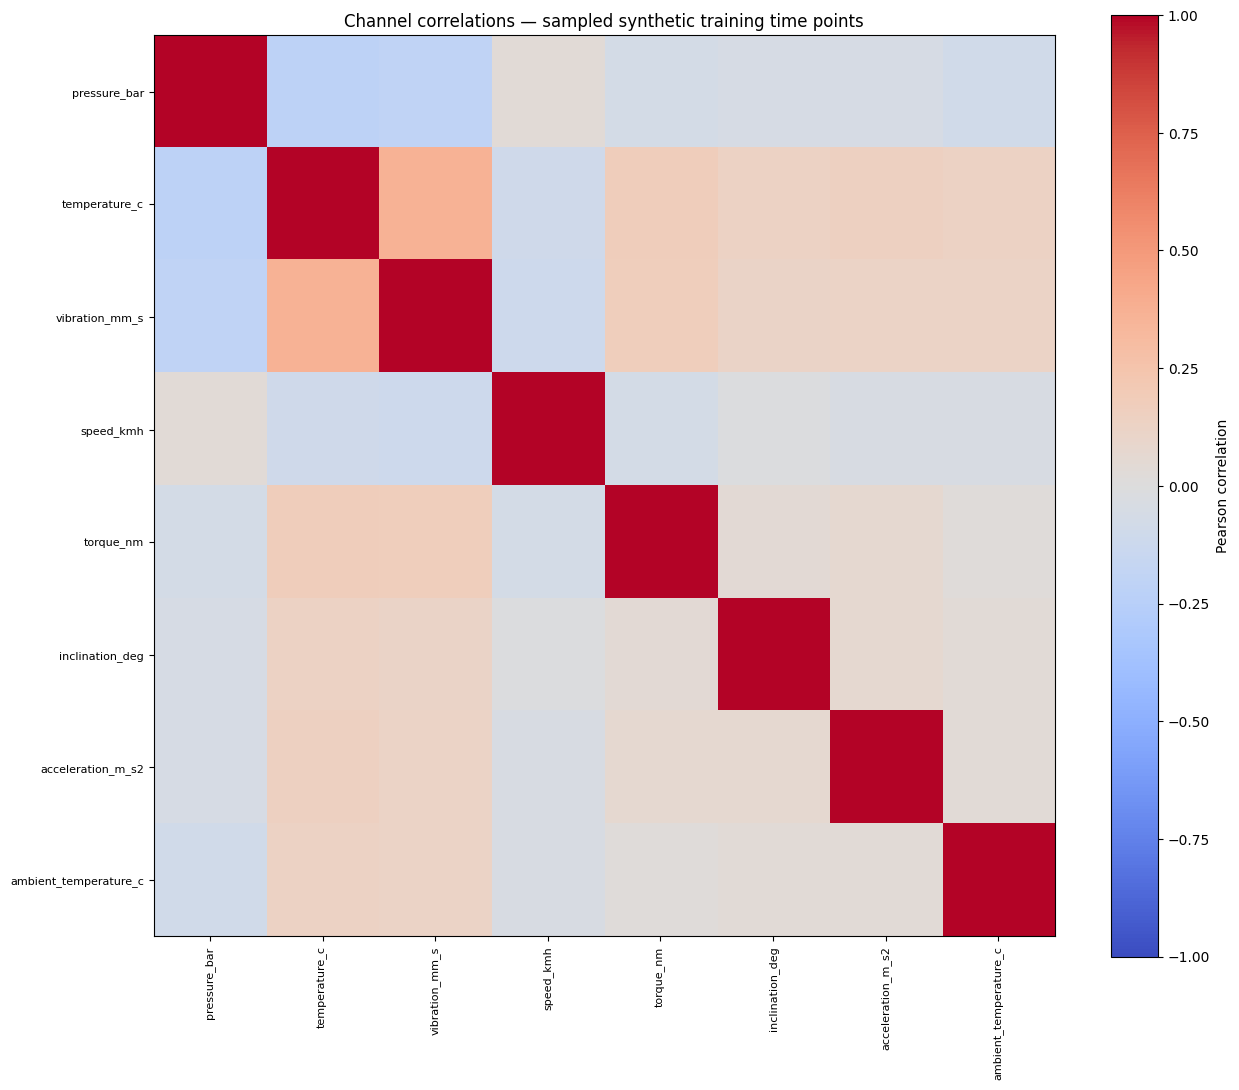

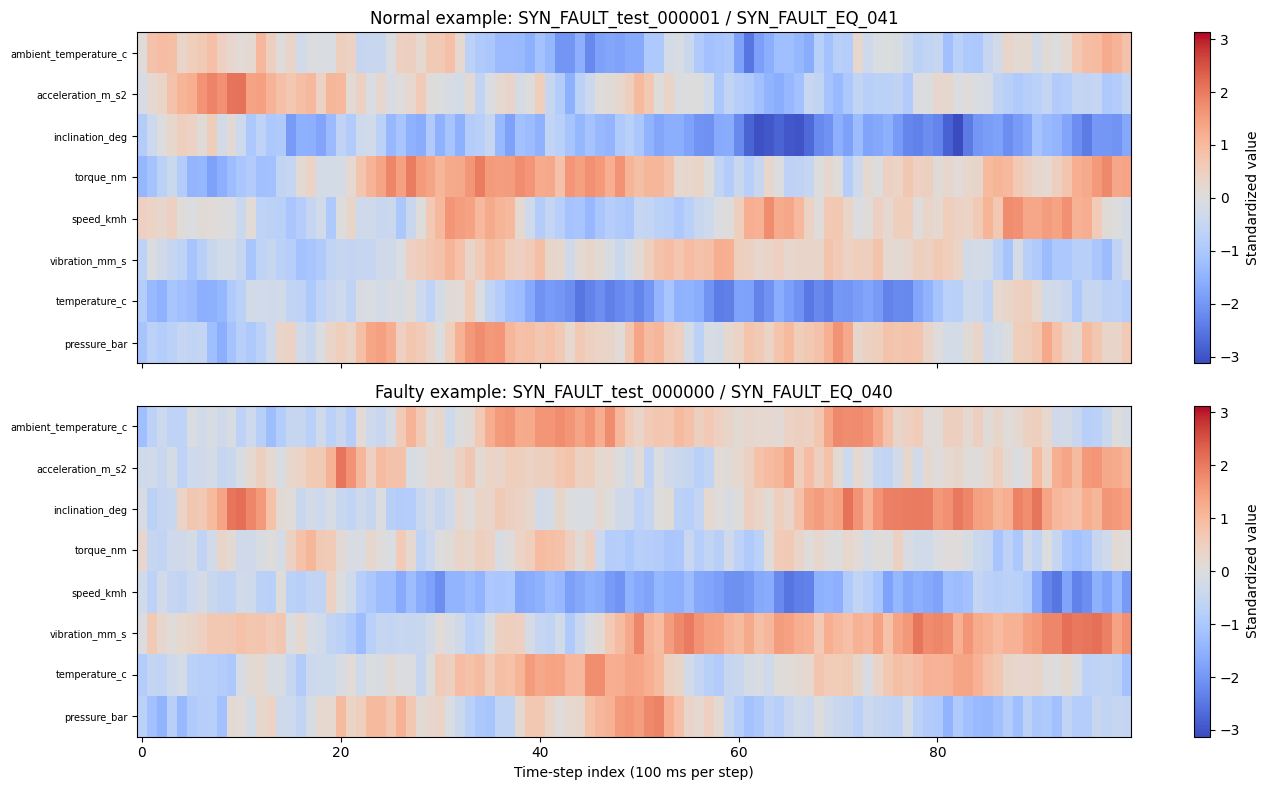

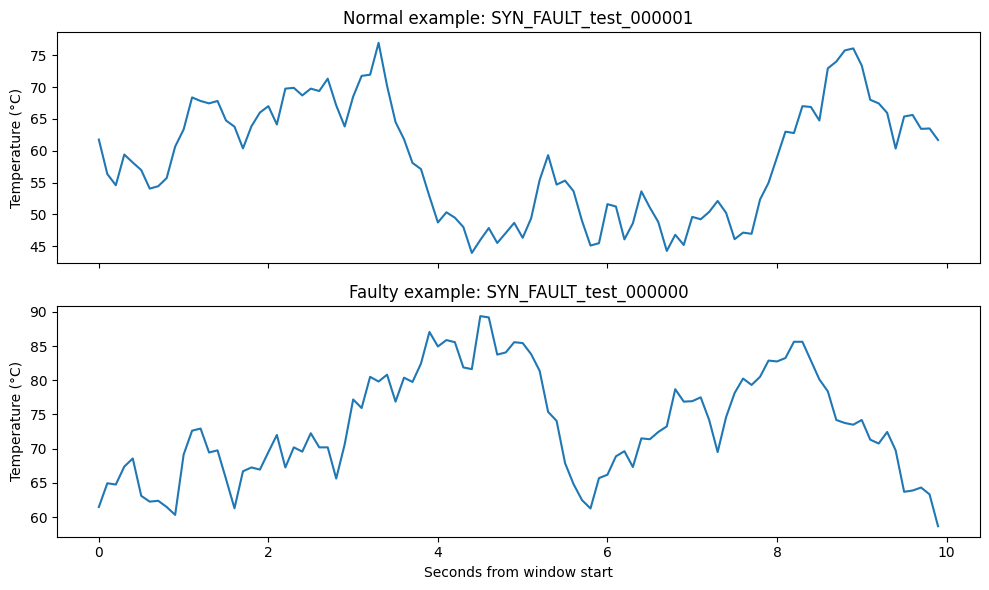


RECORDED PREPROCESSING REPORT:
{
  "data_origin": "synthetic demonstration only",
  "fit_subset": "all training windows only",
  "sampling_interval_seconds": 0.1,
  "smoothing": "disabled to preserve spikes",
  "duplicates": "exact labeled repeated sequences rejected, not silently deleted",
  "splits": {
    "train": {
      "shape": [
        20210,
        100,
        8
      ],
      "normal": 13860,
      "faulty": 6350,
      "equipment_count": 20,
      "nonfinite_values_imputed": 0
    },
    "validation": {
      "shape": [
        2595,
        100,
        8
      ],
      "normal": 1973,
      "faulty": 622,
      "equipment_count": 20,
      "nonfinite_values_imputed": 0
    },
    "test": {
      "shape": [
        5192,
        100,
        8
      ],
      "normal": 3947,
      "faulty": 1245,
      "equipment_count": 20,
      "nonfinite_values_imputed": 0
    }
  },
  "feature_names": [
    "pressure_bar",
    "temperature_c",
    "vibration_mm_s",
    "speed_kmh",
 

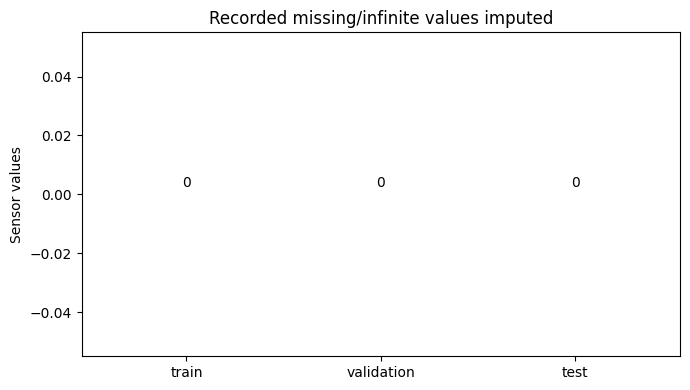


Completed. Results and figures saved to: /content/drive/MyDrive/Port Work/Fault_Preprocessed/Results_Visualization


In [ ]:
# Colab: inspect and visualize completed eight-channel fault preprocessing.
# No training or alteration of sensor data. Figures describe synthetic engineered data.
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from google.colab import drive

ROOT=Path('/content/drive/MyDrive/Port Work/Fault_Preprocessed')
OUT=ROOT/'Results_Visualization'
EXPECTED={'train':[13860,6350],'validation':[1973,622],'test':[3947,1245]}
BASE_NAMES=['pressure_bar','temperature_c','vibration_mm_s','speed_kmh','torque_nm','inclination_deg','acceleration_m_s2','ambient_temperature_c']
NAMES=BASE_NAMES.copy()
COLORS=['#3978a8']*8
if not Path('/content/drive/MyDrive').is_dir(): drive.mount('/content/drive',force_remount=False)
if not ROOT.is_dir(): raise FileNotFoundError('Run fault preprocessing first: '+str(ROOT))
OUT.mkdir(parents=True,exist_ok=True)
rows=[];stats=[];samples={};seen_ids=set();seen_eq=set();rng=np.random.default_rng(42)
for split,counts in EXPECTED.items():
    print('Inspecting:',split,flush=True)
    with np.load(ROOT/f'{split}_mamba.npz',allow_pickle=False) as a:
        x=a['X'].astype(np.float32);y=a['y'];names=a['feature_names'].astype(str).tolist()
        ids=a['window_id'].astype(str);eq=a['equipment_id'].astype(str)
    if names!=NAMES or x.shape!=(sum(counts),100,8): raise ValueError('Unexpected feature names or shape')
    if not np.isfinite(x).all() or not np.isin(y,[0,1]).all(): raise ValueError('Invalid values or labels')
    if np.bincount(y.astype(int),minlength=2).tolist()!=counts: raise ValueError('Unexpected class counts')
    if len(ids)!=len(y) or len(eq)!=len(y) or len(set(ids))!=len(ids): raise ValueError('Invalid identifiers')
    if seen_ids&set(ids) or seen_eq&set(eq): raise ValueError('Cross-split overlap')
    seen_ids.update(ids);seen_eq.update(eq)
    rows.append({'split':split,'windows':len(y),'normal':counts[0],'faulty':counts[1],
        'time_steps':100,'channels':8,'sensor_readings':len(y)*100,'equipment':len(set(eq)),
        'missing_values':int(np.isnan(x).sum()),'infinite_values':int(np.isinf(x).sum())})
    flat=x.reshape(-1,8)
    means=flat.mean(0,dtype=np.float64);std=flat.std(0,dtype=np.float64)
    for j,name in enumerate(names):
        stats.append({'split':split,'feature':name,'mean':means[j],'std':std[j],
            'minimum':float(flat[:,j].min()),'maximum':float(flat[:,j].max())})
    if split=='train':
        # Bounded sample of time points for descriptive plots, not model selection.
        idx=rng.choice(len(flat),min(20000,len(flat)),replace=False)
        sampled=flat[idx].copy()
    if split=='test':
        for label in [0,1]:
            i=int(np.flatnonzero(y==label)[0]);samples[label]=(x[i].copy(),str(ids[i]),str(eq[i]))
    del x,flat
summary=pd.DataFrame(rows);statistics=pd.DataFrame(stats)
summary.to_csv(OUT/'dataset_summary.csv',index=False)
statistics.to_csv(OUT/'feature_statistics.csv',index=False)
print('\nVERIFIED DATASET SUMMARY')
print(summary.to_string(index=False))
print('\nTotal windows:',summary.windows.sum())
try:
    from IPython.display import display
    display(summary)
except ImportError: pass

def save(fig,name):
    fig.tight_layout();fig.savefig(OUT/name,dpi=200,bbox_inches='tight');plt.show();plt.close(fig)

# 1. Class balance by split.
fig,ax=plt.subplots(figsize=(8,4.5));positions=np.arange(len(summary));width=.36
b1=ax.bar(positions-width/2,summary.normal,width,label='Normal',color='#3978a8')
b2=ax.bar(positions+width/2,summary.faulty,width,label='Faulty',color='#d26449')
ax.bar_label(b1,padding=3);ax.bar_label(b2,padding=3)
ax.set_xticks(positions,summary.split);ax.set(ylabel='Windows',title='Fault dataset class counts');ax.legend()
save(fig,'class_distribution.png')

# 3. Mean/std across splits for a scaling diagnostic. Not feature importance.
fig,axes=plt.subplots(2,1,figsize=(14,8),sharex=True)
for split in EXPECTED:
    table=statistics.loc[statistics.split.eq(split)].set_index('feature').loc[NAMES]
    axes[0].plot(np.arange(8),table['mean'],marker='o',ms=3,label=split)
    axes[1].plot(np.arange(8),table['std'],marker='o',ms=3,label=split)
axes[0].axhline(0,color='gray',ls='--');axes[1].axhline(1,color='gray',ls='--')
axes[0].set(ylabel='Mean',title='Channel statistics after training-only standardization')
axes[1].set(ylabel='Standard deviation');axes[0].legend();axes[1].legend()
axes[1].set_xticks(np.arange(8),NAMES,rotation=90,fontsize=8)
save(fig,'standardization_diagnostics.png')

# 4. Sampled training feature distributions.
fig,ax=plt.subplots(figsize=(15,6))
bp=ax.boxplot([sampled[:,j] for j in range(8)],showfliers=False,patch_artist=True)
for box,color in zip(bp['boxes'],COLORS): box.set_facecolor(color);box.set_alpha(.65)
ax.set_xticks(np.arange(1,9),NAMES,rotation=90,fontsize=8)
ax.set(ylabel='Standardized channel value',title='Training-channel distributions (sampled time points; outlier markers hidden)')
save(fig,'training_feature_distributions.png')

# 5. Correlation matrix on sampled training time points.
corr=pd.DataFrame(sampled,columns=NAMES).corr()
corr.to_csv(OUT/'sampled_training_correlations.csv')
fig,ax=plt.subplots(figsize=(13,11));im=ax.imshow(corr.to_numpy(),vmin=-1,vmax=1,cmap='coolwarm')
ax.set_xticks(np.arange(8),NAMES,rotation=90,fontsize=8)
ax.set_yticks(np.arange(8),NAMES,fontsize=8)
ax.set_title('Channel correlations — sampled synthetic training time points')
fig.colorbar(im,ax=ax,label='Pearson correlation');save(fig,'training_correlation_heatmap.png')

# 6. Example normal/faulty window heatmaps. These are examples, not model detections.
fig,axes=plt.subplots(2,1,figsize=(14,8),sharex=True)
limit=max(float(np.max(np.abs(v[0]))) for v in samples.values())
for label,ax in enumerate(axes):
    values,window,equipment=samples[label]
    im=ax.imshow(values.T,aspect='auto',origin='lower',cmap='coolwarm',vmin=-limit,vmax=limit)
    ax.set_yticks(np.arange(8),NAMES,fontsize=7)
    ax.set_title(f"{'Normal' if label==0 else 'Faulty'} example: {window} / {equipment}")
    fig.colorbar(im,ax=ax,label='Standardized value')
axes[-1].set_xlabel('Time-step index (100 ms per step)')
save(fig,'example_window_heatmaps.png')

# 7. Example temperature curves in original units, recovered using saved scaler.
with np.load(ROOT/'preprocessing_parameters.npz',allow_pickle=False) as a:
    means=a['mean'];scales=a['scale']
    if a['feature_names'].astype(str).tolist()!=NAMES: raise ValueError('Scaler channel order mismatch')
fig,axes=plt.subplots(2,1,figsize=(10,6),sharex=True)
for label,ax in enumerate(axes):
    values,window,equipment=samples[label]
    temperature=values[:,1]*scales[1]+means[1]
    ax.plot(np.arange(100)*.1,temperature)
    ax.set(ylabel='Temperature (°C)',title=f"{'Normal' if label==0 else 'Faulty'} example: {window}")
axes[-1].set_xlabel('Seconds from window start')
save(fig,'example_temperature_original_units.png')
# Display the recorded preprocessing report, without inventing cleaning statistics.
report_path=ROOT/'preprocessing_report.json'
if report_path.is_file():
    report=json.loads(report_path.read_text())
    print('\nRECORDED PREPROCESSING REPORT:')
    print(json.dumps(report,indent=2))
    (OUT/'source_preprocessing_report.json').write_text(json.dumps(report,indent=2))
    records=[]
    for split,entry in report.get('splits',{}).items():
        records.append({'split':split,'nonfinite_values_imputed':entry.get('nonfinite_values_imputed',None)})
    table=pd.DataFrame(records)
    table.to_csv(OUT/'recorded_imputation_counts.csv',index=False)
    if not table.empty and table.nonfinite_values_imputed.notna().all():
        fig,ax=plt.subplots(figsize=(7,4));bars=ax.bar(table.split,table.nonfinite_values_imputed,color='#3978a8')
        ax.bar_label(bars,padding=3);ax.set(ylabel='Sensor values',title='Recorded missing/infinite values imputed')
        save(fig,'recorded_imputation_counts.png')
(OUT/'visualization_notes.json').write_text(json.dumps({'data_origin':'synthetic','stage':'fault preprocessing only',
    'channels':NAMES,'preprocessing_fit':'all training windows only',
    'sampled_training_time_points':min(20000,20210*100),'seed':42,
    'distribution_units':'standardized except explicitly recovered temperature',
    'interpretation':'no classifier training, prediction accuracy, feature importance or ROC claimed',
    'cleaning_statistics':'taken only from existing preprocessing report',
    'temporal_dependence':'correlations are descriptive; sampled time points are not independent evidence'},indent=2))
print('\nCompleted. Results and figures saved to:',OUT,flush=True)


In [ ]:
# Colab: expand the existing 8 measured/simulated channels to 21 causal engineered channels.
# No new sensor measurements or labels are invented. This is not the paper's 21-variable dataset.
from pathlib import Path
import json
import numpy as np
import pandas as pd

INPUT = Path('/content/drive/MyDrive/Port Work/Fault_Preprocessed')
OUTPUT = Path('/content/drive/MyDrive/Port Work/Fault_21_Engineered_Preprocessed')
EXPECTED = {'train':[13860,6350],'validation':[1973,622],'test':[3947,1245]}
SENSORS = ['pressure_bar','temperature_c','vibration_mm_s','speed_kmh','torque_nm','inclination_deg','acceleration_m_s2','ambient_temperature_c']
ROLLING_SENSORS = SENSORS[:5]
ROLLING_STEPS = 5
NAMES = SENSORS + [name+'_step_change' for name in SENSORS] + [name+'_trailing_mean_5' for name in ROLLING_SENSORS]

def engineer(x):
    if x.ndim!=3 or x.shape[-1]!=8: raise ValueError('Expected (windows,time,8)')
    difference = np.zeros_like(x)
    difference[:,1:,:] = x[:,1:,:]-x[:,:-1,:]
    # Trailing means use only current and previous readings, separately within each window.
    values=x[:,:,:5].astype(np.float64)
    cumulative=np.concatenate([np.zeros((len(x),1,5)),np.cumsum(values,axis=1)],axis=1)
    end=np.arange(1,x.shape[1]+1)
    start=np.maximum(0,end-ROLLING_STEPS)
    rolling=(cumulative[:,end,:]-cumulative[:,start,:])/(end-start)[None,:,None]
    result=np.concatenate([x,difference,rolling.astype(np.float32)],axis=-1)
    if not np.isfinite(result).all(): raise ValueError('Nonfinite engineered features')
    return result.astype(np.float32)

def main():
    from google.colab import drive
    if not Path('/content/drive/MyDrive').is_dir(): drive.mount('/content/drive',force_remount=False)
    OUTPUT.mkdir(parents=True,exist_ok=True)
    assert len(NAMES)==len(set(NAMES))==21
    data={};seen_ids=set();seen_equipment=set()
    for split,counts in EXPECTED.items():
        path=INPUT/f'{split}_mamba.npz'
        if not path.is_file(): raise FileNotFoundError(path)
        print('Loading and engineering:',split,flush=True)
        with np.load(path,allow_pickle=False) as stored:
            payload={key:stored[key].copy() for key in stored.files}
        if payload['feature_names'].astype(str).tolist()!=SENSORS:
            raise ValueError('Unexpected source sensor names/order. Do not rename channels to bypass this check.')
        x=payload['X'].astype(np.float32);raw_y=payload['y']
        if not np.isin(raw_y,[0,1]).all(): raise ValueError('Invalid labels')
        y=raw_y.astype(np.int64)
        if np.bincount(y,minlength=2).tolist()!=counts or x.shape!=(sum(counts),100,8):
            raise ValueError('Source shapes/counts differ from expected fault data')
        if not np.isfinite(x).all(): raise ValueError('Source contains missing/infinite values; run preprocessing first')
        ids=payload['window_id'].astype(str);eq=payload['equipment_id'].astype(str)
        if len(ids)!=len(y) or len(eq)!=len(y) or len(set(ids))!=len(ids): raise ValueError('Invalid IDs')
        if seen_ids&set(ids) or seen_equipment&set(eq): raise ValueError('Split leakage')
        seen_ids.update(ids);seen_equipment.update(eq)
        data[split]=(engineer(x),payload)
    # Fit new channel scaling on all training observations only.
    training=data['train'][0].reshape(-1,21)
    mean=training.mean(axis=0,dtype=np.float64)
    scale=training.std(axis=0,dtype=np.float64);scale[scale<1e-12]=1.
    np.savez(OUTPUT/'engineered_channel_scaler.npz',mean=mean,scale=scale,feature_names=np.array(NAMES))
    rows=[]
    for split,(x,payload) in data.items():
        x=((x-mean)/scale).astype(np.float32)
        if not np.isfinite(x).all(): raise ValueError('Invalid scaled output')
        payload['X']=x;payload['feature_names']=np.array(NAMES)
        np.savez_compressed(OUTPUT/f'{split}_mamba.npz',**payload)
        manifest=INPUT/f'{split}_manifest.csv'
        if not manifest.is_file(): raise FileNotFoundError('Missing timestamp manifest: '+str(manifest))
        df=pd.read_csv(manifest,dtype={'window_id':str,'equipment_id':str})
        if df.window_id.duplicated().any() or set(df.window_id)!=set(payload['window_id'].astype(str)): raise ValueError('Manifest mismatch')
        df=df.set_index('window_id').loc[payload['window_id'].astype(str)].reset_index()
        if not np.array_equal(df.equipment_id.to_numpy(),payload['equipment_id'].astype(str)): raise ValueError('Manifest equipment mismatch')
        if not np.array_equal(df.label.to_numpy(),payload['y']): raise ValueError('Manifest label mismatch')
        df.to_csv(OUTPUT/f'{split}_manifest.csv',index=False)
        rows.append({'split':split,'windows':len(x),'time_steps':100,'channels':21})
        print('Saved:',split,x.shape,flush=True)
    pd.DataFrame({'channel_index':np.arange(21),'feature_name':NAMES,
        'kind':['original standardized sensor']*8+['step difference']*8+['trailing mean']*5}).to_csv(OUTPUT/'feature_dictionary.csv',index=False)
    (OUTPUT/'engineering_report.json').write_text(json.dumps({'data_origin':'synthetic source dataset','method':'8 original + 8 step changes + 5 trailing means','difference_first_step':0,'trailing_window_steps':5,'boundary_policy':'reset each window; partial trailing means at window start','fit_statistics':'training split only','source_was_standardized':True,'paper_21_variables_recreated':False,'splits':rows},indent=2))
    print('Ready for Mamba. Input dimension = 21. Output:',OUTPUT,flush=True)
    print('These are engineered channels, not the paper-specific inverter/motor measurements.')

if __name__=='__main__': main()


Loading and engineering: train
Loading and engineering: validation
Loading and engineering: test
Saved: train (20210, 100, 21)
Saved: validation (2595, 100, 21)
Saved: test (5192, 100, 21)
Ready for Mamba. Input dimension = 21. Output: /content/drive/MyDrive/Port Work/Fault_21_Engineered_Preprocessed
These are engineered channels, not the paper-specific inverter/motor measurements.


Inspecting: train
Inspecting: validation
Inspecting: test

VERIFIED DATASET SUMMARY
     split  windows  normal  faulty  time_steps  channels  sensor_readings  equipment  missing_values  infinite_values
     train    20210   13860    6350         100        21          2021000         20               0                0
validation     2595    1973     622         100        21           259500         20               0                0
      test     5192    3947    1245         100        21           519200         20               0                0

Total windows: 27997


,split,windows,normal,faulty,time_steps,channels,sensor_readings,equipment,missing_values,infinite_values
0,train,20210,13860,6350,100,21,2021000,20,0,0
1,validation,2595,1973,622,100,21,259500,20,0,0
2,test,5192,3947,1245,100,21,519200,20,0,0


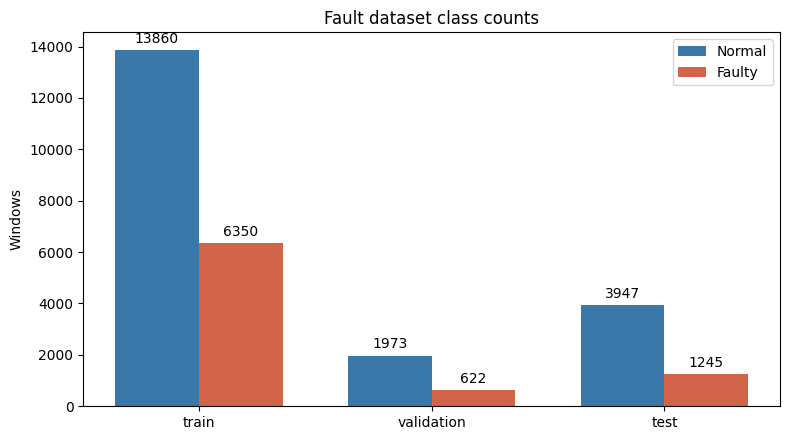

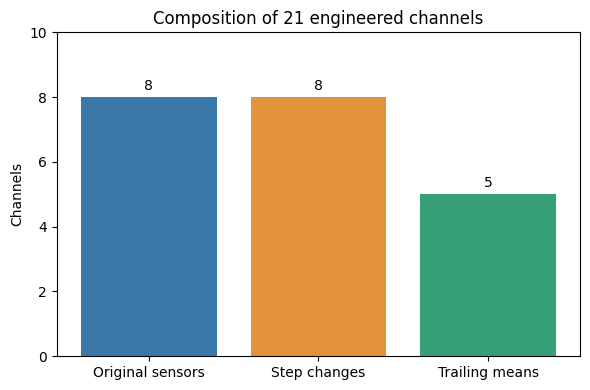

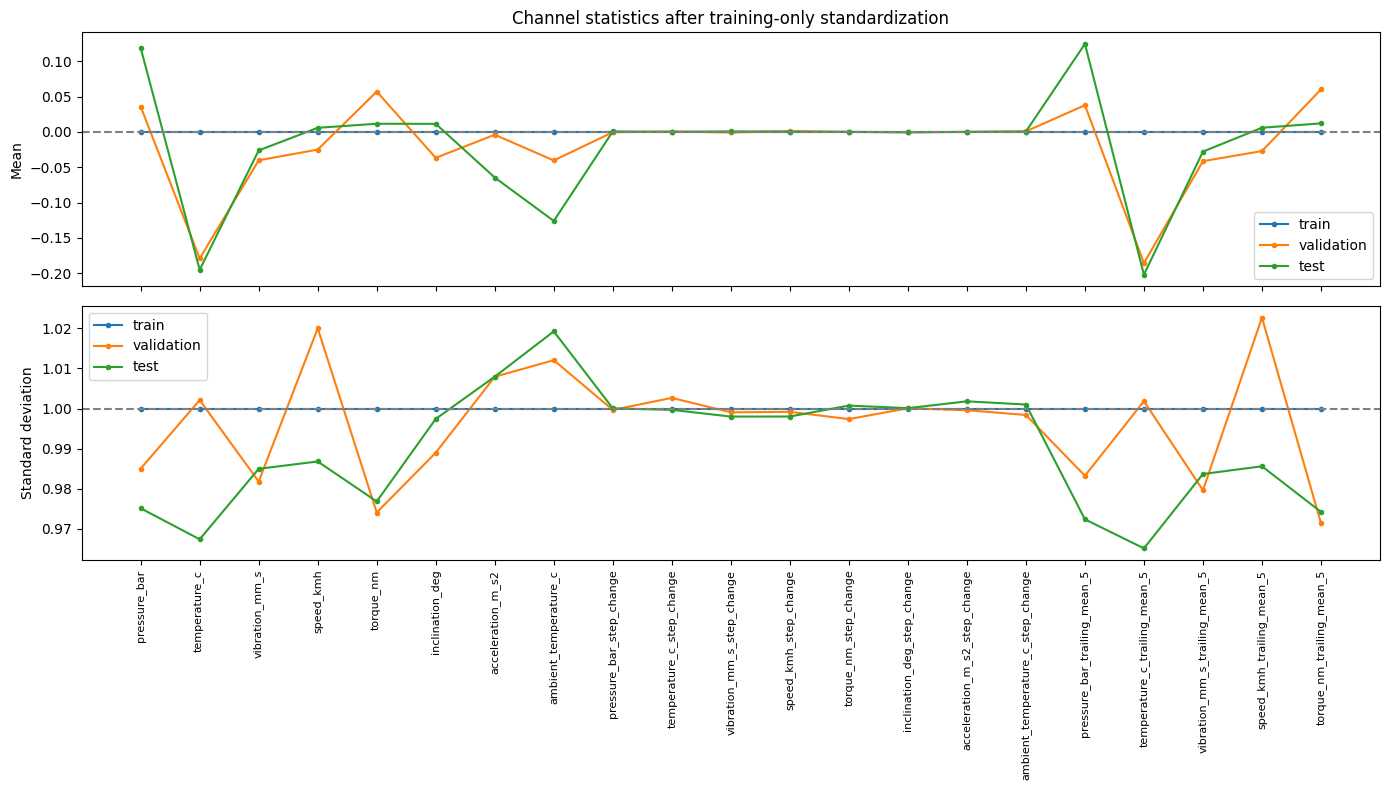

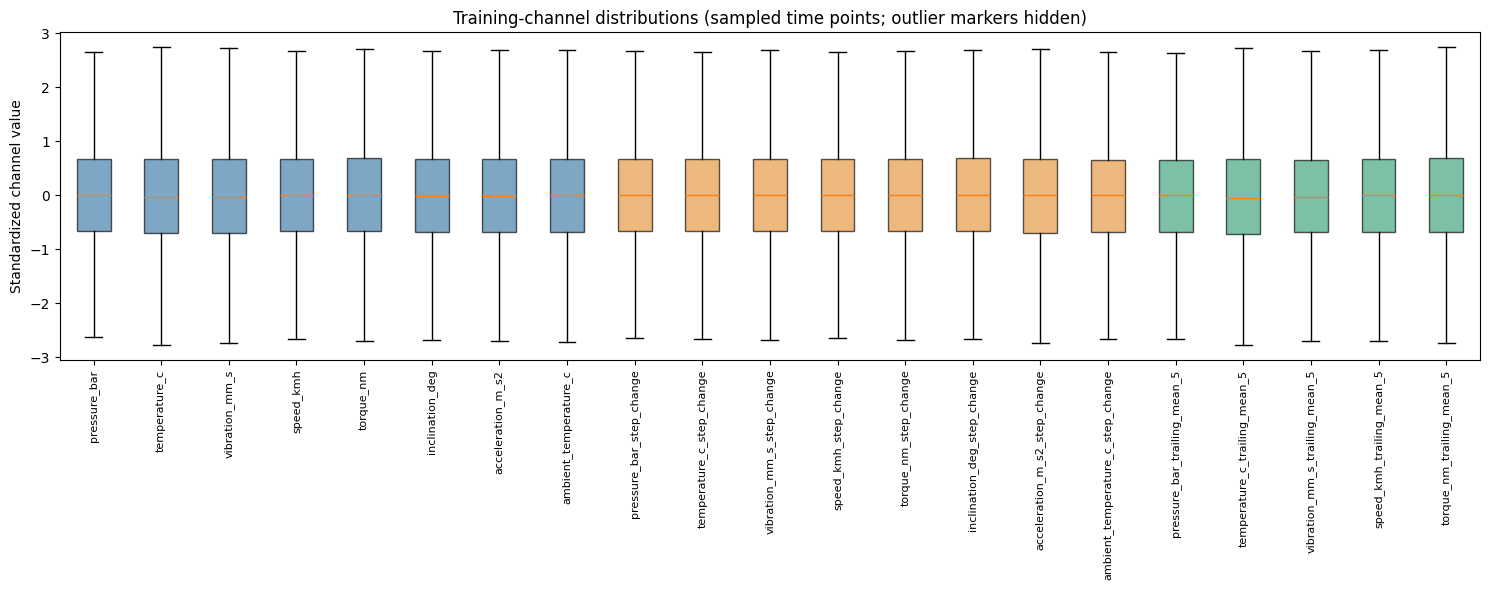

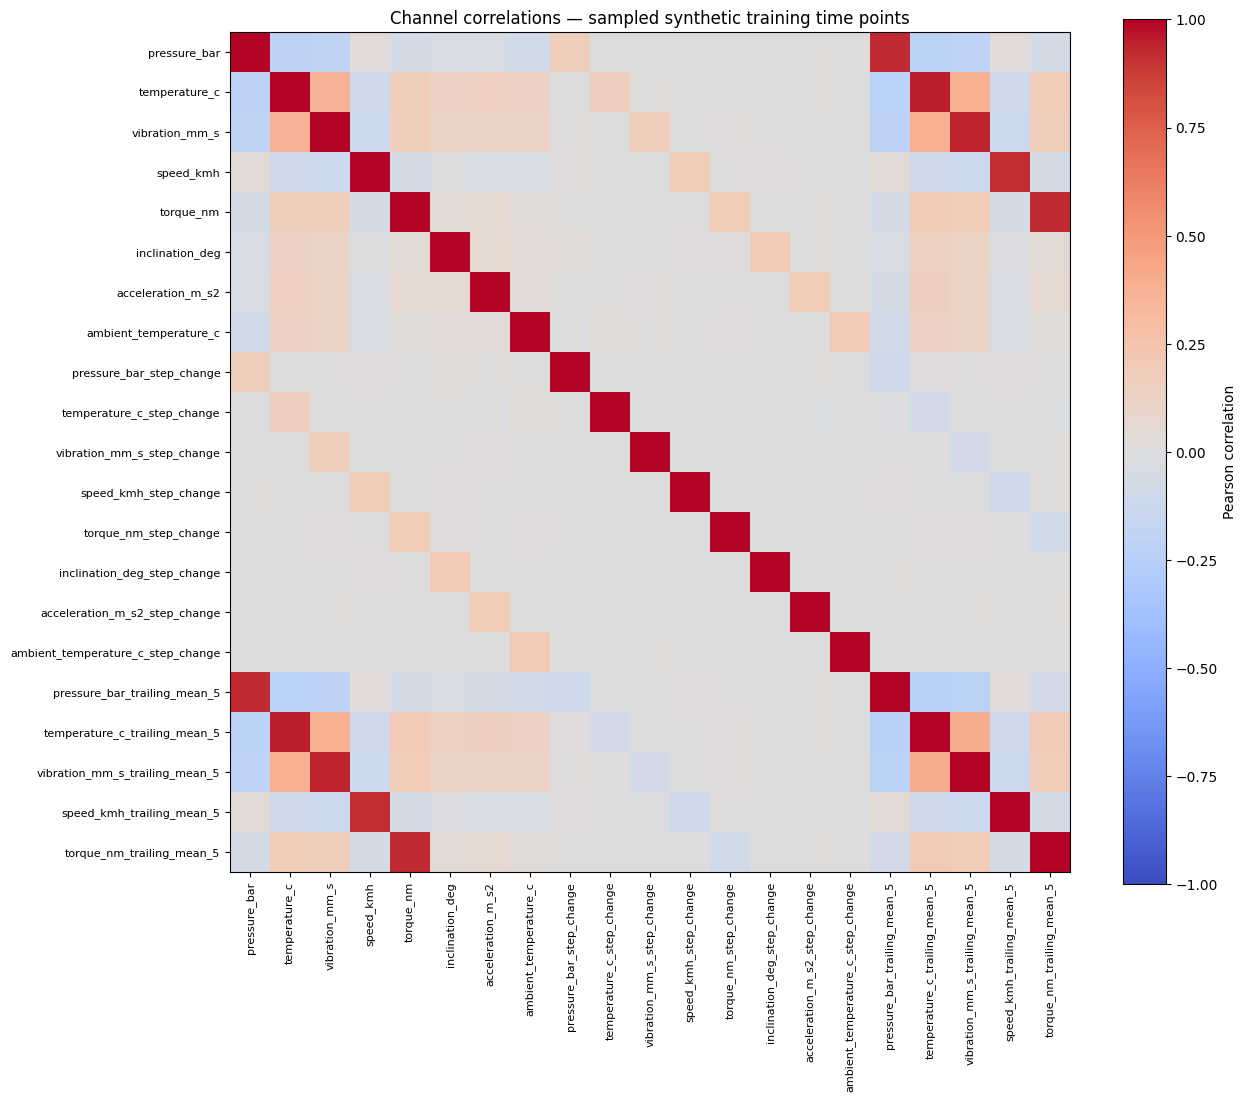

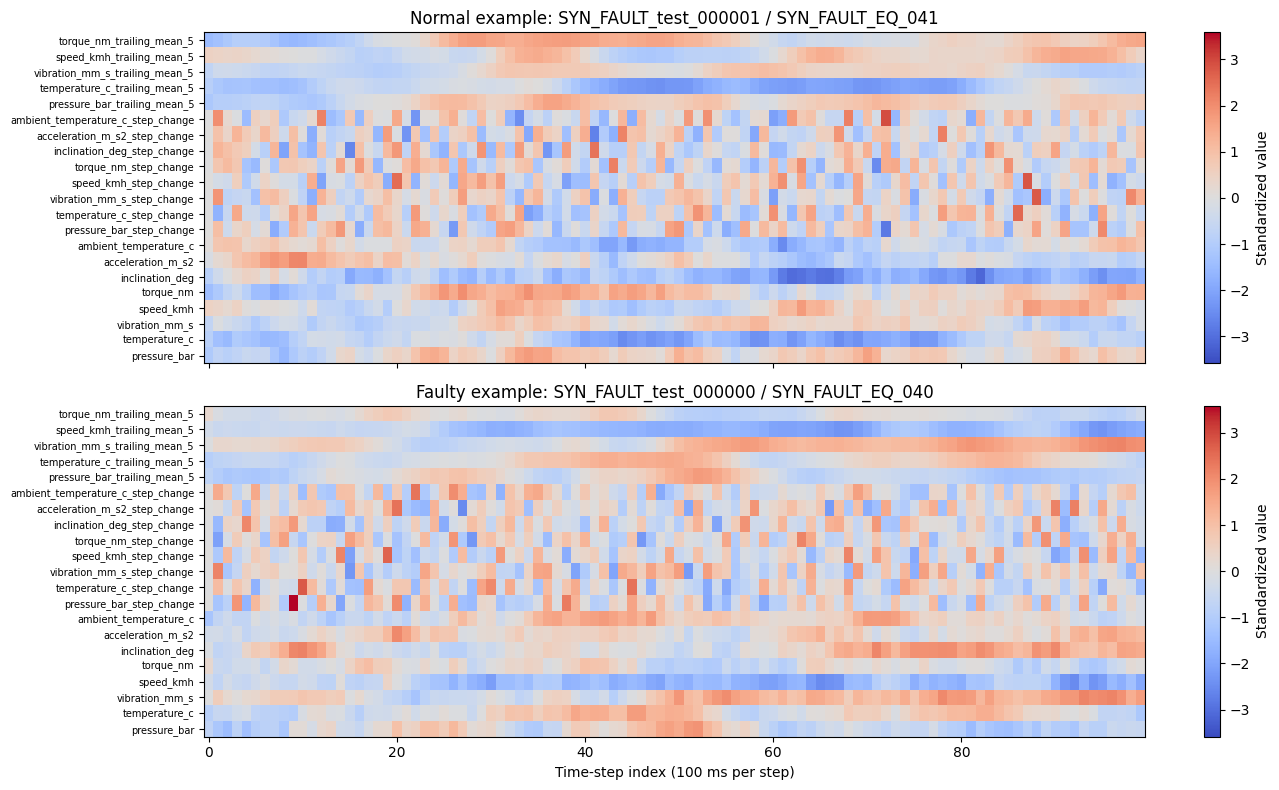

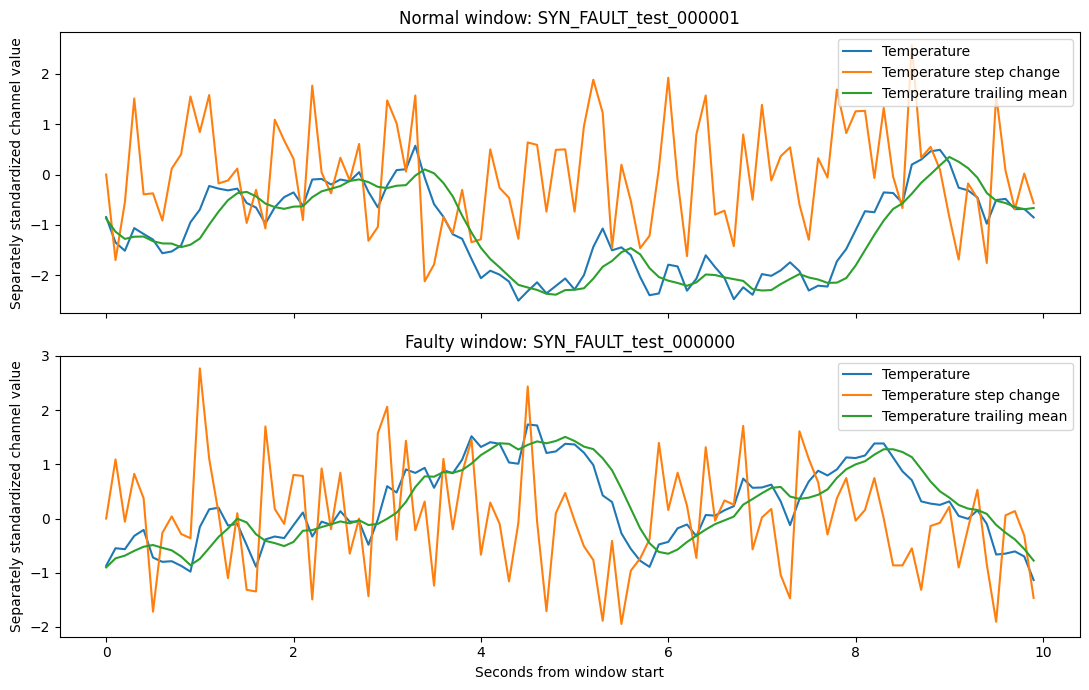


Completed. Tables and figures saved to: /content/drive/MyDrive/Port Work/Fault_21_Engineered_Preprocessed/Results_Visualization
No accuracy, confusion matrix or ROC is calculated: this step engineers features, not predictions.


In [ ]:
# Colab: inspect and visualize completed 8 -> 21 engineered fault channels.
# No training or alteration of sensor data. Figures describe synthetic engineered data.
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from google.colab import drive

ROOT=Path('/content/drive/MyDrive/Port Work/Fault_21_Engineered_Preprocessed')
OUT=ROOT/'Results_Visualization'
EXPECTED={'train':[13860,6350],'validation':[1973,622],'test':[3947,1245]}
BASE_NAMES=['pressure_bar','temperature_c','vibration_mm_s','speed_kmh','torque_nm','inclination_deg','acceleration_m_s2','ambient_temperature_c']
NAMES=BASE_NAMES+[s+'_step_change' for s in BASE_NAMES]+[s+'_trailing_mean_5' for s in BASE_NAMES[:5]]
COLORS=['#3978a8']*8+['#e29339']*8+['#369f77']*5
if not Path('/content/drive/MyDrive').is_dir(): drive.mount('/content/drive',force_remount=False)
if not ROOT.is_dir(): raise FileNotFoundError('Run channel engineering first: '+str(ROOT))
OUT.mkdir(parents=True,exist_ok=True)
rows=[];stats=[];samples={};seen_ids=set();seen_eq=set();rng=np.random.default_rng(42)
for split,counts in EXPECTED.items():
    print('Inspecting:',split,flush=True)
    with np.load(ROOT/f'{split}_mamba.npz',allow_pickle=False) as a:
        x=a['X'].astype(np.float32);y=a['y'];names=a['feature_names'].astype(str).tolist()
        ids=a['window_id'].astype(str);eq=a['equipment_id'].astype(str)
    if names!=NAMES or x.shape!=(sum(counts),100,21): raise ValueError('Unexpected feature names or shape')
    if not np.isfinite(x).all() or not np.isin(y,[0,1]).all(): raise ValueError('Invalid values or labels')
    if np.bincount(y.astype(int),minlength=2).tolist()!=counts: raise ValueError('Unexpected class counts')
    if len(ids)!=len(y) or len(eq)!=len(y) or len(set(ids))!=len(ids): raise ValueError('Invalid identifiers')
    if seen_ids&set(ids) or seen_eq&set(eq): raise ValueError('Cross-split overlap')
    seen_ids.update(ids);seen_eq.update(eq)
    rows.append({'split':split,'windows':len(y),'normal':counts[0],'faulty':counts[1],
        'time_steps':100,'channels':21,'sensor_readings':len(y)*100,'equipment':len(set(eq)),
        'missing_values':int(np.isnan(x).sum()),'infinite_values':int(np.isinf(x).sum())})
    flat=x.reshape(-1,21)
    means=flat.mean(0,dtype=np.float64);std=flat.std(0,dtype=np.float64)
    for j,name in enumerate(names):
        stats.append({'split':split,'feature':name,'mean':means[j],'std':std[j],
            'minimum':float(flat[:,j].min()),'maximum':float(flat[:,j].max())})
    if split=='train':
        # Bounded sample of time points for descriptive plots, not model selection.
        idx=rng.choice(len(flat),min(20000,len(flat)),replace=False)
        sampled=flat[idx].copy()
    if split=='test':
        for label in [0,1]:
            i=int(np.flatnonzero(y==label)[0]);samples[label]=(x[i].copy(),str(ids[i]),str(eq[i]))
    del x,flat
summary=pd.DataFrame(rows);statistics=pd.DataFrame(stats)
summary.to_csv(OUT/'dataset_summary.csv',index=False)
statistics.to_csv(OUT/'feature_statistics.csv',index=False)
print('\nVERIFIED DATASET SUMMARY')
print(summary.to_string(index=False))
print('\nTotal windows:',summary.windows.sum())
try:
    from IPython.display import display
    display(summary)
except ImportError: pass

def save(fig,name):
    fig.tight_layout();fig.savefig(OUT/name,dpi=200,bbox_inches='tight');plt.show();plt.close(fig)

# 1. Class balance by split.
fig,ax=plt.subplots(figsize=(8,4.5));positions=np.arange(len(summary));width=.36
b1=ax.bar(positions-width/2,summary.normal,width,label='Normal',color='#3978a8')
b2=ax.bar(positions+width/2,summary.faulty,width,label='Faulty',color='#d26449')
ax.bar_label(b1,padding=3);ax.bar_label(b2,padding=3)
ax.set_xticks(positions,summary.split);ax.set(ylabel='Windows',title='Fault dataset class counts');ax.legend()
save(fig,'class_distribution.png')

# 2. Channel composition.
fig,ax=plt.subplots(figsize=(6,4));bars=ax.bar(['Original sensors','Step changes','Trailing means'],[8,8,5],color=['#3978a8','#e29339','#369f77'])
ax.bar_label(bars,padding=3);ax.set(ylabel='Channels',title='Composition of 21 engineered channels',ylim=(0,10))
save(fig,'channel_composition.png')

# 3. Mean/std across splits for a scaling diagnostic. Not feature importance.
fig,axes=plt.subplots(2,1,figsize=(14,8),sharex=True)
for split in EXPECTED:
    table=statistics.loc[statistics.split.eq(split)].set_index('feature').loc[NAMES]
    axes[0].plot(np.arange(21),table['mean'],marker='o',ms=3,label=split)
    axes[1].plot(np.arange(21),table['std'],marker='o',ms=3,label=split)
axes[0].axhline(0,color='gray',ls='--');axes[1].axhline(1,color='gray',ls='--')
axes[0].set(ylabel='Mean',title='Channel statistics after training-only standardization')
axes[1].set(ylabel='Standard deviation');axes[0].legend();axes[1].legend()
axes[1].set_xticks(np.arange(21),NAMES,rotation=90,fontsize=8)
save(fig,'standardization_diagnostics.png')

# 4. Sampled training feature distributions.
fig,ax=plt.subplots(figsize=(15,6))
bp=ax.boxplot([sampled[:,j] for j in range(21)],showfliers=False,patch_artist=True)
for box,color in zip(bp['boxes'],COLORS): box.set_facecolor(color);box.set_alpha(.65)
ax.set_xticks(np.arange(1,22),NAMES,rotation=90,fontsize=8)
ax.set(ylabel='Standardized channel value',title='Training-channel distributions (sampled time points; outlier markers hidden)')
save(fig,'training_feature_distributions.png')

# 5. Correlation matrix on sampled training time points.
corr=pd.DataFrame(sampled,columns=NAMES).corr()
corr.to_csv(OUT/'sampled_training_correlations.csv')
fig,ax=plt.subplots(figsize=(13,11));im=ax.imshow(corr.to_numpy(),vmin=-1,vmax=1,cmap='coolwarm')
ax.set_xticks(np.arange(21),NAMES,rotation=90,fontsize=8)
ax.set_yticks(np.arange(21),NAMES,fontsize=8)
ax.set_title('Channel correlations — sampled synthetic training time points')
fig.colorbar(im,ax=ax,label='Pearson correlation');save(fig,'training_correlation_heatmap.png')

# 6. Example normal/faulty window heatmaps. These are examples, not model detections.
fig,axes=plt.subplots(2,1,figsize=(14,8),sharex=True)
limit=max(float(np.max(np.abs(v[0]))) for v in samples.values())
for label,ax in enumerate(axes):
    values,window,equipment=samples[label]
    im=ax.imshow(values.T,aspect='auto',origin='lower',cmap='coolwarm',vmin=-limit,vmax=limit)
    ax.set_yticks(np.arange(21),NAMES,fontsize=7)
    ax.set_title(f"{'Normal' if label==0 else 'Faulty'} example: {window} / {equipment}")
    fig.colorbar(im,ax=ax,label='Standardized value')
axes[-1].set_xlabel('Time-step index (100 ms per step)')
save(fig,'example_window_heatmaps.png')

# 7. Original channel, step change, trailing mean: one shared sensor example.
fig,axes=plt.subplots(2,1,figsize=(11,7),sharex=True)
for label,ax in enumerate(axes):
    values,window,equipment=samples[label]
    for j,name in [(1,'Temperature'),(9,'Temperature step change'),(17,'Temperature trailing mean')]:
        ax.plot(np.arange(100)*.1,values[:,j],label=name)
    ax.set(ylabel='Separately standardized channel value',title=f"{'Normal' if label==0 else 'Faulty'} window: {window}");ax.legend()
axes[-1].set_xlabel('Seconds from window start')
save(fig,'temperature_engineering_examples.png')
(OUT/'visualization_notes.json').write_text(json.dumps({'data_origin':'synthetic','stage':'feature engineering, not model evaluation',
    'channels':'8 original + 8 step changes + 5 causal trailing means',
    'correlation_and_boxplot_sample':'up to 20000 training time points; seed 42',
    'units':'standardized values; not physical units',
    'interpretation':'descriptive plots do not measure feature importance or prediction accuracy',
    'time_points':'dependent within windows; correlations are descriptive, not independent-sample significance tests'},indent=2))
print('\nCompleted. Tables and figures saved to:',OUT,flush=True)
print('No accuracy, confusion matrix or ROC is calculated: this step engineers features, not predictions.')


In [ ]:
#Helps to do faster extraction
EPOCHS = 5
BATCH_SIZE = 32
D_MODEL = 32
D_STATE = 8
N_BLOCKS = 1
EMBEDDING_DIM = 128
PATIENCE = 2

# Separate folder for this smaller model.
OUT = BASE / "Fault_Mamba_XGBoost_21_Engineered_Fast"

Starting fault feature extraction...
[0.0s] GPU: Tesla T4
[0.0s] Loading train
[2.4s] train (20210, 100, 21) normal/faulty [13860, 6350]
[2.4s] Loading validation
[2.7s] validation (2595, 100, 21) normal/faulty [1973, 622]
[2.7s] Loading test
[3.4s] test (5192, 100, 21) normal/faulty [3947, 1245]
[3.4s] Creating reference Mamba model
[3.4s] Mamba epoch 1/20: train
[4.2s] train batch 1/1264 BCE=0.681907
[20.0s] Running: Mamba epoch 1/20: train
[22.8s] train batch 50/1264 BCE=0.459009
[39.7s] train batch 100/1264 BCE=0.440606
[40.0s] Running: Mamba epoch 1/20: train
[56.7s] train batch 150/1264 BCE=0.438767
[60.0s] Running: Mamba epoch 1/20: train
[73.6s] train batch 200/1264 BCE=0.434754
[80.0s] Running: Mamba epoch 1/20: train
[90.8s] train batch 250/1264 BCE=0.430870
[100.0s] Running: Mamba epoch 1/20: train
[107.9s] train batch 300/1264 BCE=0.428742
[120.0s] Running: Mamba epoch 1/20: train
[126.8s] train batch 350/1264 BCE=0.426738
[140.0s] Running: Mamba epoch 1/20: train
[143.7s] 

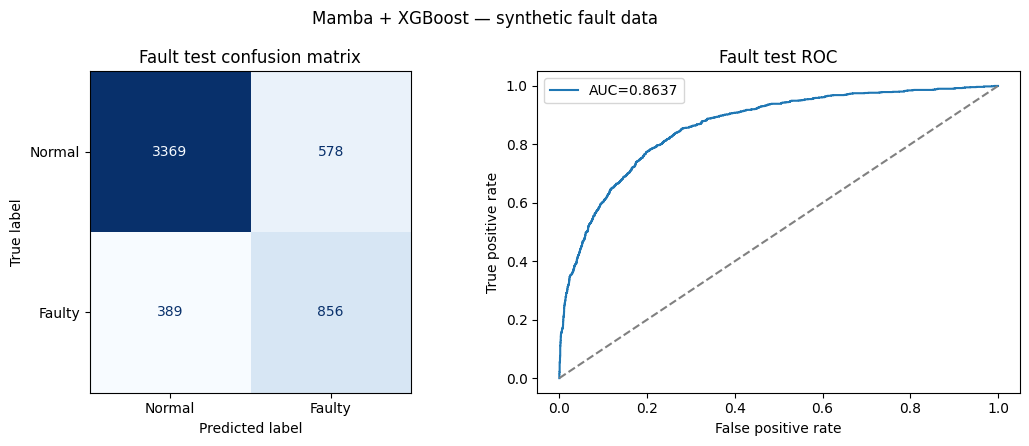

[5509.5s] TEST metrics: {
  "accuracy": 0.8137519260400616,
  "precision": 0.596931659693166,
  "recall": 0.6875502008032128,
  "f1": 0.6390444195595372,
  "roc_auc": 0.8636895695271586,
  "average_precision": 0.697002606938648,
  "brier_score": 0.11848133436944541,
  "confusion_matrix": [
    [
      3369,
      578
    ],
    [
      389,
      856
    ]
  ]
}
[5509.5s] Completed: /content/drive/MyDrive/Port Work/Fault_Mamba_XGBoost_21_Engineered
[5509.5s] Probability estimates are not calibrated; labels describe current simulated faults, not a future failure horizon.


In [ ]:
# Fault workflow: actual 21 engineered channels -> reference Mamba -> XGBoost.
# No mamba-ssm compilation, no fabricated sensor names, no fixed performance values.
from pathlib import Path
import math, json, random, time, threading
print('Starting fault feature extraction...',flush=True)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import (log_loss,accuracy_score,precision_score,recall_score,f1_score,
    confusion_matrix,ConfusionMatrixDisplay,roc_curve,roc_auc_score,precision_recall_curve,
    average_precision_score,brier_score_loss)
try:
    from xgboost import XGBClassifier
except ImportError as exc:
    raise ImportError('Run %pip install xgboost in a separate Colab cell, then rerun this script.') from exc
from google.colab import drive

BASE=Path('/content/drive/MyDrive/Port Work')
INPUT=BASE/'Fault_21_Engineered_Preprocessed'
OUT=BASE/'Fault_Mamba_XGBoost_21_Engineered'
SEED=42
EPOCHS=20
BATCH_SIZE=16
D_MODEL=128
D_STATE=16
N_BLOCKS=4
EMBEDDING_DIM=128
PATIENCE=5
SENSORS=['pressure_bar','temperature_c','vibration_mm_s','speed_kmh','torque_nm','inclination_deg','acceleration_m_s2','ambient_temperature_c']
EXPECTED_NAMES=SENSORS+[s+'_step_change' for s in SENSORS]+[s+'_trailing_mean_5' for s in SENSORS[:5]]
EXPECTED_COUNTS={'train':[13860,6350],'validation':[1973,622],'test':[3947,1245]}
_STATUS={'stage':'Starting'};_STOP=threading.Event();_START=time.monotonic()
def log(*items): print(f'[{time.monotonic()-_START:.1f}s]',*items,flush=True)
def stage(name): _STATUS['stage']=name;log(name)
def heartbeat():
    while not _STOP.wait(20): log('Running:',_STATUS['stage'])

class ReferenceMamba(nn.Module):
        """Real-valued Mamba-1-style selective SSM, sequential PyTorch scan.
        Implements input-dependent dt/B/C, negative diagonal A, D skip and SiLU gate.
        Independent implementation; not the optimized mamba_ssm package.
        """
        def __init__(self,d_model,d_state=16,d_conv=4,expand=2):
            super().__init__()
            self.inner=int(expand*d_model);self.state_size=d_state
            self.rank=math.ceil(d_model/16)
            self.in_proj=nn.Linear(d_model,2*self.inner,bias=False)
            self.conv=nn.Conv1d(self.inner,self.inner,d_conv,padding=d_conv-1,groups=self.inner,bias=True)
            self.x_proj=nn.Linear(self.inner,self.rank+2*d_state,bias=False)
            self.dt_proj=nn.Linear(self.rank,self.inner,bias=True)
            nn.init.uniform_(self.dt_proj.weight,-self.rank**-.5,self.rank**-.5)
            initial_dt=torch.exp(torch.empty(self.inner).uniform_(math.log(.001),math.log(.1)))
            with torch.no_grad(): self.dt_proj.bias.copy_(initial_dt+torch.log(-torch.expm1(-initial_dt)))
            self.A_log=nn.Parameter(torch.arange(1,d_state+1,dtype=torch.float32).log().repeat(self.inner,1))
            self.D=nn.Parameter(torch.ones(self.inner))
            self.out_proj=nn.Linear(self.inner,d_model,bias=False)
        def forward(self,inputs):
            batch,length,_=inputs.shape
            u,gate=self.in_proj(inputs).chunk(2,dim=-1)
            u=F.silu(self.conv(u.transpose(1,2))[:,:,:length].transpose(1,2))
            dt,B,C=torch.split(self.x_proj(u),[self.rank,self.state_size,self.state_size],dim=-1)
            dt=F.softplus(self.dt_proj(dt))
            A=-torch.exp(self.A_log.float())
            state=u.new_zeros(batch,self.inner,self.state_size)
            outputs=[]
            for t in range(length):
                delta=dt[:,t,:]
                transition=torch.exp(delta.unsqueeze(-1)*A.unsqueeze(0))
                drive=delta.unsqueeze(-1)*B[:,t,:].unsqueeze(1)*u[:,t,:].unsqueeze(-1)
                state=transition*state+drive
                value=(state*C[:,t,:].unsqueeze(1)).sum(-1)+self.D*u[:,t,:]
                outputs.append(value)
            y=torch.stack(outputs,dim=1)*F.silu(gate)
            return self.out_proj(y)

class Block(nn.Module):
    def __init__(self):
        super().__init__()
        self.norm1=nn.LayerNorm(D_MODEL)
        self.ssm=ReferenceMamba(D_MODEL,D_STATE,4,2)
        self.norm2=nn.LayerNorm(D_MODEL)
        self.ff=nn.Sequential(nn.Linear(D_MODEL,2*D_MODEL),nn.GELU(),nn.Dropout(.1),nn.Linear(2*D_MODEL,D_MODEL))
    def forward(self,x):
        x=x+self.ssm(self.norm1(x))
        return x+self.ff(self.norm2(x))

class FaultRepresentation(nn.Module):
    def __init__(self):
        super().__init__()
        self.projection=nn.Linear(21,D_MODEL)
        self.blocks=nn.Sequential(*[Block() for _ in range(N_BLOCKS)])
        self.norm=nn.LayerNorm(D_MODEL)
        self.embedding=nn.Sequential(nn.Linear(D_MODEL,EMBEDDING_DIM),nn.ReLU())
        self.classifier=nn.Linear(EMBEDDING_DIM,1)
    def encode(self,x):
        return self.embedding(self.norm(self.blocks(self.projection(x))).mean(1))
    def forward(self,x): return self.classifier(self.encode(x)).squeeze(-1)

def main():
    random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED)
    if not Path('/content/drive/MyDrive').is_dir(): drive.mount('/content/drive',force_remount=False)
    if not torch.cuda.is_available(): raise RuntimeError('Select Runtime > Change runtime type > T4 GPU.')
    device=torch.device('cuda');log('GPU:',torch.cuda.get_device_name(0))
    OUT.mkdir(parents=True,exist_ok=True);(OUT/'Features').mkdir(exist_ok=True)
    data={};seen_ids=set();seen_eq=set()
    for split,counts in EXPECTED_COUNTS.items():
        stage('Loading '+split)
        with np.load(INPUT/f'{split}_mamba.npz',allow_pickle=False) as a:
            x=a['X'].astype(np.float32);raw=a['y'];ids=a['window_id'].astype(str);eq=a['equipment_id'].astype(str)
            names=a['feature_names'].astype(str).tolist()
        if names!=EXPECTED_NAMES: raise ValueError('Expected 21 engineered names in their saved order. Do not rename them as paper-specific measurements.')
        if not np.isin(raw,[0,1]).all(): raise ValueError('Invalid labels')
        y=raw.astype(np.int64)
        if np.bincount(y,minlength=2).tolist()!=counts or x.shape!=(sum(counts),100,21): raise ValueError('Unexpected shapes or counts')
        if not np.isfinite(x).all(): raise ValueError('Nonfinite inputs')
        if len(ids)!=len(y) or len(eq)!=len(y) or len(set(ids))!=len(y): raise ValueError('Invalid IDs')
        if seen_ids&set(ids) or seen_eq&set(eq): raise ValueError('Equipment/window leakage')
        seen_ids.update(ids);seen_eq.update(eq)
        m=pd.read_csv(INPUT/f'{split}_manifest.csv',dtype={'window_id':str,'equipment_id':str})
        if m.window_id.duplicated().any() or set(m.window_id)!=set(ids): raise ValueError('Manifest mismatch')
        m=m.set_index('window_id').loc[ids].reset_index()
        if not np.array_equal(m.equipment_id.to_numpy(),eq) or not np.array_equal(m.label.to_numpy(),y): raise ValueError('Manifest alignment error')
        data[split]=(x,y,m);log(split,x.shape,'normal/faulty',counts)
    pd.DataFrame({'channel_index':np.arange(21),'input_feature_name':EXPECTED_NAMES}).to_csv(OUT/'input_feature_names.csv',index=False)
    def batches(split,shuffle=False):
        x,y,_=data[split]
        return DataLoader(TensorDataset(torch.from_numpy(x),torch.from_numpy(y.astype(np.float32))),batch_size=BATCH_SIZE,shuffle=shuffle,num_workers=0)
    stage('Creating reference Mamba model')
    model=FaultRepresentation().to(device)
    optimizer=torch.optim.AdamW(model.parameters(),lr=.001,weight_decay=1e-4)
    criterion=nn.BCEWithLogitsLoss()
    # Supervised temporal representation learning using training fault labels.
    best=float('inf');stale=0;history=[]
    for epoch in range(1,EPOCHS+1):
        values=[];epoch_start=time.monotonic()
        for training,split in [(True,'train'),(False,'validation')]:
            stage(f'Mamba epoch {epoch}/{EPOCHS}: {split}')
            loader=batches(split,training);model.train(training);total=0.;n=0
            for i,(batch,target) in enumerate(loader,1):
                batch=batch.to(device);target=target.to(device)
                with torch.set_grad_enabled(training):
                    loss=criterion(model(batch),target)
                    if not torch.isfinite(loss): raise RuntimeError('Nonfinite loss')
                    if training:
                        optimizer.zero_grad(set_to_none=True);loss.backward()
                        nn.utils.clip_grad_norm_(model.parameters(),1.);optimizer.step()
                total+=loss.item()*len(batch);n+=len(batch)
                if i==1 or i%50==0 or i==len(loader): log(split,f'batch {i}/{len(loader)}',f'BCE={total/n:.6f}')
            values.append(total/n)
        history.append({'epoch':epoch,'train_bce':values[0],'validation_bce':values[1],'epoch_seconds':time.monotonic()-epoch_start})
        pd.DataFrame(history).to_csv(OUT/'mamba_training_history.csv',index=False)
        if values[1]<best:
            best=values[1];stale=0
            torch.save({'state_dict':model.state_dict(),'input_feature_names':EXPECTED_NAMES},OUT/'best_fault_mamba.pt')
        else:
            stale+=1
            if stale>=PATIENCE: log('Early stopping.');break
    model.load_state_dict(torch.load(OUT/'best_fault_mamba.pt',map_location=device,weights_only=True)['state_dict']);model.eval()
    embeddings={}
    for split,(x,y,m) in data.items():
        stage('Extracting '+split+' temporal embeddings');parts=[]
        loader=batches(split)
        with torch.no_grad():
            for i,(batch,_) in enumerate(loader,1):
                parts.append(model.encode(batch.to(device)).cpu().numpy())
                if i==1 or i%50==0 or i==len(loader): log('Extract',split,f'{i}/{len(loader)}')
        h=np.concatenate(parts)
        if h.shape!=(len(y),128) or not np.isfinite(h).all(): raise ValueError('Invalid extracted features')
        embeddings[split]=h
        np.savez_compressed(OUT/'Features'/f'{split}_mamba_features.npz',H=h,y=y,window_id=m.window_id.to_numpy(dtype=str),equipment_id=m.equipment_id.to_numpy(dtype=str))
        table=pd.DataFrame(h,columns=[f'Mamba_Feature_{i+1:03d}' for i in range(128)])
        for col in ['window_id','equipment_id','window_start','window_end']: table[col]=m[col].to_numpy()
        table['label']=y;table['is_synthetic']=True
        table.to_csv(OUT/'Features'/f'{split}_mamba_features.csv',index=False)
    stage('Training XGBoost on training Mamba features')
    xgb=XGBClassifier(n_estimators=300,max_depth=6,learning_rate=.05,subsample=.8,colsample_bytree=.8,
        reg_lambda=1.,objective='binary:logistic',eval_metric='logloss',tree_method='hist',n_jobs=2,random_state=SEED)
    xgb.fit(embeddings['train'],data['train'][1],eval_set=[(embeddings['validation'],data['validation'][1])],verbose=25)
    xgb.save_model(OUT/'fault_xgboost.json')
    # Threshold selected on validation only. Test does not guide training or selection.
    pv=xgb.predict_proba(embeddings['validation'])[:,1]
    p,r,t=precision_recall_curve(data['validation'][1],pv)
    f=2*p[:-1]*r[:-1]/np.maximum(p[:-1]+r[:-1],1e-12)
    threshold=float(t[int(np.argmax(f))])
    (OUT/'threshold.json').write_text(json.dumps({'threshold':threshold,'selection':'maximum validation F1','probability_calibrated':False},indent=2))
    metrics={}
    for split,(_,y,m) in data.items():
        stage('Saving '+split+' fault probability estimates')
        probability=xgb.predict_proba(embeddings[split])[:,1]
        pred=(probability>=threshold).astype(int)
        table=m.copy();table['true_label']=y;table['fault_probability_estimate']=probability
        table['predicted_fault']=pred;table['threshold']=threshold;table['is_synthetic']=True
        table.to_csv(OUT/f'{split}_fault_predictions.csv',index=False)
        metrics[split]={'accuracy':float(accuracy_score(y,pred)),'precision':float(precision_score(y,pred,zero_division=0)),
            'recall':float(recall_score(y,pred,zero_division=0)),'f1':float(f1_score(y,pred,zero_division=0)),
            'roc_auc':float(roc_auc_score(y,probability)),'average_precision':float(average_precision_score(y,probability)),
            'brier_score':float(brier_score_loss(y,probability)),'confusion_matrix':confusion_matrix(y,pred,labels=[0,1]).tolist()}
        if split=='test': test_y=y;test_p=probability;test_pred=pred
    (OUT/'metrics.json').write_text(json.dumps({'data_origin':'synthetic','metrics':metrics},indent=2))
    (OUT/'configuration.json').write_text(json.dumps({'input_names':EXPECTED_NAMES,'d_model':D_MODEL,'d_state':D_STATE,'blocks':N_BLOCKS,'embedding_dim':128,'backend':'independent PyTorch Mamba-1-style reference scan','supervised_temporal_learning':True,'source_preprocessing':'training-only fit performed upstream','probability_calibration':'not performed','fusion':'requires genuinely matching equipment/windows; independent anomaly cohort cannot be joined by row order'},indent=2))
    fig,axes=plt.subplots(1,2,figsize=(11,4.5))
    ConfusionMatrixDisplay.from_predictions(test_y,test_pred,labels=[0,1],display_labels=['Normal','Faulty'],ax=axes[0],cmap='Blues',colorbar=False)
    axes[0].set_title('Fault test confusion matrix')
    fpr,tpr,_=roc_curve(test_y,test_p);axes[1].plot(fpr,tpr,label=f"AUC={metrics['test']['roc_auc']:.4f}")
    axes[1].plot([0,1],[0,1],'--',color='gray');axes[1].set(xlabel='False positive rate',ylabel='True positive rate',title='Fault test ROC');axes[1].legend()
    fig.suptitle('Mamba + XGBoost — synthetic fault data');fig.tight_layout();fig.savefig(OUT/'test_confusion_roc.png',dpi=200);plt.show();plt.close(fig)
    log('TEST metrics:',json.dumps(metrics['test'],indent=2));log('Completed:',OUT)
    log('Probability estimates are not calibrated; labels describe current simulated faults, not a future failure horizon.')

if __name__=='__main__':
    worker=threading.Thread(target=heartbeat,daemon=True);worker.start()
    try: main()
    finally: _STOP.set();worker.join(timeout=1)


ACTUAL TEST RESULTS — SYNTHETIC DATA
{
  "samples": 5192,
  "normal": 3947,
  "faulty": 1245,
  "accuracy": 0.8289676425269645,
  "precision": 0.6397807361002349,
  "recall": 0.6562248995983936,
  "f1": 0.647898493259318,
  "specificity": 0.8834557892069926,
  "false_positive_rate": 0.11654421079300735,
  "roc_auc": 0.8681418351388834,
  "average_precision": 0.7039584519982806,
  "log_loss": 0.3713830123571424,
  "brier_score": 0.11677181163996544,
  "confusion_matrix": [
    [
      3487,
      460
    ],
    [
      428,
      817
    ]
  ]
}


,metric,percent
0,accuracy,82.90
1,precision,63.98
2,recall,65.62
3,f1,64.79
4,specificity,88.35
5,roc_auc,86.81
6,average_precision,70.40


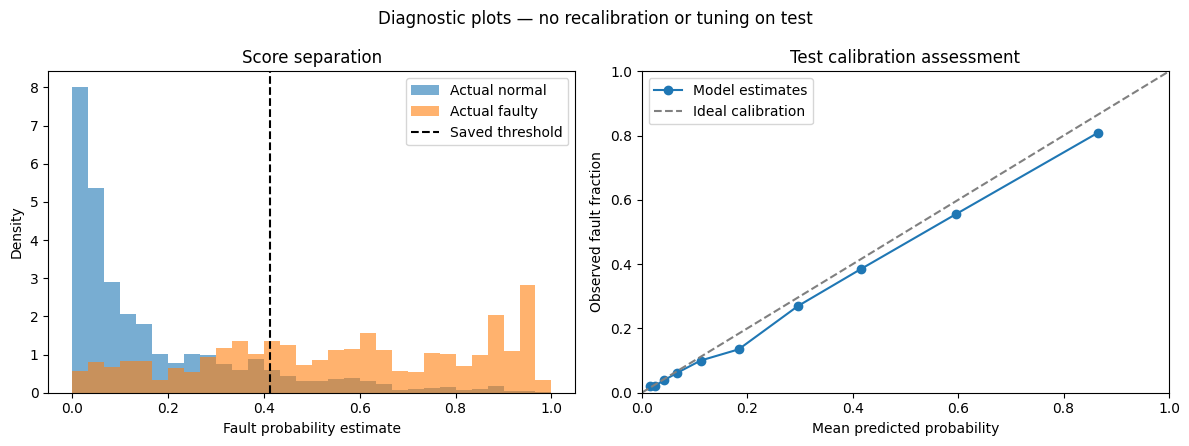

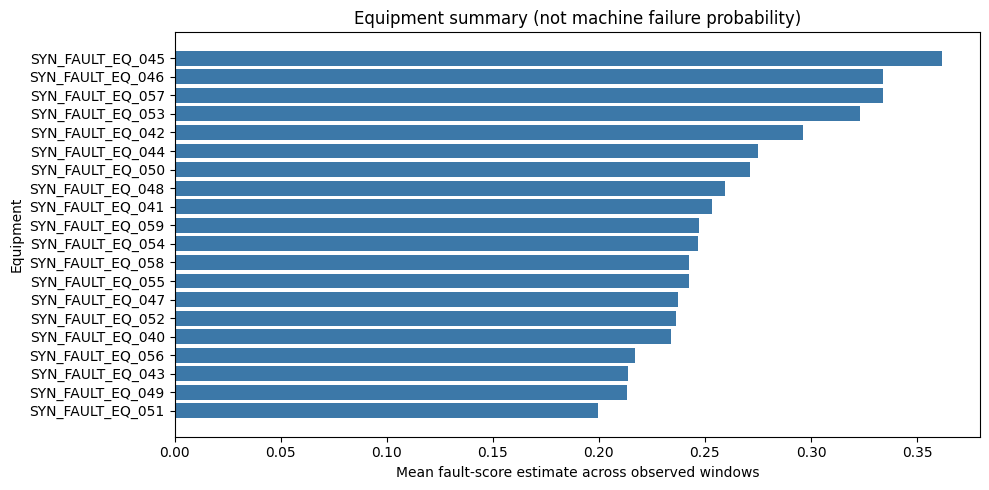

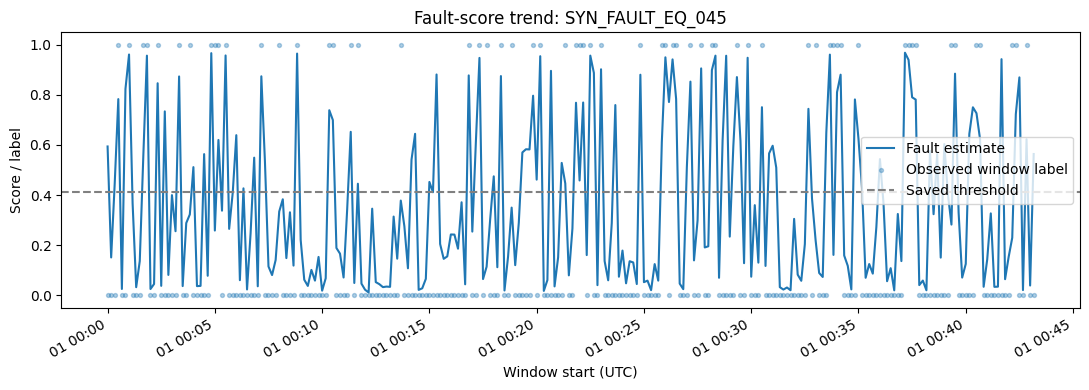

Completed. Results and figures saved to: /content/drive/MyDrive/Port Work/Fault_Mamba_XGBoost_21_Engineered/XGBoost_Fault_Standalone/Results_Visualization


In [ ]:
# Results-only fault visualization. Confusion-matrix, ROC and precision-recall plots omitted.
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,
    confusion_matrix,roc_auc_score,
    average_precision_score,log_loss,brier_score_loss)
from sklearn.calibration import calibration_curve
from google.colab import drive

BASE=Path('/content/drive/MyDrive/Port Work')
# Set this explicitly if you have multiple completed prediction sets.
RESULT_DIR=Path('/content/drive/MyDrive/Port Work/Fault_Mamba_XGBoost_21_Engineered/XGBoost_Fault_Standalone')
if not Path('/content/drive/MyDrive').is_dir(): drive.mount('/content/drive',force_remount=False)
if RESULT_DIR is None:
    candidates=[]
    for name in ['Fault_Mamba_XGBoost_21_Engineered','Fault_Mamba_XGBoost_21_Engineered_Fast']:
        root=BASE/name
        candidates += [root,root/'XGBoost_Fault_Standalone']
    found=[p for p in candidates if (p/'test_fault_predictions.csv').is_file()]
    if len(found)!=1:
        raise ValueError('Set RESULT_DIR to the prediction set you want to visualize. Found: '+str(found))
    RESULT_DIR=found[0]
RESULT_DIR=Path(RESULT_DIR)
OUT=RESULT_DIR/'Results_Visualization';OUT.mkdir(parents=True,exist_ok=True)
df=pd.read_csv(RESULT_DIR/'test_fault_predictions.csv',dtype={'window_id':str,'equipment_id':str})
required=['window_id','equipment_id','true_label','predicted_fault','fault_probability_estimate']
if not set(required).issubset(df): raise ValueError('Missing columns: '+str(set(required)-set(df.columns)))
if df[required].isna().any().any() or df.window_id.duplicated().any(): raise ValueError('Missing or duplicate prediction data')
for col in ['true_label','predicted_fault']:
    if not df[col].isin([0,1]).all(): raise ValueError('Labels and predictions must be binary')
y=df.true_label.to_numpy(dtype=int);pred=df.predicted_fault.to_numpy(dtype=int)
p=pd.to_numeric(df.fault_probability_estimate,errors='raise').to_numpy(dtype=float)
if not np.isfinite(p).all() or np.any((p<0)|(p>1)): raise ValueError('Invalid probability estimates')
if np.bincount(y,minlength=2).tolist()!=[3947,1245]: raise ValueError('Expected 3947 normal + 1245 faulty test windows')
if 'threshold' in df:
    if df.threshold.isna().any() or df.threshold.nunique()!=1: raise ValueError('Expected one saved threshold')
    if not np.array_equal(pred,(p>=float(df.threshold.iloc[0])).astype(int)): raise ValueError('Predictions disagree with scores and threshold')
cm=confusion_matrix(y,pred,labels=[0,1]);tn,fp,fn,tp=map(int,cm.ravel())
metrics={'samples':len(y),'normal':int((y==0).sum()),'faulty':int((y==1).sum()),
    'accuracy':float(accuracy_score(y,pred)),'precision':float(precision_score(y,pred,zero_division=0)),
    'recall':float(recall_score(y,pred,zero_division=0)),'f1':float(f1_score(y,pred,zero_division=0)),
    'specificity':tn/(tn+fp),'false_positive_rate':fp/(tn+fp),
    'roc_auc':float(roc_auc_score(y,p)),'average_precision':float(average_precision_score(y,p)),
    'log_loss':float(log_loss(y,p)),'brier_score':float(brier_score_loss(y,p)),
    'confusion_matrix':cm.tolist()}
(OUT/'test_metrics_recomputed.json').write_text(json.dumps(metrics,indent=2))
print('ACTUAL TEST RESULTS — SYNTHETIC DATA')
print(json.dumps(metrics,indent=2))
metric_names=['accuracy','precision','recall','f1','specificity','roc_auc','average_precision']
metric_table=pd.DataFrame({'metric':metric_names,'value':[metrics[k] for k in metric_names]})
metric_table['percent']=100*metric_table.value
metric_table.to_csv(OUT/'test_metrics_table.csv',index=False)
try:
    from IPython.display import display
    display(metric_table[['metric','percent']].round(2))
except ImportError: print(metric_table.to_string(index=False))
def show_save(fig,name):
    fig.tight_layout();fig.savefig(OUT/name,dpi=200,bbox_inches='tight');plt.show();plt.close(fig)

fig,axes=plt.subplots(1,2,figsize=(12,4.5))
axes[0].hist(p[y==0],bins=np.linspace(0,1,31),density=True,alpha=.6,label='Actual normal')
axes[0].hist(p[y==1],bins=np.linspace(0,1,31),density=True,alpha=.6,label='Actual faulty')
if 'threshold' in df: axes[0].axvline(float(df.threshold.iloc[0]),color='black',ls='--',label='Saved threshold')
axes[0].set(xlabel='Fault probability estimate',ylabel='Density',title='Score separation');axes[0].legend()
observed,estimated=calibration_curve(y,p,n_bins=10,strategy='quantile')
axes[1].plot(estimated,observed,'o-',label='Model estimates')
axes[1].plot([0,1],[0,1],'--',color='gray',label='Ideal calibration')
axes[1].set(xlabel='Mean predicted probability',ylabel='Observed fault fraction',title='Test calibration assessment',xlim=(0,1),ylim=(0,1));axes[1].legend()
fig.suptitle('Diagnostic plots — no recalibration or tuning on test');show_save(fig,'score_and_calibration_diagnostics.png')

# Preserve the original prediction file; save equipment summaries separately.
d=df.copy();d['correct']=(y==pred);d['false_alarm']=(y==0)&(pred==1);d['missed_fault']=(y==1)&(pred==0)
equipment=d.groupby('equipment_id').agg(windows=('window_id','size'),
    actual_fault_windows=('true_label','sum'),predicted_fault_windows=('predicted_fault','sum'),
    mean_fault_estimate=('fault_probability_estimate','mean'),correct_windows=('correct','sum'),
    false_alarms=('false_alarm','sum'),missed_faults=('missed_fault','sum'))
equipment['accuracy']=equipment.correct_windows/equipment.windows
equipment.sort_values('mean_fault_estimate',ascending=False).to_csv(OUT/'equipment_results.csv')
fig,ax=plt.subplots(figsize=(10,5));top=equipment.sort_values('mean_fault_estimate',ascending=False).head(20).iloc[::-1]
ax.barh(top.index,top.mean_fault_estimate,color='#3c78a8');ax.set(xlabel='Mean fault-score estimate across observed windows',ylabel='Equipment',title='Equipment summary (not machine failure probability)')
show_save(fig,'equipment_fault_scores.png')
df.loc[pred==1].sort_values('fault_probability_estimate',ascending=False).to_csv(OUT/'predicted_fault_windows.csv',index=False)
if 'window_start' in df:
    eq=equipment.mean_fault_estimate.idxmax();trend=df.loc[df.equipment_id.eq(eq)].copy()
    trend['time']=pd.to_datetime(trend.window_start,utc=True,errors='raise');trend=trend.sort_values('time')
    fig,ax=plt.subplots(figsize=(11,4));ax.plot(trend.time,trend.fault_probability_estimate,label='Fault estimate')
    ax.scatter(trend.time,trend.true_label,s=8,alpha=.35,label='Observed window label')
    if 'threshold' in df: ax.axhline(float(df.threshold.iloc[0]),ls='--',color='gray',label='Saved threshold')
    ax.set(xlabel='Window start (UTC)',ylabel='Score / label',title=f'Fault-score trend: {eq}',ylim=(-.05,1.05));ax.legend();fig.autofmt_xdate()
    show_save(fig,'equipment_fault_trend.png')
(OUT/'notes.txt').write_text('Calculated from actual saved model predictions on synthetic test data. No training, fixed matrix, fabricated ROC, threshold adjustment, or test-set calibration performed. This is binary fault evaluation, not four-class risk evaluation. Equipment means are descriptive summaries, not machine failure probabilities.\n')
print('Completed. Results and figures saved to:',OUT,flush=True)


Feature folder: /content/drive/MyDrive/Port Work/Fault_Mamba_XGBoost_21_Engineered/Features 
Output: /content/drive/MyDrive/Port Work/Fault_Mamba_XGBoost_21_Engineered/XGBoost_Fault_Standalone
train (20210, 128) Normal/Faulty: [13860, 6350]
validation (2595, 128) Normal/Faulty: [1973, 622]
test (5192, 128) Normal/Faulty: [3947, 1245]

Training candidate 1/3: {'max_depth': 3, 'n_estimators': 200, 'reg_lambda': 5.0}
[0]	validation_0-logloss:0.54759
[25]	validation_0-logloss:0.39651
[50]	validation_0-logloss:0.37727
[75]	validation_0-logloss:0.37534
[100]	validation_0-logloss:0.37577
[125]	validation_0-logloss:0.37609
[150]	validation_0-logloss:0.37650
[175]	validation_0-logloss:0.37670
[199]	validation_0-logloss:0.37685
{'candidate': 0, 'max_depth': 3, 'n_estimators': 200, 'reg_lambda': 5.0, 'validation_log_loss': 0.37685425959926033, 'validation_roc_auc': 0.8655127989921823, 'validation_average_precision': 0.7106532424481482}

Training candidate 2/3: {'max_depth': 4, 'n_estimators': 300

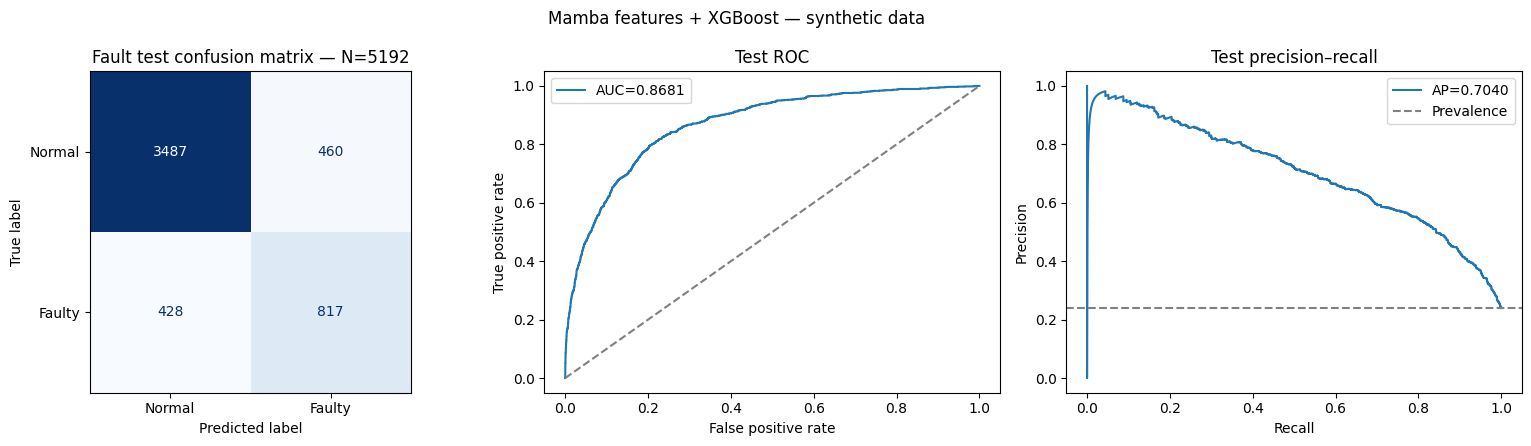

Completed in 8.9s. Saved to: /content/drive/MyDrive/Port Work/Fault_Mamba_XGBoost_21_Engineered/XGBoost_Fault_Standalone
Probabilities are uncalibrated model estimates. Match genuine equipment/time windows before fusion; do not join independent synthetic cohorts by row order.


In [ ]:
# Colab: train XGBoost using completed fault Mamba features. No Mamba retraining.
from pathlib import Path
import json,time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,
    confusion_matrix,ConfusionMatrixDisplay,roc_curve,roc_auc_score,
    precision_recall_curve,average_precision_score,log_loss,brier_score_loss)
try:
    from xgboost import XGBClassifier
except ImportError as exc:
    raise ImportError('Run %pip install xgboost in a separate cell, then rerun.') from exc
from google.colab import drive

BASE=Path('/content/drive/MyDrive/Port Work')
FEATURE_DIR=None  # Set Path('/content/drive/MyDrive/Port Work/YOUR_FOLDER/Features') if ambiguous.
if not Path('/content/drive/MyDrive').is_dir(): drive.mount('/content/drive',force_remount=False)
if FEATURE_DIR is None:
    candidates=[BASE/name/'Features' for name in [
        'Fault_Mamba_XGBoost_21_Engineered','Fault_Mamba_XGBoost_21_Engineered_Fast']]
    complete=[p for p in candidates if all((p/f'{s}_mamba_features.npz').is_file() for s in ['train','validation','test'])]
    if len(complete)!=1:
        raise ValueError('Set FEATURE_DIR explicitly to the completed fault Features folder. Complete folders found: '+str(complete))
    FEATURE_DIR=complete[0]
FEATURE_DIR=Path(FEATURE_DIR)
OUT=FEATURE_DIR.parent/'XGBoost_Fault_Standalone'
OUT.mkdir(parents=True,exist_ok=True)
print('Feature folder:',FEATURE_DIR,'\nOutput:',OUT,flush=True)
EXPECTED={'train':[13860,6350],'validation':[1973,622],'test':[3947,1245]}
D={};seen_ids=set();seen_eq=set();dim=None
for split,counts in EXPECTED.items():
    with np.load(FEATURE_DIR/f'{split}_mamba_features.npz',allow_pickle=False) as a:
        X=a['H'].astype(np.float32);raw=a['y'];ids=a['window_id'].astype(str);eq=a['equipment_id'].astype(str)
    if not np.isin(raw,[0,1]).all(): raise ValueError('Expected labels 0=Normal, 1=Faulty')
    y=raw.astype(np.int64)
    if np.bincount(y,minlength=2).tolist()!=counts: raise ValueError(f'{split}: unexpected class counts')
    if X.ndim!=2 or len(X)!=len(y) or not np.isfinite(X).all(): raise ValueError('Invalid feature matrix')
    if dim is None: dim=X.shape[1]
    if X.shape[1]!=dim: raise ValueError('Feature dimensions differ')
    if len(ids)!=len(y) or len(eq)!=len(y) or len(set(ids))!=len(ids): raise ValueError('Invalid identifiers')
    if seen_ids&set(ids) or seen_eq&set(eq): raise ValueError('Window/equipment overlap across splits')
    seen_ids.update(ids);seen_eq.update(eq)
    meta=pd.DataFrame({'window_id':ids,'equipment_id':eq})
    csv_path=FEATURE_DIR/f'{split}_mamba_features.csv'
    if csv_path.is_file():
        f=pd.read_csv(csv_path,dtype={'window_id':str,'equipment_id':str})
        if f.window_id.duplicated().any() or set(f.window_id)!=set(ids): raise ValueError('CSV identifier mismatch')
        f=f.set_index('window_id').loc[ids]
        if not np.array_equal(f.equipment_id.to_numpy(),eq): raise ValueError('CSV equipment mismatch')
        if 'label' in f and not np.array_equal(f.label.to_numpy(),y): raise ValueError('CSV label mismatch')
        for col in ['window_start','window_end']:
            if col in f: meta[col]=f[col].to_numpy()
    D[split]={'X':X,'y':y,'meta':meta}
    print(split,X.shape,'Normal/Faulty:',counts,flush=True)

# Fixed small search. Training fits models; validation selects; test is not used.
configs=[{'max_depth':3,'n_estimators':200,'reg_lambda':5.},
         {'max_depth':4,'n_estimators':300,'reg_lambda':3.},
         {'max_depth':6,'n_estimators':300,'reg_lambda':1.}]
models=[];search=[];start=time.monotonic()
for i,params in enumerate(configs):
    print(f'\nTraining candidate {i+1}/{len(configs)}: {params}',flush=True)
    model=XGBClassifier(objective='binary:logistic',eval_metric='logloss',tree_method='hist',
        learning_rate=.05,subsample=.8,colsample_bytree=.8,min_child_weight=1,
        n_jobs=2,random_state=42,**params)
    model.fit(D['train']['X'],D['train']['y'],
        eval_set=[(D['validation']['X'],D['validation']['y'])],verbose=25)
    pv=model.predict_proba(D['validation']['X'])[:,1]
    row={'candidate':i,**params,'validation_log_loss':float(log_loss(D['validation']['y'],pv)),
         'validation_roc_auc':float(roc_auc_score(D['validation']['y'],pv)),
         'validation_average_precision':float(average_precision_score(D['validation']['y'],pv))}
    search.append(row);models.append(model);print(row,flush=True)
selected=min(range(len(search)),key=lambda i:search[i]['validation_log_loss'])
model=models[selected]
pv=model.predict_proba(D['validation']['X'])[:,1]
p,r,thresholds=precision_recall_curve(D['validation']['y'],pv)
f1_values=2*p[:-1]*r[:-1]/np.maximum(p[:-1]+r[:-1],1e-12)
threshold=float(thresholds[int(np.argmax(f1_values))])
pd.DataFrame(search).to_csv(OUT/'validation_model_selection.csv',index=False)
model.save_model(OUT/'fault_xgboost.json')
(OUT/'configuration.json').write_text(json.dumps({'selected_candidate':search[selected],
    'model_selection':'minimum validation log loss','threshold':threshold,
    'threshold_selection':'maximum validation F1','input_dimension':dim,
    'input_type':'learned Mamba embeddings; physical/engineered sensor names remain upstream',
    'probabilities_calibrated':False,'data_origin':'synthetic'},indent=2))

metrics={}
for split,item in D.items():
    prob=model.predict_proba(item['X'])[:,1]
    pred=(prob>=threshold).astype(np.int64);y=item['y']
    metrics[split]={'accuracy':float(accuracy_score(y,pred)),
        'precision':float(precision_score(y,pred,zero_division=0)),
        'recall':float(recall_score(y,pred,zero_division=0)),
        'f1':float(f1_score(y,pred,zero_division=0)),
        'roc_auc':float(roc_auc_score(y,prob)),
        'average_precision':float(average_precision_score(y,prob)),
        'log_loss':float(log_loss(y,prob)),
        'brier_score':float(brier_score_loss(y,prob)),
        'confusion_matrix':confusion_matrix(y,pred,labels=[0,1]).tolist()}
    frame=item['meta'].copy();frame['split']=split;frame['true_label']=y
    frame['fault_probability_estimate']=prob;frame['predicted_fault']=pred
    frame['threshold']=threshold;frame['is_synthetic']=True
    frame.to_csv(OUT/f'{split}_fault_predictions.csv',index=False)
    if split=='test': test_y=y;test_prob=prob;test_pred=pred
(OUT/'metrics.json').write_text(json.dumps(metrics,indent=2))
print('\nTEST RESULTS — SYNTHETIC DATA',flush=True)
print(json.dumps(metrics['test'],indent=2),flush=True)
fig,axes=plt.subplots(1,3,figsize=(16,4.5))
ConfusionMatrixDisplay.from_predictions(test_y,test_pred,labels=[0,1],display_labels=['Normal','Faulty'],
    cmap='Blues',colorbar=False,values_format='d',ax=axes[0])
axes[0].set_title('Fault test confusion matrix — N=5192')
fpr,tpr,roc_thresholds=roc_curve(test_y,test_prob)
axes[1].plot(fpr,tpr,label=f"AUC={metrics['test']['roc_auc']:.4f}")
axes[1].plot([0,1],[0,1],'--',color='gray');axes[1].legend()
axes[1].set(xlabel='False positive rate',ylabel='True positive rate',title='Test ROC')
p,r,_=precision_recall_curve(test_y,test_prob)
axes[2].plot(r,p,label=f"AP={metrics['test']['average_precision']:.4f}")
axes[2].axhline(test_y.mean(),ls='--',color='gray',label='Prevalence');axes[2].legend()
axes[2].set(xlabel='Recall',ylabel='Precision',title='Test precision–recall')
fig.suptitle('Mamba features + XGBoost — synthetic data');fig.tight_layout()
fig.savefig(OUT/'test_evaluation.png',dpi=200);plt.show();plt.close(fig)
pd.DataFrame({'false_positive_rate':fpr,'true_positive_rate':tpr,'threshold':roc_thresholds}).to_csv(OUT/'test_roc_points.csv',index=False)
pd.DataFrame({'mamba_feature':[f'Mamba_Feature_{i+1:03d}' for i in range(dim)],
    'xgboost_gain_importance':model.feature_importances_}).sort_values('xgboost_gain_importance',ascending=False).to_csv(OUT/'mamba_embedding_importance.csv',index=False)
print(f'Completed in {time.monotonic()-start:.1f}s. Saved to: {OUT}',flush=True)
print('Probabilities are uncalibrated model estimates. Match genuine equipment/time windows before fusion; do not join independent synthetic cohorts by row order.')


Feature folder: /content/drive/MyDrive/Port Work/Fault_Mamba_XGBoost_21_Engineered/Features 
Fault predictions: /content/drive/MyDrive/Port Work/Fault_Mamba_XGBoost_21_Engineered/XGBoost_Fault_Standalone
Loaded train (20210, 128)
Loaded validation (2595, 128)
Loaded test (5192, 128)
Shared AE epoch 1: train=0.455915, holdout=0.293392
Shared AE epoch 2: train=0.280188, holdout=0.211843
Shared AE epoch 3: train=0.232592, holdout=0.193781
Shared AE epoch 4: train=0.209278, holdout=0.193062
Shared AE epoch 5: train=0.188467, holdout=0.181996
Shared AE epoch 6: train=0.179930, holdout=0.179807
Shared AE epoch 7: train=0.183079, holdout=0.174821
Shared AE epoch 8: train=0.169694, holdout=0.171876
Shared AE epoch 9: train=0.157980, holdout=0.162347
Shared AE epoch 10: train=0.152382, holdout=0.160428
Shared AE epoch 11: train=0.145716, holdout=0.151893
Shared AE epoch 12: train=0.140506, holdout=0.158379
Shared AE epoch 13: train=0.137309, holdout=0.144468
Shared AE epoch 14: train=0.128833, 

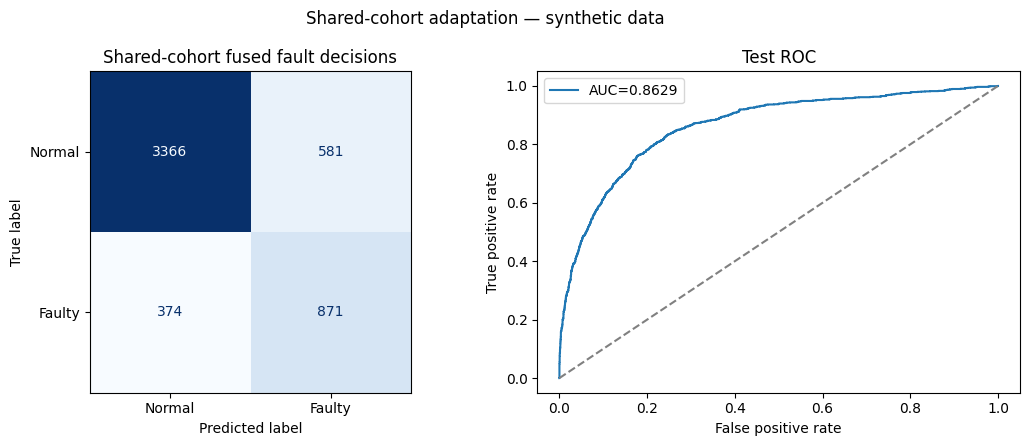

{
  "accuracy": 0.8160631741140215,
  "precision": 0.599862258953168,
  "recall": 0.6995983935742972,
  "f1": 0.6459028550241008,
  "roc_auc": 0.8628905284171905,
  "average_precision": 0.7022962257384542,
  "brier_score": 0.11825439326044399,
  "log_loss": 0.37833581082984485,
  "confusion_matrix": [
    [
      3366,
      581
    ],
    [
      374,
      871
    ]
  ]
}
Completed: /content/drive/MyDrive/Port Work/Fault_Mamba_XGBoost_21_Engineered/Shared_Cohort_Fusion_Risk
Four risk levels are policy bands, not independently validated severity outcomes.


In [ ]:
# Shared-cohort adaptation: new AE on FAULT Mamba embeddings + existing XGBoost evidence.
# Does not reuse the independent anomaly dataset or require prebuilt Fusion_Input CSVs.
# Existing validation data become fusion development data. Final test is not fitted on.
from pathlib import Path
import json,random,time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader,TensorDataset
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score,average_precision_score,precision_recall_curve,
    roc_curve,accuracy_score,precision_score,recall_score,f1_score,brier_score_loss,
    log_loss,confusion_matrix,ConfusionMatrixDisplay)
import joblib
from google.colab import drive

BASE=Path('/content/drive/MyDrive/Port Work')
FEATURE_DIR=None  # Set explicitly if more than one complete fault Features folder exists.
FAULT_RESULTS=None  # Set explicitly if more than one saved prediction set exists.
SEED=42;random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED)
if not Path('/content/drive/MyDrive').is_dir(): drive.mount('/content/drive',force_remount=False)
if FEATURE_DIR is None:
    roots=[BASE/'Fault_Mamba_XGBoost_21_Engineered',BASE/'Fault_Mamba_XGBoost_21_Engineered_Fast']
    found=[p/'Features' for p in roots if all((p/'Features'/f'{s}_mamba_features.npz').is_file() for s in ['train','validation','test'])]
    if len(found)!=1: raise ValueError('Set FEATURE_DIR to the completed fault Features folder. Found: '+str(found))
    FEATURE_DIR=found[0]
FEATURE_DIR=Path(FEATURE_DIR)
if FAULT_RESULTS is None:
    candidates=[FEATURE_DIR.parent/'XGBoost_Fault_Standalone',FEATURE_DIR.parent]
    found=[p for p in candidates if all((p/f'{s}_fault_predictions.csv').is_file() for s in ['validation','test'])]
    if not found: raise FileNotFoundError('Run XGBoost training first; no fault predictions found.')
    # Prefer standalone XGBoost outputs when both exist.
    FAULT_RESULTS=found[0]
FAULT_RESULTS=Path(FAULT_RESULTS)
OUT=FEATURE_DIR.parent/'Shared_Cohort_Fusion_Risk';OUT.mkdir(parents=True,exist_ok=True)
print('Feature folder:',FEATURE_DIR,'\nFault predictions:',FAULT_RESULTS,flush=True)
D={};seen=set();seen_eq=set();dim=None
for split,counts in {'train':[13860,6350],'validation':[1973,622],'test':[3947,1245]}.items():
    with np.load(FEATURE_DIR/f'{split}_mamba_features.npz',allow_pickle=False) as a:
        h=a['H'].astype(np.float32);raw=a['y'];ids=a['window_id'].astype(str);eq=a['equipment_id'].astype(str)
    if not np.isin(raw,[0,1]).all(): raise ValueError('Invalid fault labels')
    y=raw.astype(int)
    if h.ndim!=2 or len(h)!=len(y) or not np.isfinite(h).all() or np.bincount(y,minlength=2).tolist()!=counts: raise ValueError('Invalid feature matrix/counts')
    if dim is None: dim=h.shape[1]
    if h.shape[1]!=dim or len(ids)!=len(y) or len(eq)!=len(y) or len(set(ids))!=len(ids): raise ValueError('Dimension/ID mismatch')
    if seen&set(ids) or seen_eq&set(eq): raise ValueError('Cross-split equipment/window leakage')
    seen.update(ids);seen_eq.update(eq)
    meta=pd.DataFrame({'window_id':ids,'equipment_id':eq})
    if split!='train':
        f=pd.read_csv(FAULT_RESULTS/f'{split}_fault_predictions.csv',dtype={'window_id':str,'equipment_id':str})
        if f.window_id.duplicated().any() or set(f.window_id)!=set(ids): raise ValueError('Fault prediction IDs mismatch')
        f=f.set_index('window_id').loc[ids].reset_index()
        if not np.array_equal(f.equipment_id.to_numpy(),eq) or not np.array_equal(f.true_label.to_numpy(),y): raise ValueError('Fault prediction labels/equipment mismatch')
        p=f.fault_probability_estimate.to_numpy(dtype=float)
        if not np.isfinite(p).all() or np.any((p<0)|(p>1)): raise ValueError('Invalid fault probability')
        for col in ['window_start','window_end']:
            if col in f: meta[col]=f[col].to_numpy()
    else: p=None
    D[split]={'H':h,'y':y,'meta':meta,'p':p}
    print('Loaded',split,h.shape,flush=True)

# Train the NEW shared-cohort anomaly head on normal fault-training embeddings.
normal_indices=np.flatnonzero(D['train']['y']==0)
normal_groups=D['train']['meta'].equipment_id.to_numpy()[normal_indices]
a,b=next(GroupShuffleSplit(n_splits=1,test_size=.2,random_state=SEED).split(normal_indices,groups=normal_groups))
fit_idx=normal_indices[a];stop_idx=normal_indices[b]
scaler=StandardScaler().fit(D['train']['H'][fit_idx])
joblib.dump(scaler,OUT/'anomaly_embedding_scaler.joblib')
zfit=scaler.transform(D['train']['H'][fit_idx]).astype(np.float32)
zstop=scaler.transform(D['train']['H'][stop_idx]).astype(np.float32)
class AE(nn.Module):
    def __init__(self):
        super().__init__()
        self.net=nn.Sequential(nn.Linear(dim,64),nn.ReLU(),nn.Linear(64,32),nn.ReLU(),nn.Linear(32,16),nn.Linear(16,32),nn.ReLU(),nn.Linear(32,64),nn.ReLU(),nn.Linear(64,dim))
    def forward(self,x): return self.net(x)
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model=AE().to(device);optimizer=torch.optim.Adam(model.parameters(),lr=.001)
fit=DataLoader(TensorDataset(torch.from_numpy(zfit)),batch_size=128,shuffle=True)
stop=DataLoader(TensorDataset(torch.from_numpy(zstop)),batch_size=128)
best=float('inf');stale=0;history=[]
for epoch in range(1,51):
    losses=[]
    for training,batches in [(True,fit),(False,stop)]:
        model.train(training);total=0.;n=0
        for (batch,) in batches:
            batch=batch.to(device)
            with torch.set_grad_enabled(training):
                loss=((model(batch)-batch)**2).mean()
                if not torch.isfinite(loss): raise ValueError('Nonfinite AE loss')
                if training:
                    optimizer.zero_grad(set_to_none=True);loss.backward();optimizer.step()
            total+=loss.item()*len(batch);n+=len(batch)
        losses.append(total/n)
    history.append({'epoch':epoch,'train_mse':losses[0],'normal_training_holdout_mse':losses[1]})
    print(f'Shared AE epoch {epoch}: train={losses[0]:.6f}, holdout={losses[1]:.6f}',flush=True)
    if losses[1]<best:
        best=losses[1];stale=0;torch.save(model.state_dict(),OUT/'shared_autoencoder.pt')
    else:
        stale+=1
        if stale>=7: break
pd.DataFrame(history).to_csv(OUT/'shared_ae_history.csv',index=False)
model.load_state_dict(torch.load(OUT/'shared_autoencoder.pt',map_location=device,weights_only=True));model.eval()
def score(h):
    z=scaler.transform(h).astype(np.float32);parts=[]
    with torch.no_grad():
        for i in range(0,len(z),256):
            x=torch.from_numpy(z[i:i+256]).to(device);parts.append(((model(x)-x)**2).mean(1).cpu().numpy())
    s=np.concatenate(parts)
    if not np.isfinite(s).all(): raise ValueError('Nonfinite anomaly scores')
    return s
reference=np.sort(score(D['train']['H'][stop_idx]))
def evidence(item):
    mse=score(item['H']);a=np.searchsorted(reference,mse,side='right')/len(reference)
    p=item['p'];return np.column_stack([a,p,a*p]),mse
# Both scores now concern the SAME fault embedding rows; no unrelated IDs are joined.
v=D['validation'];V,vmse=evidence(v)
fit_v,tune_v=next(GroupShuffleSplit(n_splits=1,test_size=.5,random_state=SEED).split(V,groups=v['meta'].equipment_id))
if len(np.unique(v['y'][fit_v]))<2 or len(np.unique(v['y'][tune_v]))<2: raise ValueError('Both fusion-development partitions need both fault classes')
fusion=make_pipeline(StandardScaler(),LogisticRegression(max_iter=2000,random_state=SEED))
fusion.fit(V[fit_v],v['y'][fit_v])
pt=fusion.predict_proba(V[tune_v])[:,1]
p,r,t=precision_recall_curve(v['y'][tune_v],pt);f=2*p[:-1]*r[:-1]/np.maximum(p[:-1]+r[:-1],1e-12)
threshold=float(t[int(np.argmax(f))])
joblib.dump({'fusion':fusion,'normal_reference_mse':reference,'threshold':threshold,'input_order':['normal_reference_percentile','fault_probability','interaction']},OUT/'fusion_model.joblib')
for role,idx in [('fusion_fit',fit_v),('threshold_tuning',tune_v)]:
    v['meta'].iloc[idx].to_csv(OUT/f'{role}_manifest.csv',index=False)
results={}
for split in ['validation','test']:
    item=D[split]
    X,mse=(V,vmse) if split=='validation' else evidence(item)
    prob=fusion.predict_proba(X)[:,1];pred=(prob>=threshold).astype(int);y=item['y']
    levels=np.array(['Low','Moderate','High','Critical'])[np.digitize(prob,[.25,.5,.75])]
    frame=item['meta'].copy();frame['true_fault']=y;frame['anomaly_score_mse']=mse
    frame['fault_probability_estimate']=item['p'];frame['fused_fault_probability_estimate']=prob
    frame['predicted_fault']=pred;frame['risk_level']=levels;frame['is_synthetic']=True
    if split=='validation':
        roles=np.full(len(y),'threshold_tuning',dtype=object);roles[fit_v]='fusion_fit';frame['development_role']=roles
    frame.to_csv(OUT/f'{split}_risk_predictions.csv',index=False)
    # Only test is final evaluation; validation was used for fitting/tuning.
    if split=='test':
        metrics={'accuracy':float(accuracy_score(y,pred)),'precision':float(precision_score(y,pred,zero_division=0)),
            'recall':float(recall_score(y,pred,zero_division=0)),'f1':float(f1_score(y,pred,zero_division=0)),
            'roc_auc':float(roc_auc_score(y,prob)),'average_precision':float(average_precision_score(y,prob)),
            'brier_score':float(brier_score_loss(y,prob)),'log_loss':float(log_loss(y,prob)),
            'confusion_matrix':confusion_matrix(y,pred,labels=[0,1]).tolist()}
        yp=y;pp=prob;pd_=pred
(OUT/'test_metrics.json').write_text(json.dumps(metrics,indent=2))
(OUT/'method_notes.json').write_text(json.dumps({'synthetic':True,'adaptation':'new Autoencoder on normal fault Mamba embeddings; independent original anomaly branch not reused',
    'fusion_training':'half of existing validation equipment; other half chooses threshold',
    'limitation':'existing validation may already have guided upstream model selection; this is not an independent calibration experiment',
    'test':'no fitting/tuning performed here on test','risk_bands':'proposed .25/.50/.75 bands, not verified four-class labels',
    'probabilities':'estimates; no guarantee of calibration','anomaly_reference':'normal fault-training holdout MSE percentile, not anomaly probability'},indent=2))
fig,axes=plt.subplots(1,2,figsize=(11,4.5))
ConfusionMatrixDisplay.from_predictions(yp,pd_,labels=[0,1],display_labels=['Normal','Faulty'],ax=axes[0],cmap='Blues',colorbar=False)
axes[0].set_title('Shared-cohort fused fault decisions')
fpr,tpr,_=roc_curve(yp,pp);axes[1].plot(fpr,tpr,label=f"AUC={metrics['roc_auc']:.4f}")
axes[1].plot([0,1],[0,1],'--',color='gray');axes[1].legend();axes[1].set(xlabel='False positive rate',ylabel='True positive rate',title='Test ROC')
fig.suptitle('Shared-cohort adaptation — synthetic data');fig.tight_layout();fig.savefig(OUT/'fusion_test.png',dpi=200);plt.show();plt.close(fig)
print(json.dumps(metrics,indent=2));print('Completed:',OUT,flush=True)
print('Four risk levels are policy bands, not independently validated severity outcomes.')


Mounted at /content/drive
Reading: /content/drive/MyDrive/Port Work/Fault_Mamba_XGBoost_21_Engineered/Shared_Cohort_Fusion_Risk


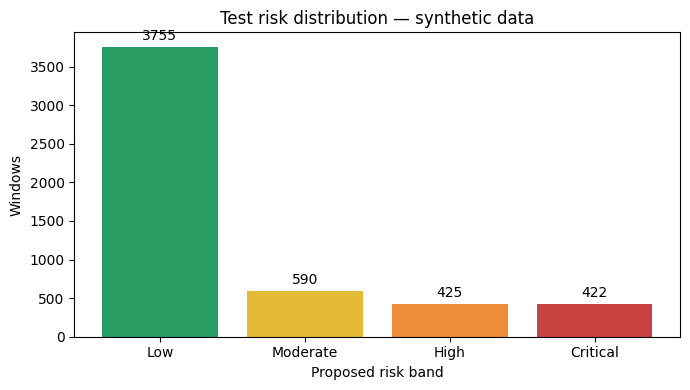

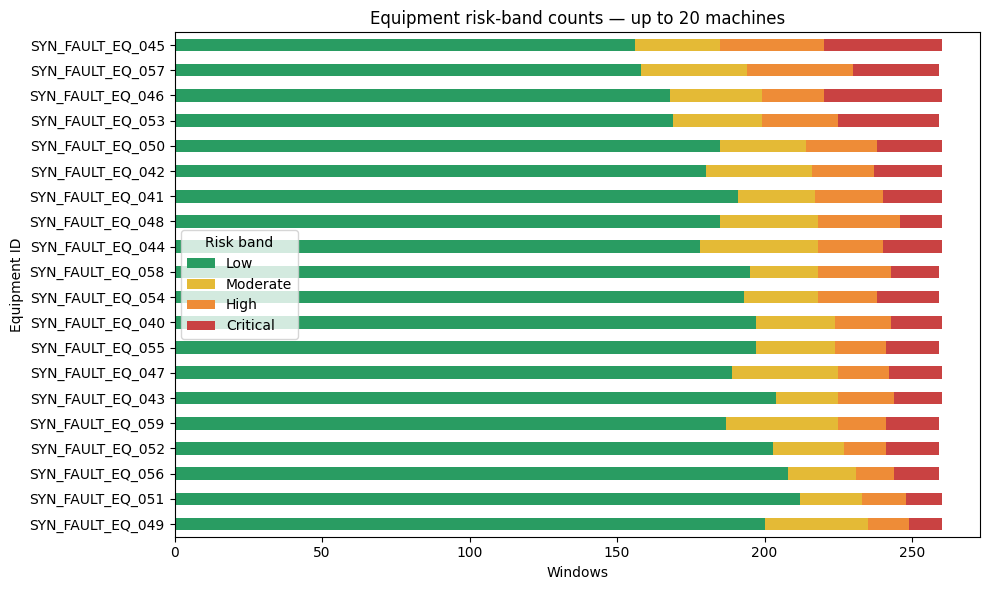

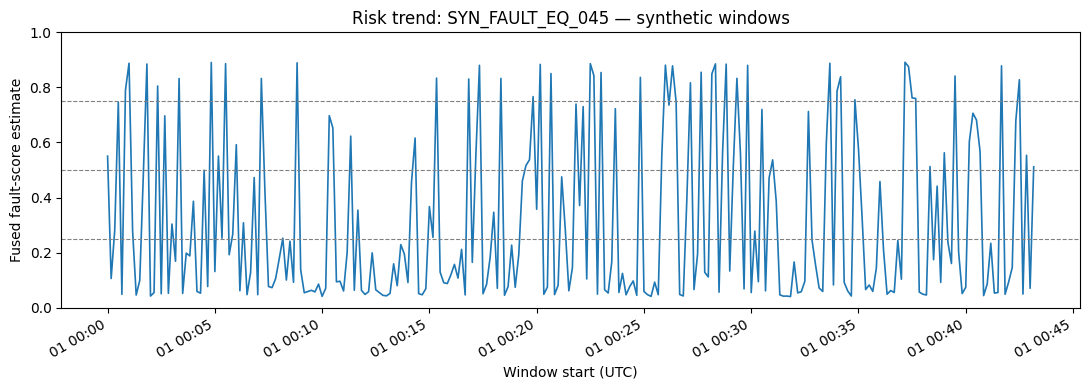

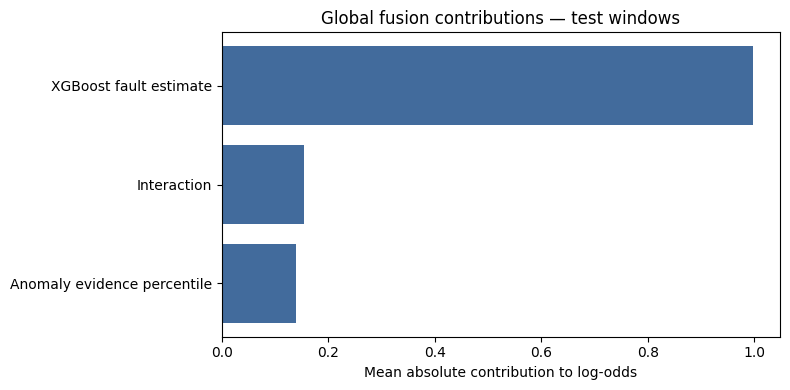

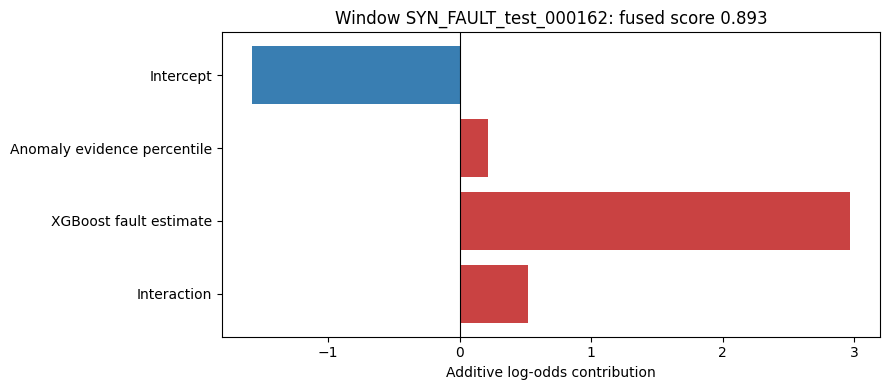


Risk distribution:
risk_level  windows  percentage
       Low     3755   72.322804
  Moderate      590   11.363636
      High      425    8.185670
  Critical      422    8.127889

Highest-priority equipment summaries:
                  windows  mean_risk_score  max_risk_score  Low  Moderate  High  Critical  high_or_critical_fraction
equipment_id                                                                                                        
SYN_FAULT_EQ_045      260         0.311425        0.891359  156        29    35        40                   0.288462
SYN_FAULT_EQ_057      259         0.284522        0.892561  158        36    36        29                   0.250965
SYN_FAULT_EQ_046      260         0.281220        0.890976  168        31    21        40                   0.234615
SYN_FAULT_EQ_053      259         0.271919        0.890644  169        30    26        34                   0.231660
SYN_FAULT_EQ_050      260         0.231417        0.889894  185        29    24

In [ ]:
# Colab: visualize and explain the completed Shared_Cohort_Fusion_Risk model.
# Exact linear-logit decomposition of the saved sigmoid fusion layer; not sensor-level SHAP.
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from google.colab import drive

BASE=Path('/content/drive/MyDrive/Port Work')
RESULT_DIR=None  # Set explicitly if both standard and fast fusion runs exist.
RISK_ORDER=['Low','Moderate','High','Critical']
COLORS=['#299c62','#e4ba36','#ee8c37','#c94242']
if not Path('/content/drive/MyDrive').is_dir(): drive.mount('/content/drive',force_remount=False)
if RESULT_DIR is None:
    candidates=[BASE/name/'Shared_Cohort_Fusion_Risk' for name in [
        'Fault_Mamba_XGBoost_21_Engineered','Fault_Mamba_XGBoost_21_Engineered_Fast']]
    complete=[p for p in candidates if (p/'test_risk_predictions.csv').is_file() and (p/'fusion_model.joblib').is_file()]
    if len(complete)!=1: raise ValueError('Set RESULT_DIR to your completed fusion folder. Found: '+str(complete))
    RESULT_DIR=complete[0]
RESULT_DIR=Path(RESULT_DIR);OUT=RESULT_DIR/'Risk_Visualization_Explainability'
OUT.mkdir(parents=True,exist_ok=True)
print('Reading:',RESULT_DIR,flush=True)
df=pd.read_csv(RESULT_DIR/'test_risk_predictions.csv',dtype={'window_id':str,'equipment_id':str})
required=['window_id','equipment_id','anomaly_score_mse','fault_probability_estimate','fused_fault_probability_estimate','risk_level']
if not set(required).issubset(df): raise ValueError('Missing columns: '+str(set(required)-set(df.columns)))
if df[required].isna().any().any() or df.window_id.duplicated().any() or len(df)==0: raise ValueError('Missing or duplicate data')
for col in ['anomaly_score_mse','fault_probability_estimate','fused_fault_probability_estimate']:
    df[col]=pd.to_numeric(df[col],errors='raise')
    if not np.isfinite(df[col]).all(): raise ValueError('Nonfinite '+col)
if (df.anomaly_score_mse<0).any(): raise ValueError('Negative MSE')
for col in ['fault_probability_estimate','fused_fault_probability_estimate']:
    if not df[col].between(0,1).all(): raise ValueError('Probability outside [0,1]')
expected=np.array(RISK_ORDER)[np.digitize(df.fused_fault_probability_estimate.to_numpy(),[.25,.5,.75])]
if not np.array_equal(expected,df.risk_level.to_numpy()): raise ValueError('Risk labels disagree with the original .25/.50/.75 band policy')

def save_show(fig,name):
    fig.tight_layout();fig.savefig(OUT/name,dpi=200,bbox_inches='tight');plt.show();plt.close(fig)

# 1. Risk distribution.
counts=df.risk_level.value_counts().reindex(RISK_ORDER,fill_value=0)
summary=pd.DataFrame({'risk_level':RISK_ORDER,'windows':counts.values,'percentage':100*counts.values/len(df)})
summary.to_csv(OUT/'risk_distribution.csv',index=False)
fig,ax=plt.subplots(figsize=(7,4));bars=ax.bar(RISK_ORDER,counts.values,color=COLORS)
ax.bar_label(bars,padding=3);ax.set(xlabel='Proposed risk band',ylabel='Windows',title='Test risk distribution — synthetic data')
save_show(fig,'risk_distribution.png')

# 2. Equipment summaries use all windows; maximum score is descriptive, not a policy.
equipment=df.groupby('equipment_id').agg(windows=('window_id','size'),mean_risk_score=('fused_fault_probability_estimate','mean'),max_risk_score=('fused_fault_probability_estimate','max'))
by_band=pd.crosstab(df.equipment_id,df.risk_level).reindex(columns=RISK_ORDER,fill_value=0)
equipment=equipment.join(by_band).fillna(0)
equipment['high_or_critical_fraction']=(equipment['High']+equipment['Critical'])/equipment.windows
equipment=equipment.sort_values(['high_or_critical_fraction','max_risk_score'],ascending=False)
equipment.to_csv(OUT/'equipment_risk_summary.csv')
top=equipment.head(20)
fig,ax=plt.subplots(figsize=(10,6))
top[RISK_ORDER].iloc[::-1].plot.barh(stacked=True,color=COLORS,ax=ax)
ax.set(xlabel='Windows',ylabel='Equipment ID',title='Equipment risk-band counts — up to 20 machines');ax.legend(title='Risk band')
save_show(fig,'equipment_risk_counts.png')
alerts=df.loc[df.risk_level.isin(['High','Critical'])].sort_values('fused_fault_probability_estimate',ascending=False)
alerts.to_csv(OUT/'high_critical_windows_for_review.csv',index=False)

# 3. Risk over time, per machine. Do not connect different equipment into one time series.
if 'window_start' in df:
    df['parsed_time']=pd.to_datetime(df.window_start,utc=True,errors='raise')
    chosen=equipment.index[0]
    trend=df.loc[df.equipment_id.eq(chosen)].sort_values('parsed_time')
    fig,ax=plt.subplots(figsize=(11,4));ax.plot(trend.parsed_time,trend.fused_fault_probability_estimate,lw=1.2)
    for threshold in [.25,.5,.75]: ax.axhline(threshold,color='gray',ls='--',lw=.8)
    ax.set(xlabel='Window start (UTC)',ylabel='Fused fault-score estimate',ylim=(0,1),title=f'Risk trend: {chosen} — synthetic windows')
    fig.autofmt_xdate();save_show(fig,'equipment_risk_trend.png')
else:
    print('Timestamp column absent: time-trend plot skipped.',flush=True)

# 4. Exact fusion explanation. Load only your own trusted joblib model.
bundle=joblib.load(RESULT_DIR/'fusion_model.joblib')
fusion=bundle['fusion'];reference=np.asarray(bundle['normal_reference_mse'])
if reference.ndim!=1 or len(reference)==0 or not np.isfinite(reference).all() or np.any(np.diff(reference)<0): raise ValueError('Invalid normal-score reference')
a=np.searchsorted(reference,df.anomaly_score_mse.to_numpy(),side='right')/len(reference)
p=df.fault_probability_estimate.to_numpy()
X=np.column_stack([a,p,a*p])
names=['Anomaly evidence percentile','XGBoost fault estimate','Interaction']
if bundle.get('input_order')!=['normal_reference_percentile','fault_probability','interaction']: raise ValueError('Unexpected fusion input order')
scale=fusion.named_steps['standardscaler'];linear=fusion.named_steps['logisticregression']
Z=scale.transform(X)
contributions=Z*linear.coef_[0]
intercept=float(linear.intercept_[0])
logits=intercept+contributions.sum(axis=1)
from scipy.special import expit
reconstructed=expit(logits)
model_p=fusion.predict_proba(X)[:,1]
np.testing.assert_allclose(reconstructed,model_p,rtol=1e-7,atol=1e-8)
np.testing.assert_allclose(model_p,df.fused_fault_probability_estimate.to_numpy(),rtol=1e-4,atol=1e-6,
    err_msg='Saved predictions do not match this model. Use the model from the same completed run.')

# Positive terms raise log-odds relative to the standardized-zero reference; negative lower them.
explanations=df[['window_id','equipment_id','risk_level']].copy()
explanations['anomaly_reference_percentile']=a
for j,label in enumerate(['anomaly','fault','interaction']):
    explanations[label+'_logit_contribution']=contributions[:,j]
explanations['intercept_logit']=intercept
explanations['reconstructed_fused_probability']=reconstructed
explanations.to_csv(OUT/'window_fusion_explanations.csv',index=False)
importance=np.abs(contributions).mean(axis=0)
importance_table=pd.DataFrame({'fusion_input':names,'mean_absolute_logit_contribution':importance})
importance_table.to_csv(OUT/'global_fusion_contribution.csv',index=False)
fig,ax=plt.subplots(figsize=(8,4));order=np.argsort(importance)
ax.barh(np.array(names)[order],importance[order],color='#426b9c')
ax.set(xlabel='Mean absolute contribution to log-odds',title='Global fusion contributions — test windows')
save_show(fig,'global_fusion_contributions.png')

# Explain the highest-scoring test window without changing its prediction.
i=int(np.argmax(model_p));values=np.r_[intercept,contributions[i]]
labels=['Intercept']+names
fig,ax=plt.subplots(figsize=(9,4))
ax.barh(labels[::-1],values[::-1],color=['#c94242' if v>0 else '#397eb2' for v in values[::-1]])
ax.axvline(0,color='black',lw=.8)
ax.set(xlabel='Additive log-odds contribution',title=f"Window {df.iloc[i].window_id}: fused score {model_p[i]:.3f}")
save_show(fig,'highest_score_local_explanation.png')
notes={'data_origin':'synthetic','risk_bands':'proposed thresholds, not independent ground-truth severity classes',
    'explanation':'exact standardized linear-logit decomposition of the learned sigmoid fusion model',
    'identity':'sigmoid(intercept + anomaly contribution + fault contribution + interaction contribution)',
    'units':'log-odds; these contributions do not add directly as probabilities',
    'reference':'zero standardized inputs; NOT a SHAP expected-value reference',
    'limits':'predictive association, not causal effect; not sensor-level feature importance; interaction depends on both branch inputs',
    'equipment_summary':'counts/mean/max describe observed windows; no machine-level failure probability is asserted',
    'highest_score_window_id':str(df.iloc[i].window_id)}
(OUT/'explanation_notes.json').write_text(json.dumps(notes,indent=2))
print('\nRisk distribution:');print(summary.to_string(index=False))
print('\nHighest-priority equipment summaries:');print(equipment.head(10).to_string())
print('\nHigh/critical windows:',len(alerts),'of',len(df))
print('Exact explanation reconstruction verified.')
print('Completed. Saved to:',OUT,flush=True)
